# Análisis Exploratorio de Datos (EDA) — Resultados de Análisis de Laboratorio de Suelos en Colombia (AGROSAVIA)
## Etapa 1: Justificación, Diagnóstico Exhaustivo y Limpieza de Datos

### 1. Justificación y ficha técnica del conjunto de datos

* **Entidad productora y fuente:** Corporación Colombiana de Investigación Agropecuaria (**AGROSAVIA**), publicado en el portal oficial **Datos Abiertos Colombia** (`datos.gov.co`).
* **URL oficial:** <https://www.datos.gov.co/Agricultura-y-Desarrollo-Rural/Resultados-de-An-lisis-de-Laboratorio-Suelos-en-Co/ch4u-f3i5/about_data>
* **Licencia declarada:** `Creative Commons Attribution | Share Alike 4.0 International` (CC BY-SA 4.0).
* **Archivo local utilizado:** `data_raw/Resultados_de_Análisis_de_Laboratorio_Suelos_en_Colombia_20261123.csv` (26.39 MB).
* **Dimensiones iniciales:** **92,738 filas × 32 columnas**, con cobertura nacional en los **32 departamentos de Colombia y Bogotá, D.C.**, recopilando análisis de laboratorio registrados entre **enero de 2014 y septiembre de 2025**. El conjunto supera ampliamente los criterios mínimos de la rúbrica (> 200 filas y > 8 columnas), combina variables temporales, geográficas, agronómicas y 21 determinaciones fisicoquímicas, y presenta imperfecciones reales propias de registros de laboratorio.

#### Pertinencia en ciencias biológicas y edafología
El suelo constituye la interfaz biogeoquímica fundamental entre la litosfera, la atmósfera, la hidrosfera y la biosfera. En sistemas agroecológicos tropicales como los de Colombia, parámetros como el **pH agua:suelo**, la **acidez y el aluminio intercambiable** (determinantes de toxicidad alumínica y disponibilidad de fósforo en suelos ácidos), la **materia orgánica** (reservorio principal de carbono edáfico y sustrato energético para la microbiota del suelo), la **capacidad de intercambio catiónico (CIC)**, la **conductividad eléctrica** (indicadora de salinidad/sodicidad) y la disponibilidad de macronutrientes ($\text{P}, \text{S}, \text{Ca}, \text{Mg}, \text{K}$) y micronutrientes ($\text{Fe}, \text{Cu}, \text{Mn}, \text{Zn}, \text{B}$) permiten caracterizar la fertilidad potencial, las limitantes fisiológicas para distintos cultivos y la heterogeneidad espacial y temporal de los agroecosistemas colombianos.

#### Herramientas y declaración de transparencia
* **Librerías de análisis:** Todo el diagnóstico, limpieza y transformación se ejecuta exclusivamente con `pandas` (con soporte de `numpy`, `re` y `unicodedata` de Python para expresiones regulares y normalización Unicode) sobre un entorno virtual reproducible (`.venv`, Python 3.14). En etapas posteriores se utilizarán `matplotlib` y `seaborn` para las visualizaciones obligatorias.
* **Declaración de uso de IA:** Conforme a las instrucciones de la prueba, se declara el uso de un asistente de inteligencia artificial como apoyo para organizar las secciones del cuaderno, redactar y depurar código en `pandas` y pulir la redacción. Todas las decisiones edafológicas, reglas de limpieza aplicadas e interpretaciones fueron definidas y verificadas directamente por el autor sobre los datos reales del archivo CSV.

---
## 2. Carga inicial y diagnóstico exhaustivo con `pandas`

### 2.1 Carga, codificación y auditoría de encabezados
Antes de leer el archivo con `pandas`, se verifica el tamaño en disco, la presencia o ausencia de BOM (*Byte Order Mark*) UTF-8 y los primeros registros en bruto. Se carga explícitamente **sin** el parámetro `thousands=','` porque, como se demostrará en la sección 2.2, la coma `,` cumple dos roles opuestos dentro del mismo archivo (separador de miles en `Secuencial` y separador decimal en micronutrientes por doble ácido).

In [1]:
import os
import re
import unicodedata
import difflib
import numpy as np
import pandas as pd

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 140)

RAW_PATH = 'data_raw/Resultados_de_Análisis_de_Laboratorio_Suelos_en_Colombia_20261123.csv'
PROCESSED_PATH = 'data_processed/suelos_limpios.csv'

file_bytes = os.path.getsize(RAW_PATH)
with open(RAW_PATH, 'rb') as f:
    raw_head = f.read(600)

print(f'Tamaño del archivo: {file_bytes:,} bytes ({file_bytes / (1024**2):.2f} MB)')
print('Primeros 6 bytes (verificación de BOM UTF-8):', raw_head[:6])

df_raw = pd.read_csv(RAW_PATH, low_memory=False)
print(f'Dimensiones iniciales (df_raw): {df_raw.shape[0]:,} filas x {df_raw.shape[1]} columnas')
display(df_raw.head(5))

Tamaño del archivo: 26,390,661 bytes (25.17 MB)
Primeros 6 bytes (verificación de BOM UTF-8): b'"Secue'


Dimensiones iniciales (df_raw): 92,738 filas x 32 columnas


,Secuencial,Fecha de Análisis,Departamento,Municipio,Cultivo,Estado,Tiempo de establecimiento,Topografia,Drenaje,Riego,Fertilizantes aplicados,pH agua:suelo,Materia organica,Fósforo Bray II,Azufre Fosfato monocalcico,Acidez Intercambiable,Aluminio intercambiable,Calcio intercambiable,Magnesio intercambiable,Potasio intercambiable,Sodio intercambiable,capacidad de intercambio cationico,Conductividad electrica,Hierro disponible olsen,Cobre disponible,Manganeso disponible Olsen,Zinc disponible Olsen,Boro disponible,Hierro disponible doble acido,Cobre disponible doble acido,Manganeso disponible doble acido,Zinc disponible doble acido
0,1,7/01/2014,NARIÑO,SAN ANDRÉS DE TUMACO,No Indica,No indica,No indica,No indica,No indica,No indica,No indica,5.64,3.889,6.482,8.384,ND,ND,1.541,0.380,0.118,0.054,2.094,0.133,66.39,1.700,1.700,1.5,0.187,ND,ND,ND,ND
1,2,21/08/2014,HUILA,SANTA MARÍA,Granadilla,Establecido,De 1 a 5 años,Pendiente,Buen drenaje,No Tiene,No indica,4.24,2.287,520.1,90.30,2.021,1.483,2.932,0.925,2.131,0.043,8.054,2.749,250.9,3.7,29.4,28.70,2.084,ND,ND,ND,ND
2,3,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Pendiente,Mal drenaje,No Tiene,PRODUCCION,5.22,2.518,58.11,2.686,0.955,0.796,3.818,1.110,<0.09,0.010,5.985,0.328,390,11.10,8.299,5,0.085,ND,ND,ND,ND
3,4,22/08/2014,ANTIOQUIA,LIBORINA,Maracuyá,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,No indica,5.45,2.841,4.583,1.782,0,0,4.754,3.577,0.118,0.010,8.461,0.171,200,4.2,4.699,1,0.229,ND,ND,ND,ND
4,5,22/08/2014,ANTIOQUIA,LIBORINA,Café,Por establecer,No indica,Ondulado,Mal drenaje,No Tiene,PRODUCCION,5.43,2.703,5.512,3.138,0.150,0.109,7.338,3.022,0.096,0.032,10.64,0.323,117.9,3.8,4.600,0.700,0.139,ND,ND,ND,ND


In [2]:
# Auditoría exacta de nombres de columnas (espacios no rompibles, mayúsculas, tildes y símbolos)
header_audit = []
for idx, col in enumerate(df_raw.columns):
    has_nbsp = '\xa0' in col
    has_colon = ':' in col
    has_accent = any(ord(ch) > 127 for ch in col)
    header_audit.append({
        'indice': idx,
        'nombre_crudo': col,
        'repr_exacto': repr(col),
        'contiene_nbsp_xa0': has_nbsp,
        'contiene_dos_puntos': has_colon,
        'caracteres_no_ascii': has_accent,
    })

df_headers = pd.DataFrame(header_audit)
print('Columnas con caracteres especiales ocultos (\xa0) o puntuación irregular:')
display(df_headers[df_headers['contiene_nbsp_xa0'] | df_headers['contiene_dos_puntos'] | (df_headers['nombre_crudo'].str[0].str.islower())])

Columnas con caracteres especiales ocultos ( ) o puntuación irregular:


,indice,nombre_crudo,repr_exacto,contiene_nbsp_xa0,contiene_dos_puntos,caracteres_no_ascii
11,11,pH agua:suelo,'pH agua:suelo',False,True,False
21,21,capacidad de intercambio cationico,'capacidad de intercambio cationico',False,False,False
31,31,Zinc disponible doble acido,'Zinc disponible doble \xa0acido',True,False,True


**Observación 2.1:** El archivo está codificado en UTF-8 sin BOM y carga limpiamente (`92,738 × 32`). Sin embargo, los encabezados presentan irregularidades reales:
1. `'Zinc disponible doble \xa0acido'` contiene un **espacio no rompible (`\xa0`, U+00A0)** antes de `acido`, invisible al imprimir pero capaz de provocar errores `KeyError` si no se normaliza.
2. Inconsistencia de mayúsculas/minúsculas (`'capacidad de intercambio cationico'` en minúscula inicial; `'Hierro disponible olsen'` frente a `'Manganeso disponible Olsen'`).
3. Uso mixto de tildes (`'Fósforo'`, `'Análisis'` frente a `'organica'`, `'monocalcico'`, `'acido'`) y dos puntos (`'pH agua:suelo'`).

---
### 2.2 Diagnóstico de tipos mal inferidos y causas de falla de parseo

In [3]:
# Resumen de tipos inferidos por pandas
dtype_summary = pd.DataFrame({
    'columna': df_raw.columns,
    'dtype_inferido': df_raw.dtypes.astype(str).values,
    'nulos_explicitos': df_raw.isna().sum().values,
    'valores_unicos': [df_raw[c].nunique(dropna=True) for c in df_raw.columns]
})
print('Conteo por tipo inferido:', dtype_summary['dtype_inferido'].value_counts().to_dict())
display(dtype_summary)

Conteo por tipo inferido:

 {'str': 32}


,columna,dtype_inferido,nulos_explicitos,valores_unicos
0,Secuencial,str,0,92738
1,Fecha de Análisis,str,0,2388
2,Departamento,str,0,33
3,Municipio,str,2,990
4,Cultivo,str,0,282
5,Estado,str,0,4
6,Tiempo de establecimiento,str,0,9
7,Topografia,str,0,13
8,Drenaje,str,0,6
9,Riego,str,0,17


In [4]:
# Diagnóstico de Secuencial y Fecha de Análisis
non_pure_digits = ~df_raw['Secuencial'].astype(str).str.match(r'^\d+$', na=False)
print(f'Secuencial con formato de miles (coma): {non_pure_digits.sum():,} de {len(df_raw):,} filas')
print('Muestras de Secuencial:', df_raw.loc[non_pure_digits, 'Secuencial'].head(6).tolist())

s_fecha = df_raw['Fecha de Análisis'].astype(str).str.strip()
patrones_fecha = s_fecha.str.replace(r'\d', 'D', regex=True).value_counts()
fecha_dmy = pd.to_datetime(s_fecha, format='%d/%m/%Y', errors='coerce')
fecha_default = pd.to_datetime(s_fecha, errors='coerce')

print('\nPatrones de Fecha de Análisis:')
print(patrones_fecha.to_dict())
print(f'NaT con format="%d/%m/%Y": {fecha_dmy.isna().sum()} | Rango: {fecha_dmy.min().date()} a {fecha_dmy.max().date()}')
print(f'NaT si se omitiera format/dayfirst (error potencial): {fecha_default.isna().sum()}')

Secuencial con formato de miles (coma): 91,739 de 92,738 filas
Muestras de Secuencial: ['1,000', '1,001', '1,002', '1,003', '1,004', '1,005']

Patrones de Fecha de Análisis:
{'DD/DD/DDDD': 67145, 'D/DD/DDDD': 25593}
NaT con format="%d/%m/%Y": 0 | Rango: 2014-01-07 a 2025-09-05
NaT si se omitiera format/dayfirst (error potencial): 57627


In [5]:
# Diagnóstico detallado de las 21 columnas fisicoquímicas
chem_cols_raw = list(df_raw.columns[11:])

num_re = re.compile(r'^-?\d+(\.\d+)?$')
lt_re = re.compile(r'^<\s*\d+([.,]\d+)?$')
gt_re = re.compile(r'^>\s*\d+([.,]\d+)?$')
comma_re = re.compile(r'^-?\d+,\d+$')
trail_dot_re = re.compile(r'^-?\d+\.$')

chem_diag = []
for col in chem_cols_raw:
    s = df_raw[col]
    n_na = int(s.isna().sum())
    s_str = s.dropna().astype(str).str.strip()
    is_nd = s_str.str.upper().eq('ND')
    is_num = s_str.str.match(num_re)
    is_lt = s_str.str.match(lt_re)
    is_gt = s_str.str.match(gt_re)
    is_comma = s_str.str.match(comma_re)
    is_trail = s_str.str.match(trail_dot_re)
    other = s_str[~(is_nd | is_num | is_lt | is_gt | is_comma | is_trail)]

    chem_diag.append({
        'columna': col,
        'NaN': n_na,
        'ND_conteo': int(is_nd.sum()),
        'ND_pct': round(is_nd.sum() / len(df_raw) * 100, 2),
        'censurado_LT': int(is_lt.sum()),
        'censurado_GT': int(is_gt.sum()),
        'coma_decimal': int(is_comma.sum()),
        'punto_final': int(is_trail.sum()),
        'tokens_raros': len(other),
        'ejemplos_LT_GT': dict(s_str[is_lt | is_gt].value_counts().head(3)),
        'ejemplos_raros': dict(other.value_counts().head(5)),
    })

df_chem_diag = pd.DataFrame(chem_diag)
display(df_chem_diag)

,columna,NaN,ND_conteo,ND_pct,censurado_LT,censurado_GT,coma_decimal,punto_final,tokens_raros,ejemplos_LT_GT,ejemplos_raros
0,pH agua:suelo,0,0,0.00,6,4,0,0,1,"{'<3.80': 6, '>10.00': 4}",{'4..01': 1}
1,Materia organica,0,2,0.00,69,2,0,0,0,"{'<0.38': 69, '>44.82': 2}",{}
2,Fósforo Bray II,0,1469,1.58,13564,0,0,53,0,"{'<3.87': 11366, '<1.29': 2097, '<1.42': 101}",{}
3,Azufre Fosfato monocalcico,0,1499,1.62,63,0,0,20,0,"{'<0.01': 61, '<2.50': 2}",{}
4,Acidez Intercambiable,0,45130,48.66,0,0,0,0,0,{},{}
5,Aluminio intercambiable,0,45130,48.66,0,0,0,0,0,{},{}
6,Calcio intercambiable,0,0,0.00,5170,0,0,0,0,"{'<1.12': 2340, '< 0.5': 1592, '<0.59': 1232}",{}
7,Magnesio intercambiable,0,0,0.00,3875,0,0,0,0,{'<0.20': 3875},{}
8,Potasio intercambiable,0,0,0.00,15167,0,0,0,0,{'<0.09': 15167},{}
9,Sodio intercambiable,0,0,0.00,44774,0,0,0,0,"{'<0.14': 33005, '< 0.1': 11763, '< 0.0': 6}",{}


In [6]:
# Evidencia empírica del doble significado de la coma (,) en Hierro y Zinc doble ácido
mask_fe_comma = df_raw['Hierro disponible doble acido'].fillna('').str.contains(',')
print(f'Registros con coma en "Hierro disponible doble acido": {mask_fe_comma.sum()}')
display(df_raw.loc[mask_fe_comma, [
    'Secuencial', 'Fecha de Análisis', 'Departamento',
    'Hierro disponible doble acido', 'Cobre disponible doble acido',
    'Manganeso disponible doble acido', 'Zinc disponible doble \xa0acido'
]].head(10))

Registros con coma en "Hierro disponible doble acido": 42


,Secuencial,Fecha de Análisis,Departamento,Hierro disponible doble acido,Cobre disponible doble acido,Manganeso disponible doble acido,Zinc disponible doble acido
711,712,26/09/2014,META,"8,039",0.96,0.2,"0,04"
765,766,26/09/2014,META,"9,800",0.8,0.32,"0,04"
1722,"1,723",13/06/2014,META,"4,519",0.560,7,"7,24"
1725,"1,726",13/06/2014,META,"9,039",1.48,1.24,"8,4"
1729,"1,730",13/06/2014,META,"9,199",1.32,1.08,"11,88"
1930,"1,931",13/06/2014,META,"8,039",1.36,2.48,"6,36"
1932,"1,933",13/06/2014,META,"9,039",1.32,2.6,"16,8"
1934,"1,935",13/06/2014,META,"8,039",1,3.04,"0,44"
1943,"1,944",13/06/2014,META,"9,880",0.88,0.96,"2,84"
2701,"2,702",27/11/2014,VICHADA,"8,279",0.560,0.16,"0,24"


**Hallazgos críticos 2.2:**
* **32 de 32 columnas** fueron inferidas como texto (`str`).
* **`Secuencial`** tiene coma como separador de miles en `91,739` filas (`1,000` a `92,738`).
* **`Fecha de Análisis`** sigue estrictamente el formato `D/MM/YYYY` o `DD/MM/YYYY` (`%d/%m/%Y`, `0` valores `NaT`). Usar `pd.to_datetime` sin especificar `format='%d/%m/%Y'` (o `dayfirst=True`) falla o invierte día/mes cuando el día supera 12.
* **Coma decimal vs. separador de miles:** `Zinc disponible doble \xa0acido` usa coma decimal en **4,732** registros (incluyendo `< 0,4`, `0,24`, `1,120`) y `Hierro disponible doble acido` tiene **42** registros con coma decimal (`2,078` a `9,918`). Al inspeccionar esos mismos lotes junto a `Cobre` y `Manganeso` (que sí usan punto decimal, e.g., `0.96`, `0.2`), se comprueba que corresponden a valores menores que `10 mg/kg` (no a miles): si se hubiera leído el CSV con `thousands=','`, esos valores se habrían multiplicado erróneamente por `1,000`.
* **Censura analítica (`<LD` y `>UL`):** aparecen límites de detección inferiores en 15 analitos (destacando `Sodio intercambiable` con `44,774` `<LD`, `Zinc disponible Olsen` con `32,740`, `Cobre disponible` con `23,412`, `Potasio intercambiable` con `15,167` y `Fósforo Bray II` con `13,564`) y cotas superiores `>UL` en `pH agua:suelo` (`>10.00`, 4 filas), `Materia organica` (`>44.82`, 2 filas) y `Conductividad electrica` (`>12.88`, 86 filas).
* **Tokens anómalos puntuales:** punto decimal duplicado `'4..01'` en `pH agua:suelo` (1 fila), letra `'b'` en `Boro disponible` (1 fila), y enteros de 4 dígitos terminados en punto (`'1004.'`, `'1236.'`, etc., que son válidos al convertirse con `float`).

---
### 2.3 Faltantes explícitos, centinelas implícitos y faltantes estructurales de protocolo

In [7]:
# Tabla consolidada de faltantes explícitos (NaN) vs. centinelas implícitos ('ND', 'No indica', 'No Indica')
missing_rows = []
for col in df_raw.columns:
    s = df_raw[col]
    n_nan = int(s.isna().sum())
    s_clean = s.dropna().astype(str).str.strip()
    n_nd = int(s_clean.str.upper().eq('ND').sum())
    n_no_ind = int(s_clean.str.lower().eq('no indica').sum())
    n_total_miss = n_nan + n_nd + n_no_ind
    missing_rows.append({
        'columna': col,
        'NaN_explicitos': n_nan,
        'ND_laboratorio': n_nd,
        'No_indica_texto': n_no_ind,
        'faltantes_reales_total': n_total_miss,
        'faltantes_reales_pct': round(n_total_miss / len(df_raw) * 100, 2),
    })

df_missing = pd.DataFrame(missing_rows).sort_values('faltantes_reales_pct', ascending=False)
print(f'Total de celdas NaN explícitas en todo el dataset crudo: {int(df_raw.isna().sum().sum())}')
display(df_missing[df_missing['faltantes_reales_total'] > 0])

Total de celdas NaN explícitas en todo el dataset crudo: 3


,columna,NaN_explicitos,ND_laboratorio,No_indica_texto,faltantes_reales_total,faltantes_reales_pct
31,Zinc disponible doble acido,0,87952,0,87952,94.84
30,Manganeso disponible doble acido,0,87952,0,87952,94.84
29,Cobre disponible doble acido,0,87952,0,87952,94.84
28,Hierro disponible doble acido,1,87951,0,87952,94.84
10,Fertilizantes aplicados,0,0,50200,50200,54.13
15,Acidez Intercambiable,0,45130,0,45130,48.66
16,Aluminio intercambiable,0,45130,0,45130,48.66
9,Riego,0,0,39168,39168,42.24
6,Tiempo de establecimiento,0,0,30814,30814,33.23
8,Drenaje,0,0,25605,25605,27.61


In [8]:
# Verificación de dos hipótesis de protocolo de laboratorio mediante tablas cruzadas
ph_tmp = pd.to_numeric(
    df_raw['pH agua:suelo'].astype(str).str.strip().str.replace('4..01', '4.01', regex=False).str.replace(r'^[<>]\s*', '', regex=True),
    errors='coerce'
)
ac_nd = df_raw['Acidez Intercambiable'].astype(str).str.strip().str.upper().eq('ND')
al_nd = df_raw['Aluminio intercambiable'].astype(str).str.strip().str.upper().eq('ND')

print('1) ¿Acidez ND coincide exactamente con Aluminio ND?:', (ac_nd == al_nd).all())
print('\nTabla cruzada: pH <= 5.5 vs. Acidez/Aluminio == ND:')
ct_acidez = pd.crosstab(
    ph_tmp <= 5.5, ac_nd,
    rownames=['pH <= 5.5'], colnames=['Acidez_Aluminio_ND'], margins=True
)
display(ct_acidez)

fe_olsen_nd = df_raw['Hierro disponible olsen'].astype(str).str.strip().str.upper().eq('ND')
fe_da_nd = df_raw['Hierro disponible doble acido'].fillna('ND').astype(str).str.strip().str.upper().eq('ND')
print('\n2) Tabla cruzada: Hierro Olsen ND vs. Hierro Doble Ácido ND (métodos mutuamente excluyentes):')
ct_metodos = pd.crosstab(
    fe_olsen_nd, fe_da_nd,
    rownames=['Olsen_ND'], colnames=['Doble_Acido_ND'], margins=True
)
display(ct_metodos)

1) ¿Acidez ND coincide exactamente con Aluminio ND?: True

Tabla cruzada: pH <= 5.5 vs. Acidez/Aluminio == ND:


Acidez_Aluminio_ND,False,True,All
pH <= 5.5,,,
False,176,44730,44906
True,47432,400,47832
All,47608,45130,92738



2) Tabla cruzada: Hierro Olsen ND vs. Hierro Doble Ácido ND (métodos mutuamente excluyentes):


Doble_Acido_ND,False,True,All
Olsen_ND,,,
False,0,86866,86866
True,4786,1086,5872
All,4786,87952,92738


**Hallazgo estructural 2.3:** Una revisión ingenua con `.isna().sum()` reportaría apenas **3 celdas faltantes** (`2` en `Municipio` y `1` en `Hierro disponible doble acido`), ocultando cientos de miles de faltantes codificados como `'ND'` o `'No indica'`. Más importante aún, las tablas cruzadas prueban que la mayoría de `'ND'` fisicoquímicos **no son aleatorios**, sino resultado de **dos protocolos de laboratorio**:
1. **Acidez y Aluminio intercambiables (`45,130` `'ND'`, `48.66%`):** De los `45,130` registros `'ND'`, **`44,730` (`99.1%`) corresponden a suelos con `pH > 5.5`**, donde el aluminio intercambiable precipita y el protocolo estándar no ejecuta titulación de acidez/Al.
2. **Olsen vs. Doble ácido:** **0 muestras** tienen ambos métodos simultáneamente (`86,866` evaluadas por Olsen, `4,786` por Doble ácido y `1,086` sin ninguno). Imputar estas columnas por la media global destruiría el significado químico del protocolo; deben conservarse como `NaN` y acompañarse de una variable indicadora del método.

---
### 2.4 Diagnóstico de filas duplicadas

In [9]:
# Verificación de duplicados exactos vs. duplicados ignorando el identificador Secuencial
dup_exact = int(df_raw.duplicated().sum())
cols_sin_seq = [c for c in df_raw.columns if c != 'Secuencial']
dup_sin_seq_mask = df_raw.duplicated(subset=cols_sin_seq, keep='first')
dup_grupos_mask = df_raw.duplicated(subset=cols_sin_seq, keep=False)

print(f'Duplicados exactos (incluyendo Secuencial): {dup_exact}')
print(f'Filas duplicadas excluyendo Secuencial: {int(dup_sin_seq_mask.sum()):,}')
print(f'Total de filas involucradas en grupos duplicados: {int(dup_grupos_mask.sum()):,}')

grp_sizes = df_raw.groupby(cols_sin_seq, dropna=False).size()
print('Tamaño de los grupos duplicados:', grp_sizes[grp_sizes > 1].value_counts().to_dict())

print('\nMuestra de registros duplicados (idénticos en fecha, ubicación, cultivo y 21 variables químicas):')
display(df_raw.loc[dup_grupos_mask, ['Secuencial', 'Fecha de Análisis', 'Departamento', 'Municipio', 'Cultivo', 'pH agua:suelo', 'Materia organica', 'Fósforo Bray II']].sort_values(['Fecha de Análisis', 'Departamento', 'Municipio', 'pH agua:suelo']).head(10))

dup_years = pd.to_datetime(df_raw.loc[dup_sin_seq_mask, 'Fecha de Análisis'], format='%d/%m/%Y').dt.year.value_counts().sort_index()
print('\nDistribución por año de las 2,046 filas duplicadas redundantes:')
display(dup_years.to_frame('filas_duplicadas'))

Duplicados exactos (incluyendo Secuencial): 0
Filas duplicadas excluyendo Secuencial: 2,046
Total de filas involucradas en grupos duplicados: 4,068


Tamaño de los grupos duplicados: {2: 2010, 4: 12}

Muestra de registros duplicados (idénticos en fecha, ubicación, cultivo y 21 variables químicas):


,Secuencial,Fecha de Análisis,Departamento,Municipio,Cultivo,pH agua:suelo,Materia organica,Fósforo Bray II
6674,"6,675",1/04/2014,META,ACACÍAS,Pastos,4.63,2.035,2.657
6683,"6,684",1/04/2014,META,ACACÍAS,Pastos,4.63,2.035,2.657
6794,"6,795",1/04/2014,META,VILLAVICENCIO,Pastos,5.93,2.627,3.480
6795,"6,796",1/04/2014,META,VILLAVICENCIO,Pastos,5.93,2.627,3.480
42536,"42,527",1/06/2017,CAUCA,PATÍA,Pastos,5.99,3.161,<3.87
42537,"42,528",1/06/2017,CAUCA,PATÍA,Pastos,5.99,3.161,<3.87
42534,"42,525",1/06/2017,CAUCA,SILVIA,Pastos,4.92,18.54,3.513
42535,"42,526",1/06/2017,CAUCA,SILVIA,Pastos,4.92,18.54,3.513
42527,"42,518",1/06/2017,CAUCA,SOTARÁ,Pastos,5.48,13.56,5.779
42528,"42,519",1/06/2017,CAUCA,SOTARÁ,Pastos,5.48,13.56,5.779



Distribución por año de las 2,046 filas duplicadas redundantes:


,filas_duplicadas
Fecha de Análisis,
2014,152
2015,344
2016,384
2017,571
2018,592
2019,3


**Hallazgo 2.4:** `df_raw.duplicated().sum()` devuelve `0` únicamente porque el consecutivo `Secuencial` asigna un número distinto a cada fila. Al excluir `Secuencial`, emergen **2,046 filas redundantes** (`4,068` registros agrupados en `2,010` pares idénticos y `12` cuádruples), concentradas en el periodo **2014–2019**.

---
### 2.5 Diagnóstico de categorías escritas de varias formas

In [10]:
def norm_key(s):
    if pd.isna(s):
        return None
    s = re.sub(r'\s+', ' ', str(s).strip())
    s = ''.join(c for c in unicodedata.normalize('NFKD', s) if not unicodedata.combining(c))
    return s.lower()

cat_cols_raw = [
    'Departamento', 'Municipio', 'Cultivo', 'Estado',
    'Tiempo de establecimiento', 'Topografia', 'Drenaje', 'Riego', 'Fertilizantes aplicados'
]

# Detectar colisiones por mayúsculas, tildes o espacios en cada columna categórica
for col in cat_cols_raw:
    uniq_vals = df_raw[col].dropna().unique()
    tmp = pd.DataFrame({'raw': uniq_vals})
    tmp['key'] = tmp['raw'].map(norm_key)
    coll = tmp.groupby('key')['raw'].apply(list)
    coll = coll[coll.str.len() > 1]
    print(f'[{col}] categorías crudas={len(uniq_vals)} | grupos con variantes (tilde/caso/espacio)={len(coll)}')
    for k, vals in list(coll.items())[:10]:
        counts = {v: int((df_raw[col] == v).sum()) for v in vals}
        print(f'   {k!r} -> {counts}')

[Departamento] categorías crudas=33 | grupos con variantes (tilde/caso/espacio)=0
[Municipio] categorías crudas=990 | grupos con variantes (tilde/caso/espacio)=9
   'ancuya' -> {'ANCUYA': 25, 'ANCUYÁ': 6}
   'bochalema' -> {'BOCHALEMA': 14, 'bOCHALEMA': 1}
   'chima' -> {'CHIMA': 12, 'CHIMÁ': 9}
   'coloso' -> {'COLOSÓ': 1, 'COLOSO': 71}
   'cuaspud' -> {'CUASPUD': 3, 'CUASPÚD': 42}
   'guapi' -> {'GUAPI': 87, 'GUAPÍ': 10}
   'pandi' -> {'Pandi': 9, 'PANDI': 48}
   'potosi' -> {'POTOSÍ': 146, 'POTOSí': 100}
   'sotara' -> {'SOTARÁ': 9, 'SOTARA': 188}
[Cultivo] categorías crudas=282 | grupos con variantes (tilde/caso/espacio)=4


   'boton de oro' -> {'Boton de Oro': 3, 'Botón de Oro': 3}
   'tomate de arbol' -> {'Tomate de Arbol': 82, 'Tomate de Árbol': 79}


   'trebol' -> {'Trebol': 3, 'Trébol': 16}
   'uva caimarona' -> {'Uva caimarona': 1, 'Uva Caimarona': 3}
[Estado] categorías crudas=4 | grupos con variantes (tilde/caso/espacio)=1
   'establecido' -> {'Establecido': 25863, 'ESTABLECIDO': 18244}


[Tiempo de establecimiento] categorías crudas=9 | grupos con variantes (tilde/caso/espacio)=3
   'de 1 a 5 anos' -> {'De 1 a 5 años': 7302, 'de 1 a 5 años': 5752}
   'de 5 a 10 anos' -> {'De 5 a 10 años': 4054, 'de 5 a 10 años': 3348}
   'mas de 10 anos' -> {'Mas de 10 años': 3597, 'mas de 10 años': 2175}
[Topografia] categorías crudas=13 | grupos con variantes (tilde/caso/espacio)=0
[Drenaje] categorías crudas=6 | grupos con variantes (tilde/caso/espacio)=0
[Riego] categorías crudas=17 | grupos con variantes (tilde/caso/espacio)=1
   'no indica' -> {'No indica': 22683, 'No Indica': 16485}


[Fertilizantes aplicados] categorías crudas=5561 | grupos con variantes (tilde/caso/espacio)=193


   '10-20-30, micronfos' -> {'10-20-30, Micronfos': 1, '10-20-30, micronfos': 1}
   '10-30-10 15-15-15' -> {'10-30-10 15-15-15': 2, '10-30-10    15-15-15': 1}
   '10-30-10 y dap' -> {'10-30-10 Y DAP': 1, '10-30-10 y DAP': 1}


   '10-30-10 y urea' -> {'10-30-10 Y ÚREA': 1, '10-30-10 Y UREA': 1}
   '10-30-10, kcl, urea' -> {'10-30-10, KCL, urea': 3, '10-30-10, KCL, Urea': 1}
   '13266 151515' -> {'13266 151515': 14, '13266  151515': 1}
   '15 15 15' -> {'15 15 15': 21, '15  15  15': 1}
   '15-15-15 13-26-6' -> {'15-15-15 13-26-6': 1, '15-15-15    13-26-6': 31, '15-15-15     13-26-6': 5}
   '15-15-15 18-18-18' -> {'15-15-15  18-18-18': 1, '15-15-15     18-18-18': 1, '15-15-15    18-18-18': 1, '15-15-15 18-18-18': 1}
   '15-15-15 agrimins' -> {'15-15-15 AGRIMINS': 17, '15-15-15 Agrimins': 1}


In [11]:
# Verificación geográfica de Municipio condicionada por Departamento (evitar colisión CHIMA vs CHIMÁ)
muni_dep = df_raw[['Departamento', 'Municipio']].dropna().drop_duplicates().copy()
muni_dep['key'] = muni_dep['Municipio'].map(norm_key)
muni_coll_dep = muni_dep.groupby(['Departamento', 'key'])['Municipio'].apply(list)
muni_coll_dep = muni_coll_dep[muni_coll_dep.str.len() > 1]

print('Colisiones de Municipio DENTRO del mismo Departamento:')
for (dep, k), vals in muni_coll_dep.items():
    counts = {v: int(((df_raw['Departamento'] == dep) & (df_raw['Municipio'] == v)).sum()) for v in vals}
    print(f'  {dep} | {k!r} -> {counts}')

print('\nPrueba de que CHIMA (Santander) y CHIMÁ (Córdoba) son municipios distintos:')
display(df_raw[df_raw['Municipio'].fillna('').str.upper().str.contains('CHIM')].groupby(['Departamento', 'Municipio']).size().to_frame('conteo'))

Colisiones de Municipio DENTRO del mismo Departamento:
  CAUCA | 'guapi' -> {'GUAPI': 87, 'GUAPÍ': 10}
  CAUCA | 'sotara' -> {'SOTARÁ': 9, 'SOTARA': 188}
  CUNDINAMARCA | 'pandi' -> {'Pandi': 9, 'PANDI': 48}
  NARIÑO | 'ancuya' -> {'ANCUYA': 25, 'ANCUYÁ': 6}
  NARIÑO | 'cuaspud' -> {'CUASPUD': 3, 'CUASPÚD': 42}


  NARIÑO | 'potosi' -> {'POTOSÍ': 146, 'POTOSí': 100}
  NORTE DE SANTANDER | 'bochalema' -> {'BOCHALEMA': 14, 'bOCHALEMA': 1}


  SUCRE | 'coloso' -> {'COLOSÓ': 1, 'COLOSO': 71}

Prueba de que CHIMA (Santander) y CHIMÁ (Córdoba) son municipios distintos:


,,conteo
Departamento,Municipio,
CESAR,CHIMICHAGUA,58
CÓRDOBA,CHIMÁ,9
SANTANDER,CHIMA,12


In [12]:
# Inspección detallada de variantes en Cultivo (singular/plural y ortografía) y otras categóricas de baja cardinalidad
vc_cult = df_raw['Cultivo'].value_counts()
print('Cultivo — pares singular/plural y ortográficos relevantes:')
for par in [('Pasto', 'Pastos'), ('Estevia', 'Stevia'), ('Boton de Oro', 'Botón de Oro'),
            ('Tomate de Arbol', 'Tomate de Árbol'), ('Trebol', 'Trébol'), ('Uva caimarona', 'Uva Caimarona'),
            ('Bananito', 'Banano'), ('Maní forrajero', 'Maíz Forrajero')]:
    print(f'  {par[0]}: {vc_cult.get(par[0], 0):,}  |  {par[1]}: {vc_cult.get(par[1], 0):,}')

print('\nFrecuencias crudas de Estado, Tiempo de establecimiento, Topografia, Drenaje y Riego:')
for col in ['Estado', 'Tiempo de establecimiento', 'Topografia', 'Drenaje', 'Riego']:
    print(f'--- {col} ---')
    display(df_raw[col].value_counts(dropna=False).to_frame('conteo'))

Cultivo — pares singular/plural y ortográficos relevantes:
  Pasto: 5,886  |  Pastos: 7,542
  Estevia: 1  |  Stevia: 4
  Boton de Oro: 3  |  Botón de Oro: 3
  Tomate de Arbol: 82  |  Tomate de Árbol: 79
  Trebol: 3  |  Trébol: 16
  Uva caimarona: 1  |  Uva Caimarona: 3
  Bananito: 76  |  Banano: 381
  Maní forrajero: 1  |  Maíz Forrajero: 21

Frecuencias crudas de Estado, Tiempo de establecimiento, Topografia, Drenaje y Riego:
--- Estado ---


,conteo
Estado,
Por establecer,33138
Establecido,25863
ESTABLECIDO,18244
No indica,15493


--- Tiempo de establecimiento ---


,conteo
Tiempo de establecimiento,
De 0 a 1 año,35644
No indica,30814
De 1 a 5 años,7302
de 1 a 5 años,5752
De 5 a 10 años,4054
Mas de 10 años,3597
de 5 a 10 años,3348
mas de 10 años,2175
No aplica,52


--- Topografia ---


,conteo
Topografia,
Plano,30656
No indica,12555
Pendiente moderada,10744
Ondulado,10496
Moderadamente ondulado,9839
Pendiente,9245
Ligeramente ondulado,2997
Pendiente leve,1942
Ondulado y Pendiente,1385


--- Drenaje ---


,conteo
Drenaje,
Buen drenaje,49807
No indica,25605
Regular drenaje,14229
Mal drenaje,2667
Muy buen drenaje,404
Muy mal drenaje,26


--- Riego ---


,conteo
Riego,
No Tiene,41159
No indica,22683
No Indica,16485
Aspersión,4836
Gravedad,3133
Goteo,2820
Manguera,682
Por Inundación,463
Aspersión - Goteo,105


**Hallazgos 2.5:**
* **`Departamento`:** 33 valores oficiales limpios (`32` departamentos + `BOGOTÁ, D.C.`), sin variantes.
* **`Municipio`:** `2` valores `NaN` en `NARIÑO` y **8 pares con variantes tipográficas dentro del mismo departamento** (`GUAPI`/`GUAPÍ`, `SOTARA`/`SOTARÁ` en `CAUCA`; `PANDI`/`Pandi` en `CUNDINAMARCA`; `ANCUYA`/`ANCUYÁ`, `CUASPUD`/`CUASPÚD`, `POTOSÍ`/`POTOSí` en `NARIÑO`; `BOCHALEMA`/`bOCHALEMA` en `NORTE DE SANTANDER`; `COLOSO`/`COLOSÓ` en `SUCRE`). En cambio, `CHIMA` (Santander) y `CHIMÁ` (Córdoba) son municipios homónimos en departamentos distintos y **no** deben fusionarse.
* **`Cultivo`:** `'Pasto'` (`5,886`) y `'Pastos'` (`7,542`) representan la misma cobertura forrajera; al unificarse suman `13,428` y pasan a ser la primera categoría del país (por encima de `'Cacao'` con `11,104`). Además aparecen 4 colisiones por tilde/mayúscula (`Botón de Oro`, `Tomate de Árbol`, `Trébol`, `Uva Caimarona`) y `'Estevia'`/`'Stevia'`. Se respeta la distinción biológica entre `'Bananito'`/`'Banano'` y `'Maní forrajero'`/`'Maíz Forrajero'`.
* **`Estado`, `Tiempo de establecimiento`, `Topografia`, `Riego`, `Fertilizantes aplicados`:** presentan duplicaciones por mayúsculas (`'Establecido'`/`'ESTABLECIDO'`, `'de 1 a 5 años'`/`'De 1 a 5 años'`, `'No indica'`/`'No Indica'`, `'SI'`/`'Si'`/`'si'`), falta de tilde (`'Mas de 10 años'`, `'Cañon'`), falta de espacios alrededor de guion (`'Superficial-Aspersión'`) y mezcla entre `'No indica'` (dato faltante) y categorías válidas como `'No Tiene'` (sin riego) o `'No aplica'` (tiempo de establecimiento).

---
### 2.6 Diagnóstico de valores imposibles fisicoquímicamente e inconsistencias

In [13]:
# Conversión temporal auxiliar solo para auditar rangos y valores imposibles en bruto
def parse_temp(series, comma_decimal=False):
    x = series.dropna().astype(str).str.strip()
    x = x[x.str.upper() != 'ND']
    if comma_decimal:
        x = x.str.replace(',', '.', regex=False)
    x = x.str.replace('4..01', '4.01', regex=False)
    x = x.str.replace(r'^[<>]\s*', '', regex=True)
    return pd.to_numeric(x, errors='coerce')

range_audit = []
for col in chem_cols_raw:
    is_cdec = ('doble' in col.lower())
    num = parse_temp(df_raw[col], comma_decimal=is_cdec)
    range_audit.append({
        'columna': col,
        'n_validos': int(num.notna().sum()),
        'minimo': round(float(num.min()), 4),
        'mediana': round(float(num.median()), 4),
        'p99': round(float(num.quantile(0.99)), 4),
        'maximo': round(float(num.max()), 4),
        'negativos_lt_0': int((num < 0).sum()),
        'ceros_exactos': int((num == 0).sum()),
    })

display(pd.DataFrame(range_audit))

print('Casos específicos imposibles o malformados detectados:')
display(df_raw[
    (df_raw['pH agua:suelo'].astype(str).str.strip() == '4..01') |
    (df_raw['Azufre Fosfato monocalcico'].astype(str).str.strip().str.startswith('-')) |
    (df_raw['Sodio intercambiable'].astype(str).str.strip().str.startswith('-')) |
    (df_raw['Boro disponible'].astype(str).str.strip().isin(['b', '-0.00']))
][['Secuencial', 'Fecha de Análisis', 'Departamento', 'Cultivo', 'pH agua:suelo',
   'Acidez Intercambiable', 'Azufre Fosfato monocalcico', 'Sodio intercambiable', 'Boro disponible']])

# Verificar pH fuera de [0, 14] y Materia Orgánica > 100%
ph_num = parse_temp(df_raw['pH agua:suelo'])
mo_num = parse_temp(df_raw['Materia organica'])
print(f'pH < 0 o > 14: {int(((ph_num < 0) | (ph_num > 14)).sum())} | Rango observado: [{ph_num.min()}, {ph_num.max()}]')
print(f'Materia orgánica > 100%: {int((mo_num > 100).sum())} | Registros > 50%: {int((mo_num > 50).sum())} (máx = {mo_num.max()}%)')

# Verificar inconsistencia analítica menor: Aluminio intercambiable > Acidez Intercambiable
ac_num = parse_temp(df_raw['Acidez Intercambiable'])
al_num = parse_temp(df_raw['Aluminio intercambiable'])
al_gt_ac = (al_num > ac_num)
print(f'Registros con Aluminio > Acidez intercambiable: {int(al_gt_ac.sum())} (diferencia máxima: {(al_num - ac_num).max():.3f} cmol(+)/kg)')

,columna,n_validos,minimo,mediana,p99,maximo,negativos_lt_0,ceros_exactos
0,pH agua:suelo,92738,3.190,5.470,8.4300,10.57,0,0
1,Materia organica,92736,0.000,2.750,21.8200,75.04,0,1
2,Fósforo Bray II,91269,0.088,8.403,315.1064,3015.00,0,0
3,Azufre Fosfato monocalcico,91239,-1.010,6.202,166.2868,4862.00,1,0
4,Acidez Intercambiable,47608,0.000,1.692,11.0886,40.89,0,602
5,Aluminio intercambiable,47608,0.000,1.315,9.3393,36.60,0,2917
6,Calcio intercambiable,92738,0.028,4.130,45.9126,171.80,0,0
7,Magnesio intercambiable,92738,0.006,1.020,12.8500,68.52,0,0
8,Potasio intercambiable,92738,0.090,0.220,2.2800,64.06,0,0
9,Sodio intercambiable,92738,-0.040,0.140,2.2000,99.11,1,6


Casos específicos imposibles o malformados detectados:


,Secuencial,Fecha de Análisis,Departamento,Cultivo,pH agua:suelo,Acidez Intercambiable,Azufre Fosfato monocalcico,Sodio intercambiable,Boro disponible
4505,"4,505",10/10/2014,ANTIOQUIA,Uchuva,5.64,0.078,16.77,0.087,b
7282,"7,283",8/01/2014,CASANARE,Arveja,4..01,0.787,1.978,0.027,0.167
13435,"13,436",2/10/2015,NORTE DE SANTANDER,Pastos,5.15,0.892,3.126,0.163,-0.00
14703,"14,703",4/12/2015,BOYACÁ,Caña Panelera,6.28,ND,-1.01,0.230,0.487
15763,"15,764",21/12/2015,SANTANDER,Tabaco,8.210,ND,18.83,-0.04,0.631
48092,"48,078",27/11/2018,VALLE DEL CAUCA,Hortalizas Varias,5.98,ND,5.685,< 0.1,-0.00


pH < 0 o > 14: 0 | Rango observado: [3.19, 10.57]
Materia orgánica > 100%: 0 | Registros > 50%: 17 (máx = 75.04%)
Registros con Aluminio > Acidez intercambiable: 36 (diferencia máxima: 4.227 cmol(+)/kg)


**Hallazgos 2.6:**
* **Escala de pH (`[0, 14]`):** `0` valores fuera del rango físico (`3.19` a `10.57`), pero existe **1 registro malformado (`'4..01'`, Secuencial `7,283`)** cuya `Acidez Intercambiable = 0.787 cmol(+)/kg` confirma que pertenece a un suelo ácido (`pH ≈ 4.01`).
* **Concentraciones negativas (físicamente imposibles):** exactamente **2 valores negativos estrictos**: `Azufre Fosfato monocalcico = -1.01` (Secuencial `14,703`) y `Sodio intercambiable = -0.04` (Secuencial `15,764`). Además hay **2 ceros negativos (`-0.00`)** y **1 carácter no numérico (`'b'`, Secuencial `4,505`)** en `Boro disponible`.
* **Materia orgánica (`> 100%`):** `0` casos imposibles (máximo `75.04%`); los `17` registros con `MO > 50%` corresponden a suelos orgánicos/histosoles plausibles en páramos o zonas húmedas de Boyacá, Putumayo, Valle del Cauca y Cundinamarca, por lo que se **conservan**.
* **Aluminio > Acidez intercambiable:** `36` registros muestran `Al > Acidez` (máximo `4.227 cmol(+)/kg` por encima), atribuible a incertidumbre diferencial entre dos determinaciones titulométricas/espectrofotométricas; se **conservan sin alterar** y se dejan documentados.

---
## 3. Decisiones de limpieza y transformación en `pandas`

Cada problema diagnosticado recibe una regla explícita y justificada:

| Problema detectado | Regla aplicada | Justificación |
| :--- | :--- | :--- |
| Encabezados con `\xa0`, tildes, `:` y mayúsculas mixtas | Normalizar a `snake_case` sin tildes y con sufijo de unidades | Evita errores ocultos (`\xa0`) y preserva trazabilidad de unidades (`pct`, `mg_kg`, `cmol_kg`, `ds_m`) |
| `2,046` filas idénticas al ignorar `Secuencial` | **Eliminar** duplicados conservando la primera ocurrencia (`90,692` filas) | Evita sobreponderar análisis repetidos en estadísticos y modelos |
| `Secuencial` con comas de miles | Quitar `,` y convertir a `Int64` | Recupera el identificador numérico entero |
| `Fecha de Análisis` como texto | Convertir con `format='%d/%m/%Y'` a `datetime64` | Garantiza orden cronológico exacto sin invertir día y mes (`0 NaT`) |
| `'ND'` y `'No indica'` / `'No Indica'` | **Sustituir por `NaN`** (conservando `'No Tiene'` y `'No aplica'`) | Diferencia ausencia de dato de categorías negativas reales (sin riego / no aplica) |
| Coma decimal en `Hierro` (`42`) y `Zinc` (`4,732`) doble ácido | Reemplazar `,` por `.` antes del parseo numérico | Corrige el formato decimal mixto sin distorsionar órdenes de magnitud |
| Censurados `<LD` en 20 analitos de concentración/CE | **Imputar a `LD / 2`** (`< 0.0` → `0.0`) | Criterio estándar ambiental/geoquímico (Helsel/EPA) para datos censurados a la izquierda en escala de razón |
| Censurados en pH (`<3.80`, `>10.00`) y cotas `>UL` (`MO`, `CE`) | **Conservar el umbral numérico** (`3.80`, `10.00`, `44.82`, `12.88`) | El pH es logarítmico (`3.80 / 2 = 1.90` sería físicamente falso); para `>UL` es la cota inferior observable |
| `'4..01'` en pH | **Corregir** tipografía a `4.01` | Coherente con `Acidez Intercambiable = 0.787 cmol(+)/kg` del mismo registro |
| `'b'` en Boro y negativos (`-1.01` Azufre, `-0.04` Sodio) | **Sustituir por `NaN`** (`-0.00` → `0.0`) | Concentraciones negativas son imposibles y `'b'` es error de digitación sin valor recuperable |
| `2` municipios `NaN` y `36` filas `Al > Acidez` | **Conservar** tal cual (`NaN` / valores originales) | No es válido inventar un municipio ni sobrescribir mediciones reales de laboratorio |
| Variantes tipográficas en `Municipio` | Normalizar mayúsculas y mapear solo colisiones dentro del mismo `Departamento` | Corrige tildes inconsistentes sin colapsar `CHIMA` (Santander) con `CHIMÁ` (Córdoba) |
| Variantes en `Cultivo`, `Estado`, `Tiempo`, `Topografía`, `Riego`, `Fertilizantes` | Estandarizar ortografía, tildes y singular/plural (`Pasto` → `Pastos`) | Elimina fragmentación artificial de categorías idénticas |

In [14]:
# Copia de trabajo limpia y mapeo exacto de encabezados a snake_case sin tildes ni \xa0
df = df_raw.copy()
df.columns = [re.sub(r'\s+', ' ', c).strip() for c in df.columns]

RENAME_MAP = {
    'Secuencial': 'secuencial',
    'Fecha de Análisis': 'fecha_analisis',
    'Departamento': 'departamento',
    'Municipio': 'municipio',
    'Cultivo': 'cultivo',
    'Estado': 'estado_cultivo',
    'Tiempo de establecimiento': 'tiempo_establecimiento',
    'Topografia': 'topografia',
    'Drenaje': 'drenaje',
    'Riego': 'riego',
    'Fertilizantes aplicados': 'fertilizantes_aplicados',
    'pH agua:suelo': 'ph_agua_suelo',
    'Materia organica': 'materia_organica_pct',
    'Fósforo Bray II': 'fosforo_bray_ii_mg_kg',
    'Azufre Fosfato monocalcico': 'azufre_mg_kg',
    'Acidez Intercambiable': 'acidez_intercambiable_cmol_kg',
    'Aluminio intercambiable': 'aluminio_intercambiable_cmol_kg',
    'Calcio intercambiable': 'calcio_intercambiable_cmol_kg',
    'Magnesio intercambiable': 'magnesio_intercambiable_cmol_kg',
    'Potasio intercambiable': 'potasio_intercambiable_cmol_kg',
    'Sodio intercambiable': 'sodio_intercambiable_cmol_kg',
    'capacidad de intercambio cationico': 'cic_cmol_kg',
    'Conductividad electrica': 'conductividad_electrica_ds_m',
    'Hierro disponible olsen': 'hierro_olsen_mg_kg',
    'Cobre disponible': 'cobre_olsen_mg_kg',
    'Manganeso disponible Olsen': 'manganeso_olsen_mg_kg',
    'Zinc disponible Olsen': 'zinc_olsen_mg_kg',
    'Boro disponible': 'boro_mg_kg',
    'Hierro disponible doble acido': 'hierro_doble_acido_mg_kg',
    'Cobre disponible doble acido': 'cobre_doble_acido_mg_kg',
    'Manganeso disponible doble acido': 'manganeso_doble_acido_mg_kg',
    'Zinc disponible doble acido': 'zinc_doble_acido_mg_kg',
}
assert set(df.columns) == set(RENAME_MAP.keys()), 'Falta mapear alguna columna'
df = df.rename(columns=RENAME_MAP)

# 1. Eliminar filas duplicadas ignorando 'secuencial'
cols_dedup = [c for c in df.columns if c != 'secuencial']
n_antes = len(df)
df = df.drop_duplicates(subset=cols_dedup, keep='first').reset_index(drop=True)
print(f'Eliminación de duplicados: {n_antes:,} -> {len(df):,} filas (-{n_antes - len(df):,})')

# 2. Conversión de secuencial y fecha_analisis
df['secuencial'] = pd.to_numeric(
    df['secuencial'].astype(str).str.replace(',', '', regex=False).str.strip(),
    errors='raise'
).astype('Int64')
df['fecha_analisis'] = pd.to_datetime(
    df['fecha_analisis'].astype(str).str.strip(),
    format='%d/%m/%Y',
    errors='raise'
)
print(f'Fechas convertidas: 0 NaT | Rango: {df["fecha_analisis"].min().date()} a {df["fecha_analisis"].max().date()}')

Eliminación de duplicados: 92,738 -> 90,692 filas (-2,046)
Fechas convertidas: 0 NaT | Rango: 2014-01-07 a 2025-09-05


In [15]:
# 3. Conteo de analitos censurados por fila y limpieza/conversión de las 21 columnas fisicoquímicas
chem_cols = [
    'ph_agua_suelo', 'materia_organica_pct', 'fosforo_bray_ii_mg_kg', 'azufre_mg_kg',
    'acidez_intercambiable_cmol_kg', 'aluminio_intercambiable_cmol_kg',
    'calcio_intercambiable_cmol_kg', 'magnesio_intercambiable_cmol_kg',
    'potasio_intercambiable_cmol_kg', 'sodio_intercambiable_cmol_kg',
    'cic_cmol_kg', 'conductividad_electrica_ds_m',
    'hierro_olsen_mg_kg', 'cobre_olsen_mg_kg', 'manganeso_olsen_mg_kg', 'zinc_olsen_mg_kg',
    'boro_mg_kg', 'hierro_doble_acido_mg_kg', 'cobre_doble_acido_mg_kg',
    'manganeso_doble_acido_mg_kg', 'zinc_doble_acido_mg_kg',
]

# Contar cuántos analitos por fila traían censura (< o >) en el dato original
censored_matrix = pd.DataFrame({
    col: df[col].fillna('').astype(str).str.strip().str.match(r'^[<>]')
    for col in chem_cols
})
df['n_analitos_censurados'] = censored_matrix.sum(axis=1).astype('Int64')

def clean_chem_series(series: pd.Series, col_name: str) -> pd.Series:
    s = series.astype('object').where(series.notna(), np.nan)
    s = s.map(lambda v: np.nan if pd.isna(v) else re.sub(r'\s+', '', str(v).strip()))

    if col_name in ('hierro_doble_acido_mg_kg', 'zinc_doble_acido_mg_kg'):
        s = s.map(lambda v: v.replace(',', '.') if isinstance(v, str) else v)

    if col_name == 'ph_agua_suelo':
        s = s.replace('4..01', '4.01')

    # Reemplazar centinelas de texto ('ND' y 'b') por NaN
    s = s.map(lambda v: np.nan if isinstance(v, str) and v.upper() in ('ND', 'B', '') else v)

    # Identificar censurados <LD y >UL antes de retirar el símbolo
    is_lt = s.map(lambda v: isinstance(v, str) and v.startswith('<'))
    s_num_str = s.map(lambda v: v[1:] if isinstance(v, str) and v[0] in ('<', '>') else v)

    num = pd.to_numeric(s_num_str, errors='raise').astype('float64')

    # Para variables de escala de razón (todas excepto pH), sustituir <LD por LD / 2
    if col_name != 'ph_agua_suelo':
        num = num.where(~is_lt, num / 2.0)

    # Valores negativos imposibles (< 0) -> NaN; normalizar -0.0 a +0.0
    num = num.where(num >= 0.0, np.nan)
    num = num.where(num != 0.0, 0.0)
    return num

for col in chem_cols:
    df[col] = clean_chem_series(df[col], col)

print('Conversión de 21 columnas fisicoquímicas completada.')
print('Valores negativos restantes en todas las químicas:', int((df[chem_cols] < 0).sum().sum()))
print('Distribución de n_analitos_censurados:')
display(df['n_analitos_censurados'].value_counts().sort_index().to_frame('registros'))

Conversión de 21 columnas fisicoquímicas completada.
Valores negativos restantes en todas las químicas: 0
Distribución de n_analitos_censurados:


,registros
n_analitos_censurados,
0,27338
1,25400
2,16162
3,10182
4,5444
5,2874
6,1577
7,1016
8,694


In [16]:
# 4. Estandarización de variables categóricas
cat_cols = [
    'departamento', 'municipio', 'cultivo', 'estado_cultivo',
    'tiempo_establecimiento', 'topografia', 'drenaje', 'riego', 'fertilizantes_aplicados'
]

for col in cat_cols:
    df[col] = df[col].map(
        lambda v: np.nan if pd.isna(v) else re.sub(r'\s+', ' ', str(v).strip())
    )

# Departamento: ya limpio en mayúsculas (33 valores)
df['departamento'] = df['departamento'].str.upper()

# Municipio: pasar a mayúsculas limpias y resolver solo las 5 colisiones de tilde dentro del mismo departamento
df['municipio'] = df['municipio'].map(lambda v: v.upper() if isinstance(v, str) else np.nan)
MUNI_CORRECCIONES_DEP = {
    ('CAUCA', 'GUAPÍ'): 'GUAPI',
    ('CAUCA', 'SOTARA'): 'SOTARÁ',
    ('NARIÑO', 'ANCUYA'): 'ANCUYÁ',
    ('NARIÑO', 'CUASPÚD'): 'CUASPUD',
    ('SUCRE', 'COLOSO'): 'COLOSÓ',
}
for (dep, m_old), m_new in MUNI_CORRECCIONES_DEP.items():
    mask = (df['departamento'] == dep) & (df['municipio'] == m_old)
    df.loc[mask, 'municipio'] = m_new

# Cultivo: unificar variantes tipográficas, singular/plural (Pasto -> Pastos) y convertir 'No Indica' en NaN
CULTIVO_MAP = {
    'No Indica': np.nan,
    'Pasto': 'Pastos',
    'Boton de Oro': 'Botón de Oro',
    'Tomate de Arbol': 'Tomate de Árbol',
    'Trebol': 'Trébol',
    'Uva caimarona': 'Uva Caimarona',
    'Estevia': 'Stevia',
}
df['cultivo'] = df['cultivo'].replace(CULTIVO_MAP)

# Estado del cultivo
df['estado_cultivo'] = df['estado_cultivo'].replace({
    'ESTABLECIDO': 'Establecido',
    'No indica': np.nan,
})

# Tiempo de establecimiento (conservar 'No aplica' como categoría válida)
df['tiempo_establecimiento'] = df['tiempo_establecimiento'].replace({
    'de 1 a 5 años': 'De 1 a 5 años',
    'de 5 a 10 años': 'De 5 a 10 años',
    'Mas de 10 años': 'Más de 10 años',
    'mas de 10 años': 'Más de 10 años',
    'No indica': np.nan,
})

# Topografía y Drenaje
df['topografia'] = df['topografia'].replace({
    'Ondulado y Pendiente': 'Ondulado y pendiente',
    'No indica': np.nan,
})
df['drenaje'] = df['drenaje'].replace({'No indica': np.nan})

# Riego (conservar 'No tiene' como categoría válida distinta de NaN)
df['riego'] = df['riego'].replace({
    'No indica': np.nan,
    'No Indica': np.nan,
    'No Tiene': 'No tiene',
    'Superficial-Aspersión': 'Superficial - Aspersión',
    'Cañon': 'Cañón',
    'Por Inundación': 'Por inundación',
})

# Fertilizantes aplicados: unificar variantes de No y Sí, y 'No indica' -> NaN
df['fertilizantes_aplicados'] = df['fertilizantes_aplicados'].replace({
    'No indica': np.nan,
    'NO': 'No',
    'no': 'No',
    'Ninguno': 'No',
    'SI': 'Sí',
    'Si': 'Sí',
    'si': 'Sí',
})

print('Verificación de cardinalidad tras estandarización:')
for col in cat_cols:
    print(f'  {col:25s}: {df[col].nunique(dropna=True):4d} categorías únicas | NaN = {int(df[col].isna().sum()):,}')

Verificación de cardinalidad tras estandarización:
  departamento             :   33 categorías únicas | NaN = 0
  municipio                :  982 categorías únicas | NaN = 2
  cultivo                  :  275 categorías únicas | NaN = 7,469
  estado_cultivo           :    2 categorías únicas | NaN = 15,332
  tiempo_establecimiento   :    5 categorías únicas | NaN = 29,572
  topografia               :   12 categorías únicas | NaN = 12,408
  drenaje                  :    5 categorías únicas | NaN = 25,378
  riego                    :   15 categorías únicas | NaN = 38,401
  fertilizantes_aplicados  : 5524 categorías únicas | NaN = 49,255


In [17]:
# 5. Creación de variables derivadas (6 columnas nuevas -> 38 columnas totales)
df['anio_analisis'] = df['fecha_analisis'].dt.year.astype('Int64')
df['mes_analisis'] = df['fecha_analisis'].dt.month.astype('Int64')

# Clasificación de acidez/alcalinidad del suelo según pH (escala USDA / IGAC)
ph_bins = [-np.inf, 4.5, 5.5, 6.0, 6.6, 7.4, 7.9, 8.5, np.inf]
ph_labels = [
    'Extremadamente ácido (<4.5)',
    'Muy a fuertemente ácido (4.5-5.5)',
    'Moderadamente ácido (5.5-6.0)',
    'Ligeramente ácido (6.0-6.6)',
    'Neutro (6.6-7.4)',
    'Ligeramente alcalino (7.4-7.9)',
    'Moderadamente alcalino (7.9-8.5)',
    'Fuertemente alcalino (>=8.5)',
]
df['clase_ph'] = pd.cut(
    df['ph_agua_suelo'], bins=ph_bins, labels=ph_labels, right=False
).astype('object')

# Indicador del método de extracción de micronutrientes
df['metodo_micronutrientes'] = np.select(
    [df['hierro_olsen_mg_kg'].notna(), df['hierro_doble_acido_mg_kg'].notna()],
    ['Olsen', 'Doble ácido'],
    default='Sin determinar',
)

# Suma de bases intercambiables (Ca + Mg + K + Na) en cmol(+)/kg
df['suma_bases_cmol_kg'] = (
    df['calcio_intercambiable_cmol_kg']
    + df['magnesio_intercambiable_cmol_kg']
    + df['potasio_intercambiable_cmol_kg']
    + df['sodio_intercambiable_cmol_kg']
)

print('Resumen de variables derivadas creadas:')
display(df['clase_ph'].value_counts(dropna=False).to_frame('registros'))
display(df['metodo_micronutrientes'].value_counts(dropna=False).to_frame('registros'))
display(df[['anio_analisis', 'mes_analisis', 'n_analitos_censurados', 'suma_bases_cmol_kg']].describe().round(3))

Resumen de variables derivadas creadas:


,registros
clase_ph,
Muy a fuertemente ácido (4.5-5.5),40670
Moderadamente ácido (5.5-6.0),15716
Ligeramente ácido (6.0-6.6),11767
Neutro (6.6-7.4),8973
Extremadamente ácido (<4.5),5725
Moderadamente alcalino (7.9-8.5),3938
Ligeramente alcalino (7.4-7.9),3238
Fuertemente alcalino (>=8.5),665


,registros
metodo_micronutrientes,
Olsen,84873
Doble ácido,4733
Sin determinar,1086


,anio_analisis,mes_analisis,n_analitos_censurados,suma_bases_cmol_kg
count,90692.0,90692.0,90692.0,90691.000
mean,2018.439,7.256,1.616,10.002
std,3.387,3.399,1.677,11.493
min,2014.0,1.0,0.0,0.165
25%,2015.0,5.0,0.0,2.182
50%,2018.0,8.0,1.0,5.910
75%,2022.0,10.0,2.0,13.552
max,2025.0,12.0,9.0,206.780


---
## 4. Reporte comparativo Antes vs. Después, Bitácora técnica y Exportación

### 4.1 Tabla comparativa Antes vs. Después de la limpieza

In [18]:
# Conteo de faltantes efectivos y columnas por tipo antes vs. después
def count_effective_missing_raw(frame):
    total = 0
    for c in frame.columns:
        s = frame[c]
        total += int(s.isna().sum())
        sc = s.dropna().astype(str).str.strip()
        total += int(sc.str.upper().eq('ND').sum())
        total += int(sc.str.lower().eq('no indica').sum())
    return total

num_cols_raw = sum(pd.api.types.is_numeric_dtype(df_raw[c]) for c in df_raw.columns)
dt_cols_raw = sum(pd.api.types.is_datetime64_any_dtype(df_raw[c]) for c in df_raw.columns)
num_cols_clean = sum(pd.api.types.is_numeric_dtype(df[c]) for c in df.columns)
dt_cols_clean = sum(pd.api.types.is_datetime64_any_dtype(df[c]) for c in df.columns)

ram_raw_mb = df_raw.memory_usage(deep=True).sum() / (1024**2)
ram_clean_mb = df.memory_usage(deep=True).sum() / (1024**2)

comparativa = pd.DataFrame([
    ('Filas totales', f'{len(df_raw):,}', f'{len(df):,}', f'-{len(df_raw) - len(df):,} (-2.21%)'),
    ('Columnas totales', f'{df_raw.shape[1]}', f'{df.shape[1]}', '+6 derivadas'),
    ('Columnas numéricas tipadas', f'{num_cols_raw}', f'{num_cols_clean}', f'+{num_cols_clean}'),
    ('Columnas de fecha tipadas', f'{dt_cols_raw}', f'{dt_cols_clean}', '+1'),
    ('Duplicados (sin contar ID)', '2,046', '0', '-2,046'),
    ('Valores NaN explícitos', f'{int(df_raw.isna().sum().sum()):,}', f'{int(df.isna().sum().sum()):,}', 'Transparentados desde ND / No indica'),
    ('Faltantes reales totales (NaN + centinelas)', f'{count_effective_missing_raw(df_raw):,}', f'{int(df.isna().sum().sum()):,}', 'Unificados bajo NaN estándar'),
    ('Valores corruptos / negativos imposibles', '5 (+2 ceros -0.00)', '0', 'Corregidos o pasados a NaN'),
    ('Categorías únicas en Cultivo', f'{df_raw["Cultivo"].nunique()}', f'{df["cultivo"].nunique()}', f'-{df_raw["Cultivo"].nunique() - df["cultivo"].nunique()} variantes'),
    ('Categorías únicas en Estado', f'{df_raw["Estado"].nunique()}', f'{df["estado_cultivo"].nunique()}', '-2 (Establecido + No indica->NaN)'),
    ('Categorías únicas en Riego', f'{df_raw["Riego"].nunique()}', f'{df["riego"].nunique()}', '-3 (No indica->NaN + ortografía)'),
    ('Memoria en RAM (MB)', f'{ram_raw_mb:.2f}', f'{ram_clean_mb:.2f}', f'{ram_clean_mb - ram_raw_mb:+.2f} MB'),
], columns=['Métrica', 'Antes (df_raw)', 'Después (df)', 'Cambio / Resultado'])

display(comparativa)

,Métrica,Antes (df_raw),Después (df),Cambio / Resultado
0,Filas totales,"92,738","90,692","-2,046 (-2.21%)"
1,Columnas totales,32,38,+6 derivadas
2,Columnas numéricas tipadas,0,26,+26
3,Columnas de fecha tipadas,0,1,+1
4,Duplicados (sin contar ID),"2,046",0,"-2,046"
5,Valores NaN explícitos,3,"638,440",Transparentados desde ND / No indica
6,Faltantes reales totales (NaN + centinelas),"652,157","638,440",Unificados bajo NaN estándar
7,Valores corruptos / negativos imposibles,5 (+2 ceros -0.00),0,Corregidos o pasados a NaN
8,Categorías únicas en Cultivo,282,275,-7 variantes
9,Categorías únicas en Estado,4,2,-2 (Establecido + No indica->NaN)


### 4.2 Bitácora técnica inicial (problemas reales enfrentados y soluciones aplicadas)

1. **Entorno de Python sin librerías científicas:** El intérprete Python 3.15 instalado por defecto en el sistema no contaba con `pandas`, `matplotlib` ni `seaborn`. Se resolvió creando un entorno virtual local aislado `.venv` con `uv` sobre CPython 3.14.7 e instalando versiones reproducibles (`pandas`, `numpy`, `matplotlib`, `seaborn`, `ipykernel`, `nbformat`, `nbclient`).
2. **Carácter no rompible oculto (`\xa0`) en encabezados:** La columna `'Zinc disponible doble \xa0acido'` contenía un espacio U+00A0 indetectable visualmente. Se resolvió normalizando espacios Unicode con `re.sub(r'\s+', ' ', c).strip()` antes de mapear todos los nombres a `snake_case` sin tildes y con unidades explícitas.
3. **Falsa completitud al usar `.isna()`:** En el archivo crudo solo había `3` celdas `NaN` explícitas (`2` en `Municipio` y `1` en `Hierro disponible doble acido`), mientras que `'ND'` y `'No indica'`/`'No Indica'` ocultaban cientos de miles de datos ausentes y forzaban a las 21 columnas numéricas a cargarse como texto (`str`). Se auditó y convirtió cada centinela a `NaN`, respetando categorías negativas válidas (`'No tiene'` en riego y `'No aplica'` en tiempo de establecimiento).
4. **Duplicados enmascarados por la columna `Secuencial`:** `df_raw.duplicated().sum()` reportaba `0`, pero al excluir el consecutivo se detectaron **2,046 filas redundantes** (`2014–2019`), que fueron eliminadas conservando la primera aparición (`92,738` → `90,692` filas).
5. **Doble significado de la coma `,` dentro del mismo CSV:** `Secuencial` usa `,` como separador de miles (`1,000`–`92,738`), mientras `Zinc disponible doble acido` (`4,732` filas) y `Hierro disponible doble acido` (`42` filas) la usan como separador decimal. Leer con `thousands=','` habría multiplicado por `1,000` concentraciones `< 10 mg/kg`; se resolvió cargando como texto crudo y tratando cada columna según su formato real.
6. **Riesgo de colisión geográfica entre departamentos en `Municipio`:** `CHIMA` (Santander, `12` muestras) y `CHIMÁ` (Córdoba, `9` muestras) colisionan si se remueven tildes globalmente. Se resolvió aplicando la estandarización de tildes condicionada a pares `(departamento, municipio)`.
7. **Censura analítica (`<LD`, `>UL`) y valores corruptos/imposibles:** Se detectaron miles de valores bajo límite de detección (`<LD`), cotas `>UL`, `'4..01'` en pH, `'b'` en Boro y dos valores negativos imposibles (`Azufre = -1.01`, `Sodio = -0.04`). Se aplicó `LD / 2` únicamente en escala de razón, se preservaron las cotas en pH logarítmico (`3.80`, `10.00`) y `>UL`, se corrigió `'4..01'` y se pasaron a `NaN` los valores corruptos o negativos.
8. **Faltantes estructurales por protocolo de laboratorio:** Las tablas cruzadas demostraron que `Acidez/Aluminio` (`48.66%` `'ND'`) corresponden casi en su totalidad (`99.1%`) a suelos con `pH > 5.5`, y que `Olsen` y `Doble ácido` son métodos mutuamente excluyentes (`0` filas con ambos). Esto evitó imputaciones estadísticas erróneas y motivó la creación de la variable derivada `metodo_micronutrientes`.

---
### 4.3 Exportación a `data_processed/suelos_limpios.csv` y verificación integral

In [19]:
os.makedirs('data_processed', exist_ok=True)
df.to_csv(PROCESSED_PATH, index=False, encoding='utf-8')
out_bytes = os.path.getsize(PROCESSED_PATH)
print(f'Archivo exportado: {PROCESSED_PATH} ({out_bytes:,} bytes | {out_bytes / (1024**2):.2f} MB)')

# Relectura y validaciones automáticas post-exportación
df_check = pd.read_csv(PROCESSED_PATH, parse_dates=['fecha_analisis'], low_memory=False)

assert df_check.shape == (90692, 38), f'Dimensiones inesperadas: {df_check.shape}'
assert df_check.duplicated(subset=df_check.columns.drop('secuencial')).sum() == 0, 'Quedaron duplicados'
assert df_check['ph_agua_suelo'].between(0, 14).all(), 'pH fuera de [0, 14]'
for col in chem_cols:
    vals = df_check[col].dropna()
    assert (vals >= 0).all(), f'Valores negativos en {col}'
assert df_check['fecha_analisis'].isna().sum() == 0, 'NaT en fecha_analisis'
assert df_check['clase_ph'].isna().sum() == 0, 'NaN en clase_ph'

print('TODAS las aserciones de integridad post-exportación pasaron con éxito.')
print('\nEstructura final (df_check.info()):')
df_check.info()

Archivo exportado: data_processed/suelos_limpios.csv (22,441,420 bytes | 21.40 MB)


TODAS las aserciones de integridad post-exportación pasaron con éxito.

Estructura final (df_check.info()):
<class 'pandas.DataFrame'>
RangeIndex: 90692 entries, 0 to 90691
Data columns (total 38 columns):
 #   Column                           Non-Null Count  Dtype         
---  ------                           --------------  -----         
 0   secuencial                       90692 non-null  int64         
 1   fecha_analisis                   90692 non-null  datetime64[us]
 2   departamento                     90692 non-null  str           
 3   municipio                        90690 non-null  str           
 4   cultivo                          83223 non-null  str           
 5   estado_cultivo                   75360 non-null  str           
 6   tiempo_establecimiento           61120 non-null  str           
 7   topografia                       78284 non-null  str           
 8   drenaje                          65314 non-null  str           
 9   riego                         

---
# Etapa 2: Análisis Descriptivo, Valores Atípicos, Análisis Bivariado y Visualizaciones

En esta segunda etapa se trabaja directamente sobre el archivo depurado **`data_processed/suelos_limpios.csv`** (`90,692 filas × 38 columnas`), reconstruyendo los tipos de fecha (`datetime64`) y categorías ordenadas/nominales (`Categorical`), para ejecutar:
1. **Estadística descriptiva univariada** (variables numéricas con tendencia central, dispersión, asimetría, curtosis y percentiles; y variables categóricas con frecuencias absolutas y relativas).
2. **Diagnóstico forense de valores atípicos** combinando criterios estadísticos (cercas de Tukey y percentiles extremos) con umbrales edafológicos/agronómicos reales.
3. **Análisis bivariado** (correlaciones de Spearman frente a Pearson, comparación de variables numéricas entre grupos mediante medianas/RIC y prueba no paramétrica de Kruskal-Wallis, y asociación entre variables categóricas con tablas de contingencia, $\chi^2$ y $V$ de Cramér).
4. **Cinco visualizaciones obligatorias** en `figures/` (más una figura diagnóstica de bitácora) diseñadas bajo `pandas`, `matplotlib` y `seaborn`, acompañadas de su leyenda observacional ($\le 80$ palabras) y justificación metodológica frente a alternativas razonables.

* **Declaración de herramientas y uso de IA:** Todo el manejo tabular se realiza con `pandas` y `numpy`, y las visualizaciones con `matplotlib` y `seaborn` (sin `scipy`, cuya ausencia en `.venv` se documenta en la bitácora). Se utilizó un asistente de inteligencia artificial como apoyo para redactar y depurar código de las funciones estadísticas vectorizadas, ajustar el formato de las gráficas y organizar la redacción de esta etapa; todas las decisiones analíticas, resultados numéricos e interpretaciones fueron verificados directamente por el autor.

In [20]:
# 5. Carga autocontenida de Etapa 2, reconstrucción de tipos y configuración gráfica
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
import seaborn as sns

os.makedirs('figures', exist_ok=True)
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)

# Configuración visual uniforme para publicación científica
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({
    'figure.dpi': 110,
    'savefig.dpi': 150,
    'axes.titlesize': 12.5,
    'axes.titleweight': 'bold',
    'axes.labelsize': 10.5,
    'xtick.labelsize': 9.5,
    'ytick.labelsize': 9.5,
    'legend.fontsize': 9.0,
    'axes.spines.top': False,
    'axes.spines.right': False,
})

df_eda = pd.read_csv(
    'data_processed/suelos_limpios.csv',
    parse_dates=['fecha_analisis'],
    low_memory=False,
)

# Reconstrucción explícita de tipos categóricos ordenados y nominales
PH_ORDER = [
    'Extremadamente ácido (<4.5)',
    'Muy a fuertemente ácido (4.5-5.5)',
    'Moderadamente ácido (5.5-6.0)',
    'Ligeramente ácido (6.0-6.6)',
    'Neutro (6.6-7.4)',
    'Ligeramente alcalino (7.4-7.9)',
    'Moderadamente alcalino (7.9-8.5)',
    'Fuertemente alcalino (>=8.5)',
]
DRENAJE_ORDER = [
    'Muy mal drenaje',
    'Mal drenaje',
    'Regular drenaje',
    'Buen drenaje',
    'Muy buen drenaje',
]

df_eda['clase_ph'] = df_eda['clase_ph'].astype(
    pd.CategoricalDtype(categories=PH_ORDER, ordered=True)
)
df_eda['drenaje'] = df_eda['drenaje'].astype(
    pd.CategoricalDtype(categories=DRENAJE_ORDER, ordered=True)
)

nominal_cats = [
    'departamento', 'cultivo', 'topografia', 'metodo_micronutrientes',
    'estado_cultivo', 'tiempo_establecimiento', 'riego',
]
for col in nominal_cats:
    df_eda[col] = df_eda[col].astype('category')

# Aserciones de integridad de entrada
assert df_eda.shape == (90692, 38), f'Dimensiones inesperadas: {df_eda.shape}'
assert pd.api.types.is_datetime64_any_dtype(df_eda['fecha_analisis']), 'fecha_analisis no es datetime64'
assert df_eda['clase_ph'].isna().sum() == 0, 'NaN inesperados en clase_ph'

print(f'Dataset cargado para Etapa 2: {df_eda.shape[0]:,} filas × {df_eda.shape[1]} columnas')
print(f'Rango temporal: {df_eda["fecha_analisis"].min().date()} a {df_eda["fecha_analisis"].max().date()}')
print(f'Memoria en RAM tras reconstruir tipos: {df_eda.memory_usage(deep=True).sum() / (1024**2):.2f} MB')
print('\nTipos reconstruidos en columnas clave:')
display(df_eda[[
    'fecha_analisis', 'departamento', 'cultivo', 'clase_ph',
    'topografia', 'drenaje', 'metodo_micronutrientes',
    'ph_agua_suelo', 'suma_bases_cmol_kg'
]].dtypes.to_frame('dtype_reconstruido'))

Dataset cargado para Etapa 2: 90,692 filas × 38 columnas
Rango temporal: 2014-01-07 a 2025-09-05
Memoria en RAM tras reconstruir tipos: 28.94 MB

Tipos reconstruidos en columnas clave:


,dtype_reconstruido
fecha_analisis,datetime64[us]
departamento,category
cultivo,category
clase_ph,category
topografia,category
drenaje,category
metodo_micronutrientes,category
ph_agua_suelo,float64
suma_bases_cmol_kg,float64


---
## 6. Estadística descriptiva univariada

### 6.1 Variables numéricas fisicoquímicas: centro, dispersión, forma y percentiles
Dado que la química de suelos suele presentar distribuciones fuertemente asimétricas a la derecha, se reportan simultáneamente estimadores paramétricos (**Media**, **DE**) y robustos (**Mediana P50**, **RIC = P75 − P25**), junto con los coeficientes de **asimetría ($g_1$)** y **curtosis en exceso ($g_2$)** y una malla completa de percentiles (`Mín`, `P01`, `P05`, `P25`, `P75`, `P95`, `P99`, `Máx`).

In [21]:
# 6.1 Estadística descriptiva completa de las 8 variables numéricas clave + 7 complementarias
num_vars = [
    'ph_agua_suelo',
    'materia_organica_pct',
    'fosforo_bray_ii_mg_kg',
    'calcio_intercambiable_cmol_kg',
    'magnesio_intercambiable_cmol_kg',
    'potasio_intercambiable_cmol_kg',
    'conductividad_electrica_ds_m',
    'suma_bases_cmol_kg',
    'cic_cmol_kg',
    'aluminio_intercambiable_cmol_kg',
    'acidez_intercambiable_cmol_kg',
    'sodio_intercambiable_cmol_kg',
    'azufre_mg_kg',
    'hierro_olsen_mg_kg',
    'boro_mg_kg',
]

stats_rows = []
for col in num_vars:
    s = df_eda[col].dropna()
    q = s.quantile([0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99])
    stats_rows.append({
        'Variable': col,
        'n': int(len(s)),
        '% NaN': round(df_eda[col].isna().mean() * 100, 2),
        'Media': round(s.mean(), 3),
        'DE': round(s.std(), 3),
        'Mediana': round(q[0.50], 3),
        'RIC': round(q[0.75] - q[0.25], 3),
        'Mín': round(s.min(), 3),
        'P01': round(q[0.01], 3),
        'P05': round(q[0.05], 3),
        'P25': round(q[0.25], 3),
        'P75': round(q[0.75], 3),
        'P95': round(q[0.95], 3),
        'P99': round(q[0.99], 3),
        'Máx': round(s.max(), 3),
        'Asimetría (g1)': round(float(s.skew()), 2),
        'Curtosis (g2)': round(float(s.kurt()), 2),
    })

df_univ_num = pd.DataFrame(stats_rows).set_index('Variable')
display(df_univ_num)

,n,% NaN,Media,DE,Mediana,RIC,Mín,P01,P05,P25,P75,P95,P99,Máx,Asimetría (g1),Curtosis (g2)
Variable,,,,,,,,,,,,,,,,
ph_agua_suelo,90692,0.00,5.708,1.023,5.470,1.310,3.190,4.140,4.440,4.950,6.260,7.910,8.430,10.57,0.92,0.33
materia_organica_pct,90690,0.00,4.378,4.561,2.740,3.396,0.000,0.480,0.830,1.674,5.070,14.100,21.761,75.04,2.77,12.10
fosforo_bray_ii_mg_kg,89223,1.62,28.570,74.439,8.360,22.960,0.088,0.645,1.650,3.054,26.015,107.200,314.482,3015.00,11.36,228.75
calcio_intercambiable_cmol_kg,90692,0.00,7.389,9.420,4.139,8.200,0.028,0.250,0.340,1.410,9.610,25.719,45.941,171.80,2.93,13.37
magnesio_intercambiable_cmol_kg,90692,0.00,2.031,2.732,1.020,2.071,0.006,0.100,0.100,0.399,2.470,7.610,12.811,68.52,3.40,24.66
potasio_intercambiable_cmol_kg,90692,0.00,0.366,0.708,0.220,0.303,0.045,0.045,0.045,0.117,0.420,1.100,2.265,64.06,32.34,2020.46
conductividad_electrica_ds_m,89750,1.04,0.442,1.126,0.223,0.253,0.004,0.040,0.070,0.147,0.400,1.161,4.178,52.15,14.99,379.07
suma_bases_cmol_kg,90691,0.00,10.002,11.493,5.910,11.370,0.165,0.445,0.685,2.182,13.552,33.743,51.991,206.78,2.45,10.40
cic_cmol_kg,90625,0.07,11.245,10.912,7.520,9.817,0.130,1.171,2.104,4.293,14.110,33.828,51.980,207.04,2.63,12.10


**Interpretación univariada de la forma de las distribuciones numéricas:**
* **`ph_agua_suelo` (escala logarítmica por definición):** Es la variable más equilibrada del conjunto (`Asimetría g1 = +0.92`, `Curtosis g2 = +0.33`). Su centro está desplazado hacia la acidez: la **mediana (`5.47`)** es inferior a la **media (`5.708`)**, con dispersión moderada (`DE = 1.023`, `RIC = 1.310` entre `P25 = 4.95` y `P75 = 6.26`). Más de la mitad de los suelos (`51.16 %`) presenta `pH < 5.5`, mientras que la cola derecha se extiende hasta `10.57` (`P95 = 7.91`, `P99 = 8.43`), produciendo la asimetría positiva moderada.
* **`materia_organica_pct`:** Exhibe asimetría derecha pronunciada (`g1 = +2.77`, `g2 = +12.10`, leptocúrtica). La media (`4.378 %`) supera en **+60 %** a la mediana (`2.740 %`), y la `DE` (`4.561 %`) rebasa incluso a la media (`RIC = 3.396 %` entre `1.674 %` y `5.070 %`). Mientras la mayor parte de los suelos minerales bajos se concentra bajo `5 %`, una cola derecha pesada (`P95 = 14.10 %`, `P99 = 21.76 %`, máximo `75.04 %`) refleja andisoles altoandinos y turberas/histosoles orgánicos.
* **Bases intercambiables (`Ca`, `Mg`, `K`, `Na`), `suma_bases_cmol_kg` y `cic_cmol_kg`:** Muestran colas derechas largas y pesadas (`Media >> Mediana` y `DE ≥ Media`). `calcio` tiene mediana `4.139` frente a media `7.389 cmol(+)/kg` (`RIC = 8.200`, `g1 = 2.93`); `magnesio`, mediana `1.020` vs. media `2.031` (`RIC = 2.071`, `g1 = 3.40`); y `suma_bases_cmol_kg`, mediana `5.910` vs. media `10.002 cmol(+)/kg` (`DE = 11.493`, `RIC = 11.370`, rango `0.165–206.78`, `g1 = 2.45`). `potasio` (`g1 = 32.34`, `g2 = 2,020.46`) y `sodio` (`g1 = 36.79`, `g2 = 2,459.73`) tienen distribuciones extremadamente leptocúrticas: `50 %` de los suelos tiene `Na <= 0.070 cmol(+)/kg` (`P25 = P50 = 0.070` por el límite de detección `0.14 / 2`), pero los suelos sódicos elevan el máximo a `99.11 cmol(+)/kg`.
* **Fósforo Bray II, Azufre, Conductividad Eléctrica y Microelementos (`Fe`, `B`):** Presentan asimetría extrema (`g1` entre `4.40` en `Fe` y `33.92` en `S`; `g2` hasta `1,980.9`). En `fosforo_bray_ii_mg_kg`, la mediana es apenas `8.360 mg/kg` (nivel bajo), pero `P95 = 107.20`, `P99 = 314.48` y el máximo `3,015.0 mg/kg` disparan la media a `28.570` (`DE = 74.439`, `g1 = 11.36`). En `conductividad_electrica_ds_m`, el núcleo central es estrecho y no salino (`P25 = 0.147`, `Mediana = 0.223`, `P75 = 0.400`, `RIC = 0.253 dS/m`), pero el `1–5 %` salino (`P95 = 1.161`, `P99 = 4.178`, máximo `52.15 dS/m`) genera `g1 = 14.99` y `g2 = 379.07`.

**Implicación metodológica:** En 14 de las 15 variables la media y la desviación estándar están fuertemente arrastradas por las colas superiores; por ello, el resto del análisis empleará **mediana y RIC** como medidas de localización y dispersión principales, **Spearman** para relaciones monótonas y **transformación logarítmica** cuando se grafiquen concentraciones de bases o conductividad.

### 6.2 Variables categóricas: frecuencias absolutas, relativas y estructura de faltantes

In [22]:
# 6.2 Tablas de frecuencias absolutas y relativas para variables categóricas principales
def freq_table(series: pd.Series, top_n: int | None = None, sort_by_count: bool = True) -> pd.DataFrame:
    n_total = len(series)
    n_valid = int(series.notna().sum())
    vc_valid = series.value_counts(dropna=True, sort=sort_by_count)
    if top_n is not None and len(vc_valid) > top_n:
        head_s = vc_valid.iloc[:top_n]
        rest_count = int(vc_valid.iloc[top_n:].sum())
        rest_cats = len(vc_valid) - top_n
        vc_valid = pd.concat([head_s, pd.Series({f'Otros ({rest_cats} categorías)': rest_count})])

    out = pd.DataFrame({
        'Frecuencia (n)': vc_valid.astype(int),
        '% del total': (vc_valid / n_total * 100).round(2),
        '% válidos': (vc_valid / n_valid * 100).round(2),
    })
    out['% válido acum.'] = out['% válidos'].cumsum().round(2)

    n_na = int(series.isna().sum())
    if n_na > 0:
        na_row = pd.DataFrame({
            'Frecuencia (n)': [n_na],
            '% del total': [round(n_na / n_total * 100, 2)],
            '% válidos': [np.nan],
            '% válido acum.': [np.nan],
        }, index=['Sin registro (NaN)'])
        out = pd.concat([out, na_row])
    return out

print('1) Departamento (Top 15 de 33 entidades territoriales):')
display(freq_table(df_eda['departamento'], top_n=15))

print('2) Cultivo (Top 15 de 275 cultivos estandarizados):')
display(freq_table(df_eda['cultivo'], top_n=15))

print('3) Clase de pH (orden edafológico USDA/IGAC):')
display(freq_table(df_eda['clase_ph'], sort_by_count=False))

print('4) Topografía (12 categorías + NaN):')
display(freq_table(df_eda['topografia'], sort_by_count=True))

print('5) Drenaje (orden natural + NaN):')
display(freq_table(df_eda['drenaje'], sort_by_count=False))

print('6) Método de extracción de micronutrientes:')
display(freq_table(df_eda['metodo_micronutrientes'], sort_by_count=True))

1) Departamento (Top 15 de 33 entidades territoriales):


,Frecuencia (n),% del total,% válidos,% válido acum.
CUNDINAMARCA,13717,15.12,15.12,15.12
VALLE DEL CAUCA,9092,10.03,10.03,25.15
META,8713,9.61,9.61,34.76
ANTIOQUIA,7718,8.51,8.51,43.27
NARIÑO,5733,6.32,6.32,49.59
BOYACÁ,4995,5.51,5.51,55.10
SANTANDER,4663,5.14,5.14,60.24
NORTE DE SANTANDER,3886,4.28,4.28,64.52
TOLIMA,3268,3.60,3.60,68.12
PUTUMAYO,3024,3.33,3.33,71.45


2) Cultivo (Top 15 de 275 cultivos estandarizados):


,Frecuencia (n),% del total,% válidos,% válido acum.
Pastos,11489,12.67,13.81,13.81
Cacao,11075,12.21,13.31,27.12
Aguacate,5905,6.51,7.10,34.22
Café,5076,5.60,6.10,40.32
Caña Panelera,4401,4.85,5.29,45.61
Arroz,2900,3.20,3.48,49.09
Plátano,2748,3.03,3.30,52.39
Maíz,2485,2.74,2.99,55.38
Caucho,1722,1.90,2.07,57.45
Pasto Kikuyo,1575,1.74,1.89,59.34


3) Clase de pH (orden edafológico USDA/IGAC):


,Frecuencia (n),% del total,% válidos,% válido acum.
clase_ph,,,,
Extremadamente ácido (<4.5),5725,6.31,6.31,6.31
Muy a fuertemente ácido (4.5-5.5),40670,44.84,44.84,51.15
Moderadamente ácido (5.5-6.0),15716,17.33,17.33,68.48
Ligeramente ácido (6.0-6.6),11767,12.97,12.97,81.45
Neutro (6.6-7.4),8973,9.89,9.89,91.34
Ligeramente alcalino (7.4-7.9),3238,3.57,3.57,94.91
Moderadamente alcalino (7.9-8.5),3938,4.34,4.34,99.25
Fuertemente alcalino (>=8.5),665,0.73,0.73,99.98


... (2 outputs left out)

5) Drenaje (orden natural + NaN):


,Frecuencia (n),% del total,% válidos,% válido acum.
Muy mal drenaje,26,0.03,0.04,0.04
Mal drenaje,2577,2.84,3.95,3.99
Regular drenaje,13734,15.14,21.03,25.02
Buen drenaje,48573,53.56,74.37,99.39
Muy buen drenaje,404,0.45,0.62,100.01
Sin registro (NaN),25378,27.98,NaN,NaN


6) Método de extracción de micronutrientes:


,Frecuencia (n),% del total,% válidos,% válido acum.
metodo_micronutrientes,,,,
Olsen,84873,93.58,93.58,93.58
Doble ácido,4733,5.22,5.22,98.80
Sin determinar,1086,1.20,1.20,100.00


**Hallazgos principales en variables categóricas:**
* **Cobertura geográfica (`departamento`):** Los 5 departamentos con mayor volumen de muestras —`Cundinamarca` (`13,717`, `15.12 %`), `Valle del Cauca` (`9,092`, `10.03 %`), `Meta` (`8,713`, `9.61 %`), `Antioquia` (`7,718`, `8.51 %`) y `Nariño` (`5,733`, `6.32 %`)— concentran casi la mitad del país (`49.59 %`), mientras que los 18 departamentos menos muestreados suman `14.66 %`.
* **Composición productiva (`cultivo`):** Entre 275 cultivos estandarizados (`7,469` sin dato, `8.24 %`), cuatro sistemas dominan el `40.3 %` de los registros válidos: `Pastos` (`11,489`, `13.81 %`), `Cacao` (`11,075`, `13.31 %`), `Aguacate` (`5,905`, `7.10 %`) y `Café` (`5,076`, `6.10 %`), seguidos de `Caña Panelera` (`5.29 %`), `Arroz` (`3.48 %`), `Plátano` (`3.30 %`) y `Maíz` (`2.99 %`).
* **Acidez nacional (`clase_ph`):** La clase modal es `Muy a fuertemente ácido (4.5-5.5)` con `40,670` muestras (`44.84 %`), que sumada a `Extremadamente ácido (<4.5)` (`5,725`, `6.31 %`) arroja **51.16 % de suelos con acidez limitante (`pH < 5.5`)**. Solo `9.89 %` es neutro (`6.6-7.4`) y `8.65 %` es alcalino (`>= 7.4`).
* **Condiciones físicas (`topografia` y `drenaje`):** Predominan los lotes en relieve `Plano` (`29,968`, `38.28 %` de válidos) seguidos de `Pendiente moderada` (`13.39 %`), `Ondulado` (`12.91 %`), `Moderadamente ondulado` (`12.26 %`) y `Pendiente` (`11.57 %`), y los suelos con `Buen drenaje` (`48,573`, `74.37 %` de válidos) frente a `Regular drenaje` (`21.03 %`) y `Mal/Muy mal drenaje` (`3.99 %`). Note la ausencia significativa de metadatos físicos (`13.68 %` NaN en topografía y `27.98 %` en drenaje), propia de formularios de campo opcionales.

---
## 7. Diagnóstico de valores atípicos (*outliers*): criterio estadístico, agronómico y decisión

En datos geoquímicos altamente sesgados, la regla mecánica de Tukey (`Q3 + 1.5·RIC`) marca rutinariamente entre el 5 % y el 12 % de la cola superior como "atípicos" sin distinguir errores de digitación de ecosistemas extremos reales. Por ello se evalúan **tres capas**: (1) cercas estadísticas (`1.5·RIC`, `3.0·RIC` y `> P99`), (2) umbrales agronómicos/edafológicos y (3) auditoría multivariada de los casos más extremos junto con consistencia química.

In [23]:
# 7.1 Diagnóstico estadístico (Tukey 1.5*RIC / 3*RIC) y umbrales agronómicos
outlier_rows = []
for col in num_vars:
    s = df_eda[col].dropna()
    q25, q75, q99 = s.quantile([0.25, 0.75, 0.99])
    iqr = q75 - q25
    lo_15 = q25 - 1.5 * iqr
    hi_15 = q75 + 1.5 * iqr
    hi_30 = q75 + 3.0 * iqr
    n_lo = int((s < lo_15).sum())
    n_hi = int((s > hi_15).sum())
    n_ext = int((s > hi_30).sum())
    outlier_rows.append({
        'Variable': col,
        'n válidos': int(len(s)),
        'Cerca sup. (Q3+1.5·RIC)': round(hi_15, 3),
        'Cerca ext. (Q3+3.0·RIC)': round(hi_30, 3),
        'Atípicos inf.': n_lo,
        'Atípicos sup. (>1.5·RIC)': n_hi,
        '% atípicos': round((n_lo + n_hi) / len(s) * 100, 2),
        'Extremos (>3·RIC)': n_ext,
        '% >3·RIC': round(n_ext / len(s) * 100, 2),
        'Máx observado': round(s.max(), 3),
    })

print('Tabla 7.1a — Conteo de valores atípicos según criterio estadístico de Tukey:')
display(pd.DataFrame(outlier_rows).set_index('Variable'))

agro_checks = [
    ('CE > 4 dS/m (suelo salino USDA)', df_eda['conductividad_electrica_ds_m'] > 4, 'conductividad_electrica_ds_m'),
    ('CE > 16 dS/m (salinidad extrema)', df_eda['conductividad_electrica_ds_m'] > 16, 'conductividad_electrica_ds_m'),
    ('CE == 12.88 dS/m (tope instrumental 2019-2025)', df_eda['conductividad_electrica_ds_m'] == 12.88, 'conductividad_electrica_ds_m'),
    ('Al > 2 cmol(+)/kg (toxicidad moderada-alta)', df_eda['aluminio_intercambiable_cmol_kg'] > 2, 'aluminio_intercambiable_cmol_kg'),
    ('Al > 5 cmol(+)/kg (toxicidad severa)', df_eda['aluminio_intercambiable_cmol_kg'] > 5, 'aluminio_intercambiable_cmol_kg'),
    ('Fe Olsen > 500 mg/kg (exceso severo)', df_eda['hierro_olsen_mg_kg'] > 500, 'hierro_olsen_mg_kg'),
    ('Fe Olsen > 1,500 mg/kg (exceso extremo)', df_eda['hierro_olsen_mg_kg'] > 1500, 'hierro_olsen_mg_kg'),
    ('MO > 20 % (suelo orgánico / Andisol / Histosol)', df_eda['materia_organica_pct'] > 20, 'materia_organica_pct'),
    ('P Bray II > 100 mg/kg (sobre-fertilización / muy alto)', df_eda['fosforo_bray_ii_mg_kg'] > 100, 'fosforo_bray_ii_mg_kg'),
    ('pH < 4.5 (acidez extrema)', df_eda['ph_agua_suelo'] < 4.5, 'ph_agua_suelo'),
    ('pH >= 8.5 (alcalinidad fuerte / sodicidad)', df_eda['ph_agua_suelo'] >= 8.5, 'ph_agua_suelo'),
    ('Na > 1 cmol(+)/kg (riesgo sódico)', df_eda['sodio_intercambiable_cmol_kg'] > 1, 'sodio_intercambiable_cmol_kg'),
    ('Inconsistencia menor: Al > Acidez + 0.05 cmol(+)/kg', df_eda['aluminio_intercambiable_cmol_kg'] > df_eda['acidez_intercambiable_cmol_kg'] + 0.05, 'aluminio_intercambiable_cmol_kg'),
    ('Inconsistencia menor: Suma bases > CIC + 1.0 cmol(+)/kg', df_eda['suma_bases_cmol_kg'] > df_eda['cic_cmol_kg'] + 1.0, 'suma_bases_cmol_kg'),
]

agro_rows = []
for desc, mask, ref_col in agro_checks:
    n_m = int(mask.sum())
    n_ref = int(df_eda[ref_col].notna().sum())
    agro_rows.append({
        'Criterio agronómico o de consistencia': desc,
        'Registros': n_m,
        '% del total (90,692)': round(n_m / len(df_eda) * 100, 2),
        '% sobre medidos en variable': round(n_m / n_ref * 100, 2),
    })

print('Tabla 7.1b — Frecuencia de casos extremos bajo criterios edafológicos y de consistencia:')
display(pd.DataFrame(agro_rows))

Tabla 7.1a — Conteo de valores atípicos según criterio estadístico de Tukey:


,n válidos,Cerca sup. (Q3+1.5·RIC),Cerca ext. (Q3+3.0·RIC),Atípicos inf.,Atípicos sup. (>1.5·RIC),% atípicos,Extremos (>3·RIC),% >3·RIC,Máx observado
Variable,,,,,,,,,
ph_agua_suelo,90692,8.225,10.190,0,2203,2.43,2,0.00,10.57
materia_organica_pct,90690,10.164,15.258,0,9092,10.03,3689,4.07,75.04
fosforo_bray_ii_mg_kg,89223,60.456,94.897,0,9516,10.67,5210,5.84,3015.00
calcio_intercambiable_cmol_kg,90692,21.910,34.210,0,5901,6.51,2556,2.82,171.80
magnesio_intercambiable_cmol_kg,90692,5.577,8.683,0,8521,9.40,3266,3.60,68.52
potasio_intercambiable_cmol_kg,90692,0.875,1.329,0,7332,8.08,3018,3.33,64.06
conductividad_electrica_ds_m,89750,0.780,1.159,0,8183,9.12,4508,5.02,52.15
suma_bases_cmol_kg,90691,30.606,47.660,0,5667,6.25,1438,1.59,206.78
cic_cmol_kg,90625,28.835,43.561,0,6514,7.19,2092,2.31,207.04


Tabla 7.1b — Frecuencia de casos extremos bajo criterios edafológicos y de consistencia:


,Criterio agronómico o de consistencia,Registros,"% del total (90,692)",% sobre medidos en variable
0,CE > 4 dS/m (suelo salino USDA),952,1.05,1.06
1,CE > 16 dS/m (salinidad extrema),58,0.06,0.06
2,CE == 12.88 dS/m (tope instrumental 2019-2025),86,0.09,0.10
3,Al > 2 cmol(+)/kg (toxicidad moderada-alta),15348,16.92,32.95
4,Al > 5 cmol(+)/kg (toxicidad severa),2972,3.28,6.38
5,Fe Olsen > 500 mg/kg (exceso severo),10999,12.13,12.96
6,"Fe Olsen > 1,500 mg/kg (exceso extremo)",948,1.05,1.12
7,MO > 20 % (suelo orgánico / Andisol / Histosol),1303,1.44,1.44
8,P Bray II > 100 mg/kg (sobre-fertilización / m...,4852,5.35,5.44
9,pH < 4.5 (acidez extrema),5725,6.31,6.31


In [24]:
# 7.2 Inspección forense multivariada de los 5 registros más extremos por escenario edáfico
cols_forense = [
    'secuencial', 'fecha_analisis', 'departamento', 'municipio', 'cultivo',
    'ph_agua_suelo', 'materia_organica_pct', 'fosforo_bray_ii_mg_kg',
    'aluminio_intercambiable_cmol_kg', 'calcio_intercambiable_cmol_kg',
    'sodio_intercambiable_cmol_kg', 'cic_cmol_kg',
    'conductividad_electrica_ds_m', 'hierro_olsen_mg_kg',
]

escenarios = [
    ('Escenario A: Conductividad eléctrica extrema (salinidad)', 'conductividad_electrica_ds_m', False),
    ('Escenario B: Aluminio intercambiable extremo (toxicidad)', 'aluminio_intercambiable_cmol_kg', False),
    ('Escenario C: Hierro Olsen extremo (suelos ácidos / reductores)', 'hierro_olsen_mg_kg', False),
    ('Escenario D: Materia orgánica extrema y pH mínimo (histosoles/turberas)', 'materia_organica_pct', False),
    ('Escenario E: pH fuertemente alcalino / sódico (extremo superior)', 'ph_agua_suelo', False),
]

for titulo, sort_col, asc in escenarios:
    print(f'\n{titulo}:')
    sub = df_eda.dropna(subset=[sort_col]).sort_values(sort_col, ascending=asc)[cols_forense].head(5)
    display(sub)

print('\nVerificación temporal de la cota instrumental CE == 12.88 dS/m (86 registros):')
display(df_eda.loc[df_eda['conductividad_electrica_ds_m'] == 12.88, 'anio_analisis'].value_counts().sort_index().to_frame('registros_CE_12_88'))


Escenario A: Conductividad eléctrica extrema (salinidad):


,secuencial,fecha_analisis,departamento,municipio,cultivo,ph_agua_suelo,materia_organica_pct,fosforo_bray_ii_mg_kg,aluminio_intercambiable_cmol_kg,calcio_intercambiable_cmol_kg,sodio_intercambiable_cmol_kg,cic_cmol_kg,conductividad_electrica_ds_m,hierro_olsen_mg_kg
41381,42510,2017-05-31,NARIÑO,SAN ANDRÉS DE TUMACO,Palma de Coco,4.28,27.49,6.64,0.203,10.630,35.930,76.390,52.15,1091.00
46018,47583,2018-12-14,CAUCA,LA SIERRA,plantas Nativas,5.56,14.32,674.20,NaN,3.161,0.679,8.902,52.12,196.40
34032,34877,2016-01-21,CESAR,AGUACHICA,NaN,8.05,22.75,2102.00,NaN,46.670,4.751,76.150,45.82,2.50
11262,11416,2015-10-08,VALLE DEL CAUCA,CALI,NaN,6.69,28.94,2028.00,NaN,26.310,2.637,69.150,43.17,62.79
31085,31916,2016-02-19,CUNDINAMARCA,FUNZA,Hortalizas Varias,5.75,14.93,1468.00,NaN,40.820,11.870,73.620,41.45,10.75



Escenario B: Aluminio intercambiable extremo (toxicidad):


,secuencial,fecha_analisis,departamento,municipio,cultivo,ph_agua_suelo,materia_organica_pct,fosforo_bray_ii_mg_kg,aluminio_intercambiable_cmol_kg,calcio_intercambiable_cmol_kg,sodio_intercambiable_cmol_kg,cic_cmol_kg,conductividad_electrica_ds_m,hierro_olsen_mg_kg
82071,84117,2023-02-21,ANTIOQUIA,CAUCASIA,Maíz,4.80,0.81,1.910,36.60,0.76,0.07,58.35,0.06,34.62
83459,85505,2023-04-19,ANTIOQUIA,CAUCASIA,Maíz,4.97,1.21,0.645,33.20,1.09,0.07,39.17,0.05,36.81
83454,85500,2023-04-19,ANTIOQUIA,CAUCASIA,Maíz,5.12,0.53,0.645,29.71,0.53,0.07,34.99,0.04,20.12
83792,85838,2023-04-19,ANTIOQUIA,CAUCASIA,Maíz,4.98,0.95,2.370,29.14,0.69,0.07,33.67,0.05,25.79
80738,82782,2023-02-21,ANTIOQUIA,CAUCASIA,Maíz,4.90,1.05,0.645,28.83,0.87,0.07,38.86,0.04,32.45



Escenario C: Hierro Olsen extremo (suelos ácidos / reductores):


,secuencial,fecha_analisis,departamento,municipio,cultivo,ph_agua_suelo,materia_organica_pct,fosforo_bray_ii_mg_kg,aluminio_intercambiable_cmol_kg,calcio_intercambiable_cmol_kg,sodio_intercambiable_cmol_kg,cic_cmol_kg,conductividad_electrica_ds_m,hierro_olsen_mg_kg
34025,34868,2016-01-21,BOYACÁ,FIRAVITOBA,Pastos,3.57,15.760,17.10,5.964,4.589,0.818,15.070,4.084,7208.00
15805,16081,2015-11-23,BOYACÁ,SAMACÁ,Arveja,4.19,6.309,348.60,1.532,3.346,0.308,7.749,1.857,6946.00
33761,34604,2016-01-29,CUNDINAMARCA,SILVANIA,NaN,3.82,23.440,20.62,7.949,3.185,0.069,14.090,0.759,5310.00
53249,55295,2019-08-01,TOLIMA,MURILLO,Pastos,5.13,22.960,41.90,1.270,5.630,0.170,8.270,0.420,5245.21
20464,20913,2015-08-31,PUTUMAYO,SAN FRANCISCO,Pasto Estrella,4.86,24.840,34.02,2.955,8.411,0.208,14.400,0.276,5207.00


... (2 outputs left out)


Escenario E: pH fuertemente alcalino / sódico (extremo superior):


,secuencial,fecha_analisis,departamento,municipio,cultivo,ph_agua_suelo,materia_organica_pct,fosforo_bray_ii_mg_kg,aluminio_intercambiable_cmol_kg,calcio_intercambiable_cmol_kg,sodio_intercambiable_cmol_kg,cic_cmol_kg,conductividad_electrica_ds_m,hierro_olsen_mg_kg
31069,31899,2016-02-18,CESAR,VALLEDUPAR,NaN,10.57,0.363,111.90,NaN,8.696,13.440,23.85,4.804,8.930
43654,45013,2017-08-28,CESAR,SAN DIEGO,Maíz,10.26,0.865,146.80,NaN,26.320,9.400,39.11,4.002,7.924
35441,36303,2016-08-05,LA GUAJIRA,BARRANCAS,Pastos,10.14,1.328,73.51,NaN,8.604,10.190,24.85,2.360,7.415
35440,36302,2016-08-05,LA GUAJIRA,BARRANCAS,Pastos,10.11,1.493,36.22,NaN,8.701,9.044,24.02,2.287,6.840
43752,45134,2017-08-18,CESAR,SAN DIEGO,Maíz,10.06,0.901,136.80,NaN,29.670,8.393,41.14,5.511,10.820



Verificación temporal de la cota instrumental CE == 12.88 dS/m (86 registros):


,registros_CE_12_88
anio_analisis,
2019,8
2020,5
2021,26
2022,24
2023,6
2024,8
2025,9


**Justificación edafológica de los atípicos (casos reales vs. errores) y decisión:**
1. **Cero atípicos inferiores y 100 % en cola derecha:** Ninguna variable presenta atípicos por debajo de `Q1 − 1.5·RIC`, mientras que los atípicos superiores oscilan entre `2.43 %` (`ph_agua_suelo`, `2,203` registros alcalinos) y `11.99 %` (`sodio_intercambiable_cmol_kg`, `10,874` registros).
2. **Coherencia química multivariada (evidencia de casos reales, no digitación):**
   * **Suelos salino-sódicos y alcalinos extremos (Escenarios A y E):** Los registros con `pH 10.06–10.57` en `Valledupar` y `San Diego` (`Cesar`) y `Barrancas` (`La Guajira`) presentan simultáneamente `Na = 8.39–13.44 cmol(+)/kg`, `CE = 2.29–5.51 dS/m`, baja materia orgánica (`0.36–2.22 %`) y hierro bloqueado (`6.8–10.8 mg/kg`). Igualmente, el máximo absoluto de salinidad (`CE = 52.15 dS/m`, `Secuencial 42510`, `Tumaco`, Palma de Coco) coincide con `Na = 35.93 cmol(+)/kg` y `CIC = 76.39`, típico de suelos estuarinos/marinos.
   * **Turberas / Histosoles hiperácidos del Pacífico y Andisoles altoandinos (Escenario D):** Las muestras de `Buenaventura` (`Valle del Cauca`) con `MO = 61.58–75.04 %` exhiben exactamente `pH = 3.19–3.35`, mientras que las de `San Miguel de Sema` y `Toca` (`Boyacá`) alcanzan `MO = 59.88–68.08 %` con `CIC = 40.36–60.46 cmol(+)/kg`.
   * **Toxicidad alumínica y exceso de hierro en bloques geográficos (Escenarios B y C):** Los 5 valores más altos de aluminio (`28.83–36.60 cmol(+)/kg`) pertenecen al mismo frente de muestreo en `Caucasia` (`Antioquia`, `Maíz`, `feb–abr 2023`) con `pH 4.80–5.12`, `Ca <= 1.09` y `CIC = 33.7–58.4`. Los extremos de hierro (`5,207–7,208 mg/kg` en `Firavitoba`, `Samacá`, `Silvania`, `Murillo`, `San Francisco`) ocurren en suelos muy ácidos (`pH 3.57–5.13`) ricos en materia orgánica (`6.3–24.8 %`), propios de zonas hidromórficas o sulfatadas ácidas altoandinas.
   * **Tope instrumental en Conductividad Eléctrica (`CE == 12.88 dS/m`):** Se detectaron **86 registros** idénticos en `12.88 dS/m`, concentrados exclusivamente entre **2019 y 2025** (mientras `2014–2018` reportaba hasta `52.15 dS/m`). Esto evidencia una **saturación/censura superior del puente de conductividad o de la dilución estándar** aplicada en el laboratorio a partir de 2019, no un error aleatorio.
   * **Inconsistencias analíticas marginales:** Solo `21` filas (`0.02 %`) muestran `Al > Acidez + 0.05` y `80` filas (`0.09 %`) tienen `Suma de bases > CIC + 1.0` (esto último esperado en suelos cálcicos/salinos donde el acetato de amonio disuelve sales solubles o carbonatos de Ca/Na).
3. **Decisión documentada:** **Se conservan todos los registros y sus valores extremos originales sin recortar ni winsorizar**, porque eliminarlos amputaría zonas agroecológicas reales de Colombia (Caribe árido-salino, Pacífico orgánico, altiplano andino y Orinoquia/Amazonia ácida). Su influencia se mitiga usando estadísticos robustos (mediana, RIC, Spearman) y escalas logarítmicas en las gráficas, dejando explícita la cota instrumental `CE = 12.88 dS/m`.

---
## 8. Análisis bivariado

### 8.1 Correlaciones entre variables numéricas (Spearman vs. Pearson y comportamiento no lineal)
Dada la fuerte asimetría y presencia de colas largas reales en casi todos los analitos, se compara la matriz de correlación monótona por rangos de **Spearman ($\rho$)** contra la correlación lineal de **Pearson ($r$)** para identificar tanto la estructura geoquímica como los pares donde los valores extremos o las relaciones no lineales distorsionan a Pearson.

In [25]:
# 8.1 Matrices de correlación Spearman y Pearson y detección de divergencias no lineales
corr_cols = [
    'ph_agua_suelo',
    'acidez_intercambiable_cmol_kg',
    'aluminio_intercambiable_cmol_kg',
    'hierro_olsen_mg_kg',
    'manganeso_olsen_mg_kg',
    'calcio_intercambiable_cmol_kg',
    'magnesio_intercambiable_cmol_kg',
    'suma_bases_cmol_kg',
    'cic_cmol_kg',
    'potasio_intercambiable_cmol_kg',
    'sodio_intercambiable_cmol_kg',
    'conductividad_electrica_ds_m',
    'azufre_mg_kg',
    'fosforo_bray_ii_mg_kg',
    'materia_organica_pct',
]

corr_spearman = df_eda[corr_cols].corr(method='spearman')
corr_pearson = df_eda[corr_cols].corr(method='pearson')

pairs = []
for i in range(len(corr_cols)):
    for j in range(i + 1, len(corr_cols)):
        a, b = corr_cols[i], corr_cols[j]
        sp = float(corr_spearman.loc[a, b])
        pe = float(corr_pearson.loc[a, b])
        pairs.append({
            'Variable 1': a,
            'Variable 2': b,
            'Spearman (rho)': round(sp, 3),
            'Pearson (r)': round(pe, 3),
            'Dif (rho - r)': round(sp - pe, 3),
            '|Dif|': round(abs(sp - pe), 3),
        })

df_pairs = pd.DataFrame(pairs)
print('Tabla 8.1a — Top 12 asociaciones más fuertes por |Spearman (rho)|:')
display(df_pairs.reindex(df_pairs['Spearman (rho)'].abs().sort_values(ascending=False).index).head(12).drop(columns='|Dif|'))

print('Tabla 8.1b — Top 8 pares con mayor divergencia entre Spearman y Pearson (no linealidad o colas extremas):')
display(df_pairs.sort_values('|Dif|', ascending=False).head(8).drop(columns='|Dif|'))

# Comportamiento no lineal estratificado por bandas de pH
ph_bandas = pd.cut(
    df_eda['ph_agua_suelo'],
    bins=[-np.inf, 4.5, 5.0, 5.5, 6.0, 7.4, np.inf],
    labels=['< 4.5', '4.5 - 5.0', '5.0 - 5.5', '5.5 - 6.0', '6.0 - 7.4', '>= 7.4'],
    right=False,
)
print('Tabla 8.1c — Respuesta no lineal de aluminio, bases y hierro a través de bandas de pH (medianas):')
tabla_bandas = df_eda.groupby(ph_bandas, observed=False).agg(
    n_muestras=('ph_agua_suelo', 'size'),
    Al_med_cmol=('aluminio_intercambiable_cmol_kg', 'median'),
    Ca_med_cmol=('calcio_intercambiable_cmol_kg', 'median'),
    Suma_bases_med=('suma_bases_cmol_kg', 'median'),
    Fe_Olsen_med=('hierro_olsen_mg_kg', 'median'),
    P_Bray_med=('fosforo_bray_ii_mg_kg', 'median'),
    CE_med=('conductividad_electrica_ds_m', 'median'),
).round(2)
display(tabla_bandas)

Tabla 8.1a — Top 12 asociaciones más fuertes por |Spearman (rho)|:


,Variable 1,Variable 2,Spearman (rho),Pearson (r),Dif (rho - r)
61,calcio_intercambiable_cmol_kg,suma_bases_cmol_kg,0.990,0.968,0.023
14,acidez_intercambiable_cmol_kg,aluminio_intercambiable_cmol_kg,0.988,0.989,-0.001
77,suma_bases_cmol_kg,cic_cmol_kg,0.913,0.983,-0.071
62,calcio_intercambiable_cmol_kg,cic_cmol_kg,0.898,0.953,-0.055
69,magnesio_intercambiable_cmol_kg,suma_bases_cmol_kg,0.894,0.687,0.207
60,calcio_intercambiable_cmol_kg,magnesio_intercambiable_cmol_kg,0.847,0.504,0.343
70,magnesio_intercambiable_cmol_kg,cic_cmol_kg,0.810,0.667,0.143
4,ph_agua_suelo,calcio_intercambiable_cmol_kg,0.786,0.714,0.072
6,ph_agua_suelo,suma_bases_cmol_kg,0.782,0.726,0.057
2,ph_agua_suelo,hierro_olsen_mg_kg,-0.682,-0.422,-0.260


Tabla 8.1b — Top 8 pares con mayor divergencia entre Spearman y Pearson (no linealidad o colas extremas):


,Variable 1,Variable 2,Spearman (rho),Pearson (r),Dif (rho - r)
60,calcio_intercambiable_cmol_kg,magnesio_intercambiable_cmol_kg,0.847,0.504,0.343
63,calcio_intercambiable_cmol_kg,potasio_intercambiable_cmol_kg,0.546,0.211,0.334
71,magnesio_intercambiable_cmol_kg,potasio_intercambiable_cmol_kg,0.570,0.247,0.323
78,suma_bases_cmol_kg,potasio_intercambiable_cmol_kg,0.583,0.306,0.277
67,calcio_intercambiable_cmol_kg,fosforo_bray_ii_mg_kg,0.433,0.167,0.267
2,ph_agua_suelo,hierro_olsen_mg_kg,-0.682,-0.422,-0.260
84,cic_cmol_kg,potasio_intercambiable_cmol_kg,0.549,0.300,0.249
96,sodio_intercambiable_cmol_kg,azufre_mg_kg,0.208,0.449,-0.240


Tabla 8.1c — Respuesta no lineal de aluminio, bases y hierro a través de bandas de pH (medianas):


,n_muestras,Al_med_cmol,Ca_med_cmol,Suma_bases_med,Fe_Olsen_med,P_Bray_med,CE_med
ph_agua_suelo,,,,,,,
< 4.5,5725,2.70,0.66,1.18,410.22,4.17,0.25
4.5 - 5.0,18959,1.88,1.17,1.84,273.54,4.64,0.19
5.0 - 5.5,21711,0.66,2.64,3.85,184.80,6.42,0.20
5.5 - 6.0,15716,0.00,5.54,7.82,111.35,8.41,0.21
6.0 - 7.4,20740,0.00,10.32,14.73,53.19,14.95,0.25
>= 7.4,7841,0.00,21.36,28.08,13.11,28.65,0.59


**Hallazgos químicos de correlación y no linealidad:**
1. **Eje acidez–aluminio–bases:** El `ph_agua_suelo` guarda una relación monótona negativa intensa con el **hierro disponible Olsen** (`rho = -0.682`), la **acidez intercambiable** (`rho = -0.627`) y el **aluminio intercambiable** (`rho = -0.619`), y una relación positiva fuerte con el **calcio** (`rho = +0.786`), la **suma de bases** (`rho = +0.782`), el **magnesio** (`rho = +0.680`) y la **CIC** (`rho = +0.607`).
2. **Estructura de bloques geoquímicos:** Dentro del complejo de cambio, `Ca–Mg` (`rho = +0.847`), `Ca–CIC` (`rho = +0.898`) y `Mg–CIC` (`rho = +0.810`) covarían estrechamente; `Acidez–Al` alcanzan `rho = +0.988` porque en suelos ácidos el $Al^{3+}$ domina la acidez intercambiable. En paralelo, la `conductividad_electrica_ds_m` se asocia moderadamente con `azufre` (`rho = +0.530`), `suma_bases` (`rho = +0.517`) y `fosforo` (`rho = +0.503`), reflejando fertilización intensiva y sales solubles.
3. **Divergencia Spearman vs. Pearson y umbrales no lineales:** En `Ca–Mg`, Spearman es `+0.847` mientras Pearson cae a `+0.504` (`Dif = +0.343`), y en `pH–Fe` pasa de `-0.682` a `-0.422` (`Dif = -0.260`), porque las colas extremas y la química de solubilización rompen la linealidad. La tabla por bandas demuestra un **umbral químico abrupto alrededor de `pH 5.5`**: el aluminio mediano pasa de `0.00 cmol(+)/kg` en `pH >= 5.5` a `0.66` (`5.0–5.5`), `1.88` (`4.5–5.0`) y `2.70 cmol(+)/kg` (`< 4.5`), mientras que la mediana de `suma_bases` se multiplica **23.8 veces** desde `1.18 cmol(+)/kg` (`pH < 4.5`) hasta `28.08 cmol(+)/kg` (`pH >= 7.4`), y el `hierro Olsen` cae de `410.22` a `13.11 mg/kg` al volverse insoluble en medio alcalino.

### 8.2 Comparación de variables numéricas entre grupos (cultivos, departamentos y topografía)
Para evaluar diferencias entre grupos sin depender de supuestos de normalidad ni usar `scipy`, se implementa la prueba no paramétrica de **Kruskal-Wallis ($H$)** por rangos medios en `pandas`/`numpy` y se reporta su tamaño del efecto ($\varepsilon^2 = \frac{H - k + 1}{N - k}$).

In [26]:
# 8.2 Comparación de pH y Materia Orgánica entre grupos + Kruskal-Wallis vectorizado (sin scipy)
def kruskal_wallis_np(frame: pd.DataFrame, group_col: str, val_col: str) -> dict:
    sub = frame[[group_col, val_col]].dropna().copy()
    sub[group_col] = sub[group_col].astype(str)
    n = len(sub)
    ranks = sub[val_col].rank(method='average')
    grp = ranks.groupby(sub[group_col]).agg(['count', 'sum'])
    k = len(grp)
    h_raw = (12.0 / (n * (n + 1.0))) * ((grp['sum'] ** 2) / grp['count']).sum() - 3.0 * (n + 1.0)
    # Corrección por empates en rangos
    tie_counts = sub[val_col].value_counts().to_numpy()
    tie_sum = np.sum(tie_counts ** 3 - tie_counts)
    c_tie = 1.0 - tie_sum / (n ** 3 - n)
    h_corr = h_raw / c_tie if c_tie > 0 else h_raw
    eps2 = max(0.0, (h_corr - k + 1.0) / (n - k))
    return {'N': int(n), 'k_grupos': int(k), 'H_Kruskal_Wallis': round(float(h_corr), 1), 'epsilon_cuadrado': round(float(eps2), 4)}

def group_summary(frame: pd.DataFrame, group_col: str, categories=None) -> pd.DataFrame:
    sub = frame if categories is None else frame[frame[group_col].isin(categories)]
    g = sub.groupby(group_col, observed=True).agg(
        n=('ph_agua_suelo', 'size'),
        pH_mediana=('ph_agua_suelo', 'median'),
        pH_media=('ph_agua_suelo', 'mean'),
        pH_RIC=('ph_agua_suelo', lambda s: s.quantile(0.75) - s.quantile(0.25)),
        MO_mediana_pct=('materia_organica_pct', 'median'),
        MO_RIC_pct=('materia_organica_pct', lambda s: s.quantile(0.75) - s.quantile(0.25)),
        Al_med_cmol=('aluminio_intercambiable_cmol_kg', 'median'),
    ).sort_values('pH_mediana', ascending=False).round(2)
    return g

top10_cult = df_eda['cultivo'].value_counts().head(10).index
top10_dep = df_eda['departamento'].value_counts().head(10).index

print('Tabla 8.2a — pH y Materia Orgánica en los 10 cultivos más frecuentes (ordenado por mediana de pH):')
display(group_summary(df_eda, 'cultivo', top10_cult))
print('Kruskal-Wallis pH entre Top 10 cultivos:', kruskal_wallis_np(df_eda[df_eda['cultivo'].isin(top10_cult)], 'cultivo', 'ph_agua_suelo'))

print('\nTabla 8.2b — pH y Materia Orgánica en los 10 departamentos con mayor muestreo:')
display(group_summary(df_eda, 'departamento', top10_dep))
print('Kruskal-Wallis pH entre Top 10 departamentos:', kruskal_wallis_np(df_eda[df_eda['departamento'].isin(top10_dep)], 'departamento', 'ph_agua_suelo'))

print('\nTabla 8.2c — pH y Materia Orgánica según Topografía y auditoría de confusión geográfica:')
display(group_summary(df_eda[df_eda['topografia'].notna()], 'topografia'))

print('Composición departamental de topografia == "Plano y pendiente" (n = 817):')
dep_pp = df_eda.loc[df_eda['topografia'] == 'Plano y pendiente', 'departamento'].value_counts().head(5)
display(pd.DataFrame({'n': dep_pp, '% del grupo': (dep_pp / 817 * 100).round(2)}))

Tabla 8.2a — pH y Materia Orgánica en los 10 cultivos más frecuentes (ordenado por mediana de pH):


,n,pH_mediana,pH_media,pH_RIC,MO_mediana_pct,MO_RIC_pct,Al_med_cmol
cultivo,,,,,,,
Arroz,2900,5.86,5.91,1.39,1.84,1.10,1.03
Maíz,2485,5.81,6.12,2.00,1.85,1.47,1.43
Caña Panelera,4401,5.72,6.02,1.86,3.90,3.18,1.34
Plátano,2748,5.57,5.72,1.22,2.07,2.46,1.21
Aguacate,5905,5.55,5.68,0.89,5.14,7.21,0.90
Pastos,11489,5.39,5.69,1.21,2.86,4.52,1.33
Café,5076,5.33,5.38,0.86,4.21,3.69,1.47
Pasto Kikuyo,1575,5.30,5.31,0.73,9.93,7.15,1.00
Cacao,11075,5.15,5.34,1.15,2.16,1.60,1.63


Kruskal-Wallis pH entre Top 10 cultivos: {'N': 49376, 'k_grupos': 10, 'H_Kruskal_Wallis': 4760.8, 'epsilon_cuadrado': 0.0963}

Tabla 8.2b — pH y Materia Orgánica en los 10 departamentos con mayor muestreo:


,n,pH_mediana,pH_media,pH_RIC,MO_mediana_pct,MO_RIC_pct,Al_med_cmol
departamento,,,,,,,
VALLE DEL CAUCA,9092,6.16,6.32,1.48,3.12,3.33,0.42
TOLIMA,3268,6.12,6.21,1.17,2.25,3.42,0.66
NARIÑO,5733,5.84,6.02,0.95,3.41,3.82,0.86
NORTE DE SANTANDER,3886,5.42,5.55,1.20,2.21,1.61,1.28
CUNDINAMARCA,13717,5.39,5.64,1.04,5.15,6.44,1.56
ANTIOQUIA,7718,5.25,5.38,0.89,3.78,7.52,1.23
SANTANDER,4663,5.20,5.49,1.31,2.79,2.76,2.19
BOYACÁ,4995,5.19,5.36,0.83,4.70,4.58,1.88
META,8713,4.96,5.04,0.61,2.10,1.38,1.21


Kruskal-Wallis pH entre Top 10 departamentos: {'N': 64809, 'k_grupos': 10, 'H_Kruskal_Wallis': 14532.8, 'epsilon_cuadrado': 0.2241}

Tabla 8.2c — pH y Materia Orgánica según Topografía y auditoría de confusión geográfica:


,n,pH_mediana,pH_media,pH_RIC,MO_mediana_pct,MO_RIC_pct,Al_med_cmol
topografia,,,,,,,
Plano y pendiente,817,7.58,7.14,1.86,1.59,1.70,1.46
Plano,29968,5.65,5.90,1.66,2.05,1.87,1.21
Plano y ondulado,1210,5.62,5.82,1.50,2.13,2.21,1.72
Pendiente fuerte,759,5.55,5.67,0.96,3.36,3.11,1.54
Pendiente,9061,5.46,5.62,1.03,4.34,5.14,1.15
Pendiente moderada,10480,5.45,5.62,1.10,3.21,3.39,1.56
Pendiente leve,1926,5.44,5.58,1.06,3.30,3.90,1.57
Ondulado,10104,5.42,5.64,1.11,4.41,5.75,1.20
Ondulado y pendiente,1385,5.42,5.53,0.88,2.89,3.71,1.63


Composición departamental de topografia == "Plano y pendiente" (n = 817):


,n,% del grupo
departamento,,
LA GUAJIRA,394,48.23
ATLÁNTICO,125,15.30
TOLIMA,50,6.12
CESAR,38,4.65
CUNDINAMARCA,27,3.30


**Hallazgos de comparación entre grupos:**
* **Gradiente agroecológico por cultivo (`H = 4,760.8`, `k = 10`, `epsilon^2 = 0.0963`, efecto moderado):** Entre los diez cultivos principales existe una brecha de **1.19 unidades de pH mediano** desde `Arroz` (`5.86`), `Maíz` (`5.81`) y `Caña Panelera` (`5.72`) hasta `Cacao` (`5.15`) y `Caucho` (`4.67`, el más ácido y con mayor aluminio mediano `1.96 cmol(+)/kg` y menor dispersión `RIC = 0.52`). Destaca además que `Maíz` (`RIC = 2.00`) y `Caña Panelera` (`RIC = 1.86`) presentan la mayor amplitud de pH porque se siembran tanto en suelos ácidos de ladera/Orinoquia como en valles interandinos o llanuras del Caribe. En materia orgánica, `Pasto Kikuyo` (`9.93 %`) y `Aguacate` (`5.14 %`) multiplican por 2.7× a 5.4× las medianas de `Arroz` (`1.84 %`) y `Maíz` (`1.85 %`), reflejando pisos térmicos fríos/moderados con suelos ándicos.
* **Diferenciación regional (`H = 14,532.8`, `k = 10`, `epsilon^2 = 0.2241`, efecto grande):** La geografía explica una fracción mayor de la variabilidad que el cultivo solo: `Valle del Cauca` (`6.16`) y `Tolima` (`6.12`) superan el umbral óptimo frente a suelos altamente meteorizados y ácidos en `Meta` (`4.96`, `RIC = 0.61`) y `Putumayo` (`4.89`), mientras `La Guajira` alcanza una mediana alcalina de `8.08` en el conjunto nacional. En materia orgánica destacan los departamentos andinos (`Cundinamarca 5.15 %`, `Boyacá 4.70 %`, `Antioquia 3.78 %`).
* **Detección de variable de confusión en `topografia`:** Aunque `Plano` (`5.65`) tiende a ser ligeramente menos ácido que `Ondulado` (`5.42`) o `Pendiente` (`5.46`), la categoría minoritaria `Plano y pendiente` (`n = 817`) salta engañosamente a una mediana de **`7.58`**. La tabla cruzada demuestra que esto **no es un efecto geomorfológico**, sino un **sesgo de muestreo regional**: el `68.2 %` de los registros con esa etiqueta proviene del Caribe seco alcalino (`La Guajira 48.23 %`, `Atlántico 15.30 %`, `Cesar 4.65 %`).

### 8.3 Asociación entre dos variables categóricas
Se evalúan dos relaciones estructurales mediante tablas de contingencia, porcentajes por fila, estadístico $\chi^2$ de Pearson y coeficiente **$V$ de Cramér**:
1. **`clase_ph` vs. `metodo_micronutrientes`:** ¿Depende la elección del extractante (`Olsen` vs. `Doble ácido`) de la acidez del suelo?
2. **`topografia` (6 categorías principales) vs. `drenaje`:** ¿Cómo se asocia la forma del relieve con la condición de drenaje en campo?

In [27]:
# 8.3 Asociación entre variables categóricas: tablas de contingencia, Chi-cuadrado y V de Cramér
def contingency_analysis(s_row: pd.Series, s_col: pd.Series, title: str):
    valid = pd.DataFrame({'row': s_row, 'col': s_col}).dropna()
    ct = pd.crosstab(valid['row'], valid['col'])
    row_pct = (pd.crosstab(valid['row'], valid['col'], normalize='index') * 100).round(2)

    obs = ct.to_numpy(dtype=float)
    n = obs.sum()
    exp = obs.sum(axis=1, keepdims=True) @ obs.sum(axis=0, keepdims=True) / n
    chi2 = float(np.sum((obs - exp) ** 2 / np.where(exp > 0, exp, 1.0)))
    r, k = obs.shape
    df_chi = (r - 1) * (k - 1)
    cramers_v = float(np.sqrt(chi2 / (n * min(r - 1, k - 1))))

    print(f'=== {title} ===')
    print(f'n = {int(n):,} | chi2 = {chi2:,.1f} | gl = {df_chi} | V de Cramér = {cramers_v:.4f}')
    print('Conteos observados:')
    display(ct)
    print('Porcentajes por fila (%):')
    display(row_pct)

# Par 1: clase_ph vs metodo_micronutrientes
contingency_analysis(
    df_eda['clase_ph'],
    df_eda['metodo_micronutrientes'],
    'Par 1: Clase de pH vs. Método de extracción de micronutrientes',
)

# Par 2: topografia (top 6) vs drenaje
top6_topo = df_eda['topografia'].value_counts().head(6).index
sub_td = df_eda[df_eda['topografia'].isin(top6_topo) & df_eda['drenaje'].notna()].copy()
sub_td['topografia'] = sub_td['topografia'].cat.remove_unused_categories()
contingency_analysis(
    sub_td['topografia'],
    sub_td['drenaje'],
    'Par 2: Topografía (Top 6) vs. Drenaje',
)

=== Par 1: Clase de pH vs. Método de extracción de micronutrientes ===
n = 90,692 | chi2 = 2,372.7 | gl = 14 | V de Cramér = 0.1144
Conteos observados:


col,Doble ácido,Olsen,Sin determinar
row,,,
Extremadamente ácido (<4.5),635,5018,72
Muy a fuertemente ácido (4.5-5.5),3347,36797,526
Moderadamente ácido (5.5-6.0),451,15081,184
Ligeramente ácido (6.0-6.6),192,11458,117
Neutro (6.6-7.4),89,8808,76
Ligeramente alcalino (7.4-7.9),17,3170,51
Moderadamente alcalino (7.9-8.5),2,3886,50
Fuertemente alcalino (>=8.5),0,655,10


Porcentajes por fila (%):


col,Doble ácido,Olsen,Sin determinar
row,,,
Extremadamente ácido (<4.5),11.09,87.65,1.26
Muy a fuertemente ácido (4.5-5.5),8.23,90.48,1.29
Moderadamente ácido (5.5-6.0),2.87,95.96,1.17
Ligeramente ácido (6.0-6.6),1.63,97.37,0.99
Neutro (6.6-7.4),0.99,98.16,0.85
Ligeramente alcalino (7.4-7.9),0.53,97.90,1.58
Moderadamente alcalino (7.9-8.5),0.05,98.68,1.27
Fuertemente alcalino (>=8.5),0.00,98.50,1.50


=== Par 2: Topografía (Top 6) vs. Drenaje ===
n = 58,480 | chi2 = 1,010.8 | gl = 20 | V de Cramér = 0.0657
Conteos observados:


col,Muy mal drenaje,Mal drenaje,Regular drenaje,Buen drenaje,Muy buen drenaje
row,,,,,
Ligeramente ondulado,1,32,597,1886,11
Moderadamente ondulado,8,120,1949,5826,87
Ondulado,0,388,1622,6472,0
Pendiente,0,499,1186,6210,0
Pendiente moderada,0,239,1430,6683,57
Plano,13,1074,5702,16253,135


Porcentajes por fila (%):


col,Muy mal drenaje,Mal drenaje,Regular drenaje,Buen drenaje,Muy buen drenaje
row,,,,,
Ligeramente ondulado,0.04,1.27,23.62,74.63,0.44
Moderadamente ondulado,0.10,1.50,24.39,72.92,1.09
Ondulado,0.00,4.57,19.12,76.30,0.00
Pendiente,0.00,6.32,15.02,78.66,0.00
Pendiente moderada,0.00,2.84,17.01,79.47,0.68
Plano,0.06,4.63,24.60,70.13,0.58


**Interpretación de asociaciones categóricas:**
* **`clase_ph` vs. `metodo_micronutrientes` ($n = 90,692$, $\chi^2 = 2,372.7$, $gl = 14$, $V = 0.1144$):** Existe una asociación clara con gradiente monótono estricto. El método `Doble ácido` (Mehlich-1) se emplea en **`11.09 %`** de los suelos extremadamente ácidos (`< 4.5`) y **`8.23 %`** de los muy a fuertemente ácidos (`4.5–5.5`), cae a `2.87 %` en moderadamente ácidos (`5.5–6.0`) y desaparece gradualmente hasta `0.05 %` en moderadamente alcalinos (`7.9–8.5`) y **`0.00 %`** en fuertemente alcalinos (`>= 8.5`). En conjunto, **`84.1 %` (`3,982 / 4,733`) de las extracciones por doble ácido corresponden a `pH < 5.5`**, lo que concuerda con el criterio analítico de laboratorio: en suelos neutros o calcáreos los carbonatos neutralizan la solución ácida y subestiman la disponibilidad real, por lo que allí se reserva el método `Olsen` (`98.0–98.7 %`).
* **`topografia` vs. `drenaje` ($n = 58,480$, $\chi^2 = 1,010.8$, $gl = 20$, $V = 0.0657$):** Aunque la asociación global es débil (`V = 0.0657`) porque `Buen drenaje` supera el `70 %` en todas las geoformas, las proporciones revelan diferencias físicas y un artefacto histórico de registro. En relieves `Plano`, el drenaje deficiente (`Regular + Mal + Muy mal drenaje`) alcanza **`29.29 %`** (`24.60 % + 4.63 % + 0.06 %`), frente a **`19.85 %`** en `Pendiente moderada` y **`21.34 %`** en `Pendiente`. Además, las categorías `Ondulado` y `Pendiente` tienen exactamente **`0` registros** en `Muy mal drenaje` y `Muy buen drenaje` (a diferencia de las etiquetas más detalladas `Moderadamente ondulado` y `Pendiente moderada`), lo que delata un cambio histórico en el catálogo del formulario de recepción de muestras.

---
## 9. Visualizaciones obligatorias

A continuación se presentan las **5 figuras exigidas por la rúbrica** (guardadas en `figures/`), cada una con título, ejes rotulados con unidades, escala legible, **leyenda observacional ($\le 80$ palabras)** y **justificación metodológica** indicando qué habría ocultado una alternativa razonable.

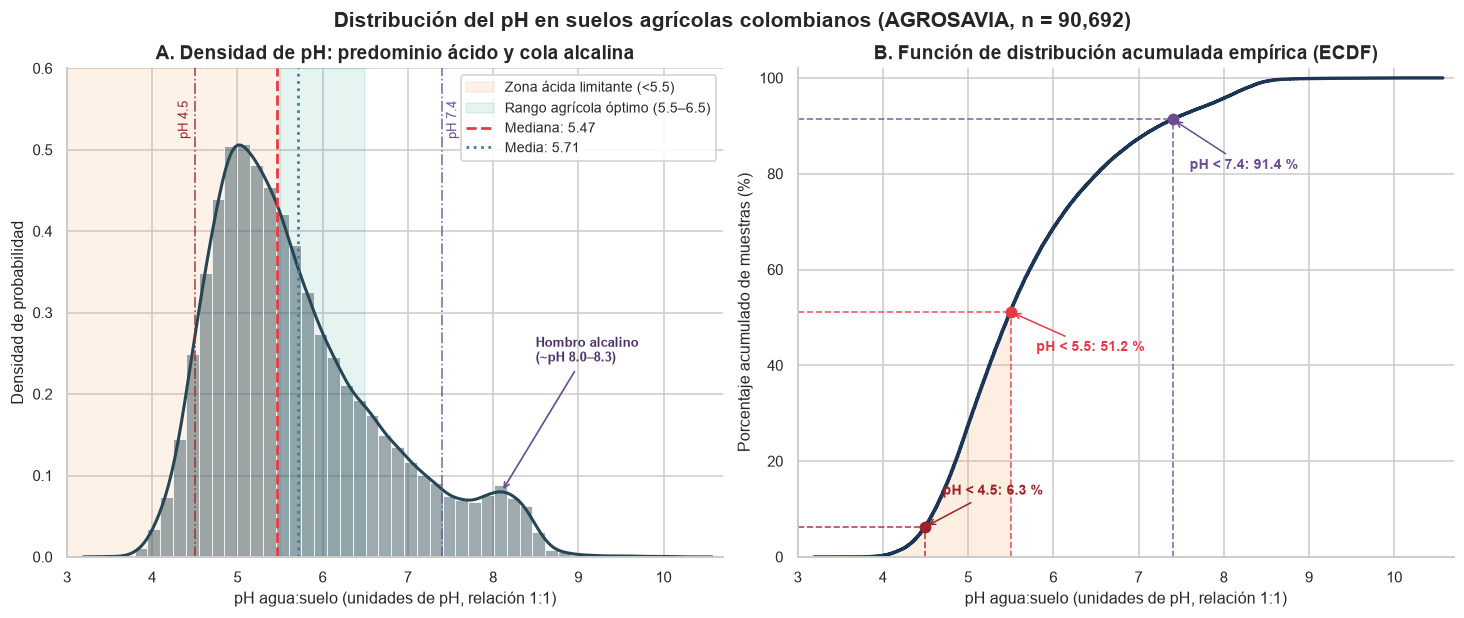

In [28]:
# Figura 1: Distribución univariada de pH agua:suelo (Histograma + KDE y ECDF)
ph = df_eda['ph_agua_suelo'].dropna()
ph_med = float(ph.median())
ph_mean = float(ph.mean())
pct_45 = float((ph < 4.5).mean() * 100)
pct_55 = float((ph < 5.5).mean() * 100)
pct_74 = float((ph < 7.4).mean() * 100)

fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.2), constrained_layout=True)

# Panel A: Histograma + KDE
ax = axes[0]
ax.axvspan(3.0, 5.5, color='#f4a261', alpha=0.14, label='Zona ácida limitante (<5.5)')
ax.axvspan(5.5, 6.5, color='#2a9d8f', alpha=0.12, label='Rango agrícola óptimo (5.5–6.5)')
sns.histplot(
    ph, binwidth=0.15, stat='density', kde=True,
    color='#264653', alpha=0.45, edgecolor='white', linewidth=0.5,
    line_kws={'color': '#1d3557', 'linewidth': 2.0}, ax=ax
)
ax.axvline(ph_med, color='#e63946', linestyle='--', linewidth=1.8, label=f'Mediana: {ph_med:.2f}')
ax.axvline(ph_mean, color='#457b9d', linestyle=':', linewidth=1.8, label=f'Media: {ph_mean:.2f}')
ax.axvline(4.5, color='#9b2226', linestyle='-.', linewidth=1.1, alpha=0.8)
ax.axvline(7.4, color='#6a4c93', linestyle='-.', linewidth=1.1, alpha=0.8)
ax.text(4.45, 0.56, 'pH 4.5', rotation=90, va='top', ha='right', fontsize=8.5, color='#9b2226')
ax.text(7.45, 0.56, 'pH 7.4', rotation=90, va='top', ha='left', fontsize=8.5, color='#6a4c93')
ax.annotate('Hombro alcalino\n(~pH 8.0–8.3)', xy=(8.1, 0.08), xytext=(8.5, 0.24),
            arrowprops=dict(arrowstyle='->', color='#6a4c93', lw=1.1),
            fontsize=8.5, color='#4a3268', fontweight='bold')
ax.set_xlim(3.0, 10.7)
ax.set_ylim(0, 0.60)
ax.set_xlabel('pH agua:suelo (unidades de pH, relación 1:1)')
ax.set_ylabel('Densidad de probabilidad')
ax.set_title('A. Densidad de pH: predominio ácido y cola alcalina')
ax.legend(loc='upper right', frameon=True, framealpha=0.9)

# Panel B: ECDF
ax2 = axes[1]
sorted_ph = np.sort(ph.to_numpy())
ecdf_pct = np.arange(1, len(sorted_ph) + 1) / len(sorted_ph) * 100.0
ax2.plot(sorted_ph, ecdf_pct, color='#1d3557', linewidth=2.2)
ax2.fill_between(sorted_ph, 0, ecdf_pct, where=(sorted_ph < 5.5), color='#f4a261', alpha=0.18)

umbral_pts = [
    (4.5, pct_45, (4.7, 13), '#9b2226'),
    (5.5, pct_55, (5.8, 43), '#e63946'),
    (7.4, pct_74, (7.6, 81), '#6a4c93'),
]
for x_u, y_u, xy_t, col in umbral_pts:
    ax2.plot([x_u, x_u], [0, y_u], color=col, linestyle='--', linewidth=1.1, alpha=0.8)
    ax2.plot([3.0, x_u], [y_u, y_u], color=col, linestyle='--', linewidth=1.1, alpha=0.8)
    ax2.scatter([x_u], [y_u], color=col, s=45, zorder=5)
    ax2.annotate(f'pH < {x_u:.1f}: {y_u:.1f} %', xy=(x_u, y_u), xytext=xy_t,
                 arrowprops=dict(arrowstyle='->', color=col, lw=1.0),
                 fontsize=9, fontweight='bold', color=col)

ax2.set_xlim(3.0, 10.7)
ax2.set_ylim(0, 102)
ax2.set_xlabel('pH agua:suelo (unidades de pH, relación 1:1)')
ax2.set_ylabel('Porcentaje acumulado de muestras (%)')
ax2.set_title('B. Función de distribución acumulada empírica (ECDF)')

fig.suptitle('Distribución del pH en suelos agrícolas colombianos (AGROSAVIA, n = 90,692)',
             fontsize=13.5, fontweight='bold', y=1.05)
fig.savefig('figures/fig1_distribucion_ph.png', bbox_inches='tight', dpi=150)
plt.show()

**Leyenda (Figura 1):**
Más de la mitad de las muestras (`51.2 %`) presenta acidez limitante (`pH < 5.5`) y `6.3 %` acidez extrema (`pH < 4.5`), situando la mediana (`5.47`) bajo la media (`5.71`) y fuera del rango óptimo agrícola (`5.5–6.5`, apenas `28.7 %`). La distribución muestra asimetría derecha (`g1 = +0.92`) y un hombro secundario alrededor de `pH 8.0–8.3`, reflejando suelos alcalinos de regiones secas que constituyen el `8.6 %` con `pH >= 7.4`. *(72 palabras)*

**Justificación metodológica y qué habría ocultado la alternativa:**
Se eligió **histograma con KDE** combinado con **ECDF** porque responden simultáneamente sobre forma modal y proporciones exactas bajo umbrales agronómicos sin depender arbitrariamente del ancho de clase. Un **boxplot** habría resumido centro y cuartiles pero habría ocultado por completo el hombro alcalino secundario cerca de `pH 8.1` y dificultado leer que exactamente `51.2 %` cae bajo `5.5`.

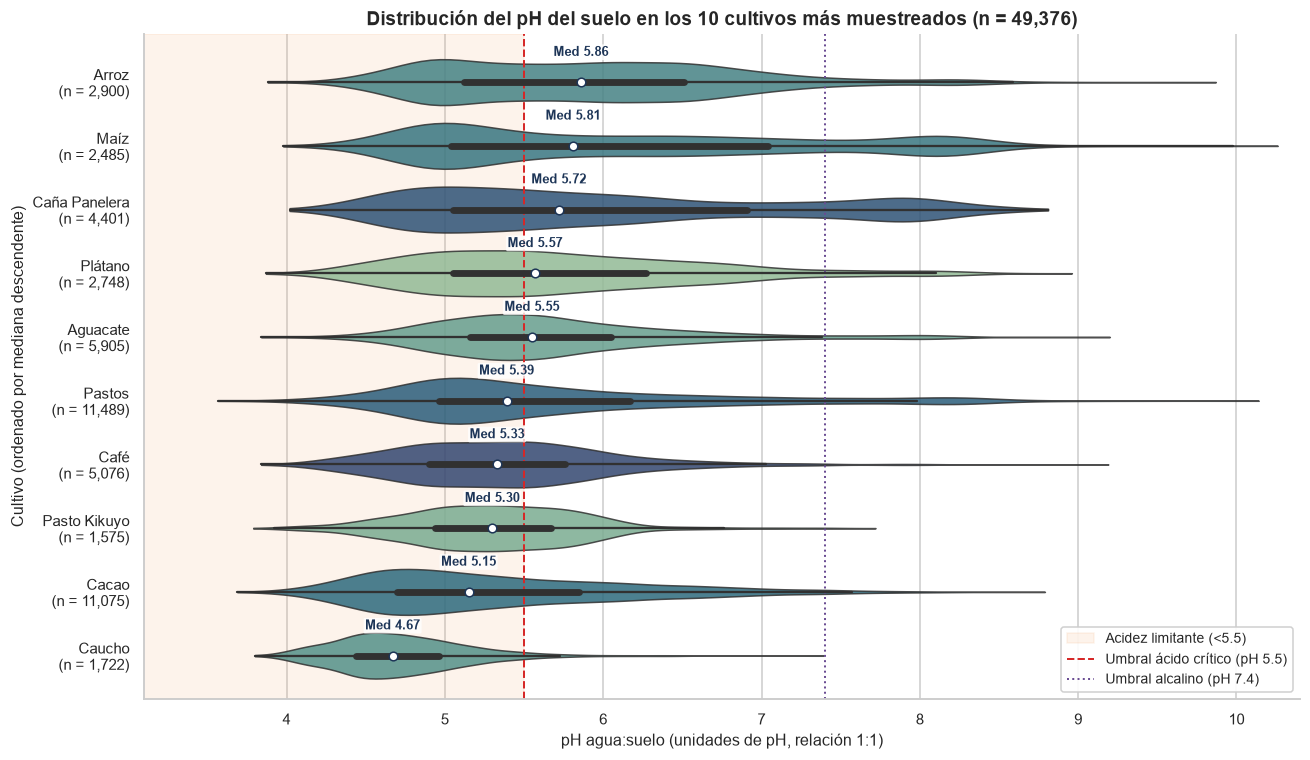

In [29]:
# Figura 2: Comparación de pH entre los 10 cultivos principales (Violín horizontal + boxplot interno ordenado)
top10_cult = df_eda['cultivo'].value_counts().head(10).index
df_c = df_eda[df_eda['cultivo'].isin(top10_cult)].copy()
df_c['cultivo'] = df_c['cultivo'].astype(str)

order_cult = (
    df_c.groupby('cultivo')['ph_agua_suelo']
    .median()
    .sort_values(ascending=False)
    .index.tolist()
)
counts_cult = df_c['cultivo'].value_counts().to_dict()
medians_cult = df_c.groupby('cultivo')['ph_agua_suelo'].median().to_dict()

fig, ax = plt.subplots(figsize=(11.8, 6.8), constrained_layout=True)
ax.axvspan(3.0, 5.5, color='#f4a261', alpha=0.12, label='Acidez limitante (<5.5)')
ax.axvline(5.5, color='#d62828', linestyle='--', linewidth=1.3, label='Umbral ácido crítico (pH 5.5)')
ax.axvline(7.4, color='#6a4c93', linestyle=':', linewidth=1.3, label='Umbral alcalino (pH 7.4)')

sns.violinplot(
    data=df_c, y='cultivo', x='ph_agua_suelo', order=order_cult,
    hue='cultivo', palette='crest_r', legend=False,
    inner='box', cut=0, density_norm='width', width=0.72, linewidth=1.0, alpha=0.85, ax=ax
)

# Etiquetar mediana exacta por encima del contorno del violín sin solapamientos
for idx, c_name in enumerate(order_cult):
    med = medians_cult[c_name]
    ax.scatter([med], [idx], color='#ffffff', edgecolor='#1d3557', s=32, zorder=6)
    ax.text(
        med, idx - 0.37, f'Med {med:.2f}', ha='center', va='bottom',
        fontsize=8.2, fontweight='bold', color='#1d3557',
        bbox=dict(boxstyle='round,pad=0.12', facecolor='white', edgecolor='none', alpha=0.78),
    )

ax.set_yticks(range(len(order_cult)))
ax.set_yticklabels([f'{c}\n(n = {counts_cult[c]:,})' for c in order_cult])
ax.set_xlim(3.1, 10.4)
ax.set_ylim(len(order_cult) - 0.32, -0.75)
ax.set_xlabel('pH agua:suelo (unidades de pH, relación 1:1)')
ax.set_ylabel('Cultivo (ordenado por mediana descendente)')
ax.set_title(f'Distribución del pH del suelo en los 10 cultivos más muestreados (n = {len(df_c):,})')
ax.legend(loc='lower right', frameon=True, framealpha=0.92)

fig.savefig('figures/fig2_ph_por_cultivo.png', bbox_inches='tight', dpi=150)
plt.show()

**Leyenda (Figura 2):**
El pH mediano cae `1.19` unidades desde `Arroz` (`5.86`) y `Maíz` (`5.81`) hasta `Cacao` (`5.15`) y `Caucho` (`4.67`), este último concentrado bajo `5.5` (`RIC = 0.52`). `Maíz` (`RIC = 2.00`) y `Caña Panelera` (`RIC = 1.86`) exhiben distribuciones bimodales con un segundo lóbulo entre `pH 7.5` y `8.3`, mientras `Aguacate`, `Café` y `Pasto Kikuyo` mantienen distribuciones unimodales más estrechas centradas en `5.30–5.55`. *(62 palabras)*

**Justificación metodológica y qué habría ocultado la alternativa:**
El **gráfico de violín con boxplot interno**, ordenado por mediana e incluyendo tamaños muestrales, permite comparar simultáneamente centro, dispersión y densidad multimodal entre grupos. Un **boxplot simple** habría ocultado por completo la bimodalidad de `Maíz` y `Caña Panelera` (que refleja su cultivo tanto en suelos ácidos andinos/orinoquenses como en valles o planicies alcalinas del Caribe), y un **gráfico de barras de medias** habría escondido la asimetría y la amplitud intercuartílica.

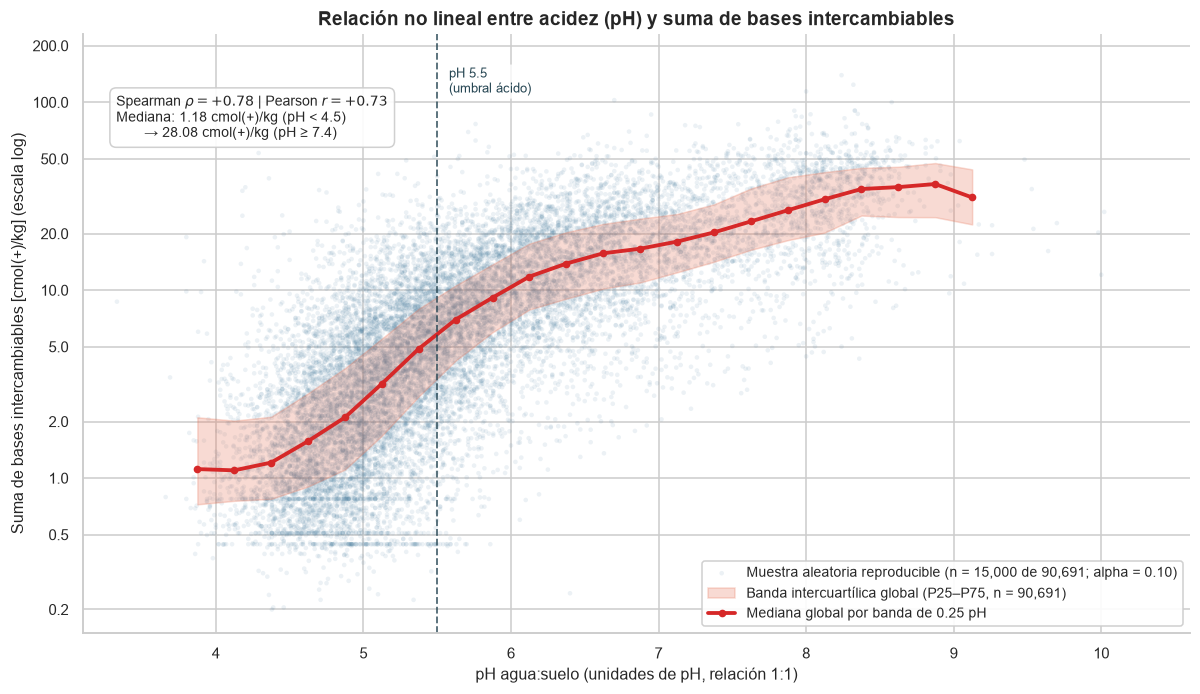

In [30]:
# Figura 3: Relación no lineal entre pH y Suma de Bases (muestra reproducible + mediana/RIC global en escala log)
sub_sb = df_eda[['ph_agua_suelo', 'suma_bases_cmol_kg']].dropna().copy()
sample_sb = sub_sb.sample(n=15000, random_state=42)

# Curva mediana y banda RIC calculadas sobre TODOS los 90,691 registros por bins de 0.25 pH
bins_ph = np.arange(3.25, 10.25, 0.25)
sub_sb['ph_bin'] = pd.cut(sub_sb['ph_agua_suelo'], bins=bins_ph)
trend = (
    sub_sb.groupby('ph_bin', observed=True)['suma_bases_cmol_kg']
    .agg(
        n='size',
        q25=lambda s: s.quantile(0.25),
        med='median',
        q75=lambda s: s.quantile(0.75),
    )
    .reset_index()
)
trend = trend[trend['n'] >= 30].copy()
trend['ph_mid'] = trend['ph_bin'].apply(lambda iv: iv.mid).astype(float)

rho_sp = float(sub_sb[['ph_agua_suelo', 'suma_bases_cmol_kg']].corr(method='spearman').iloc[0, 1])
r_pe = float(sub_sb[['ph_agua_suelo', 'suma_bases_cmol_kg']].corr(method='pearson').iloc[0, 1])

fig, ax = plt.subplots(figsize=(10.8, 6.2), constrained_layout=True)

ax.scatter(
    sample_sb['ph_agua_suelo'], sample_sb['suma_bases_cmol_kg'],
    s=9, alpha=0.10, color='#457b9d', edgecolors='none', rasterized=True,
    label='Muestra aleatoria reproducible (n = 15,000 de 90,691; alpha = 0.10)'
)
ax.fill_between(
    trend['ph_mid'], trend['q25'], trend['q75'],
    color='#e76f51', alpha=0.25, label='Banda intercuartílica global (P25–P75, n = 90,691)'
)
ax.plot(
    trend['ph_mid'], trend['med'],
    color='#d62828', linewidth=2.5, marker='o', markersize=4,
    label='Mediana global por banda de 0.25 pH'
)
ax.axvline(5.5, color='#264653', linestyle='--', linewidth=1.2, alpha=0.8)
ax.text(5.58, 155, 'pH 5.5\n(umbral ácido)', ha='left', va='top', fontsize=8.8, color='#264653',
        bbox=dict(boxstyle='round,pad=0.15', facecolor='white', edgecolor='none', alpha=0.78))

ax.set_yscale('log')
ticks_y = [0.2, 0.5, 1, 2, 5, 10, 20, 50, 100, 200]
ax.set_yticks(ticks_y)
ax.get_yaxis().set_major_formatter(mticker.ScalarFormatter())
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
ax.set_xlim(3.1, 10.6)
ax.set_ylim(0.15, 230)

ax.text(
    0.03, 0.90,
    f'Spearman $\\rho = {rho_sp:+.2f}$ | Pearson $r = {r_pe:+.2f}$\n'
    'Mediana: 1.18 cmol(+)/kg (pH < 4.5)\n'
    '       → 28.08 cmol(+)/kg (pH ≥ 7.4)',
    transform=ax.transAxes, va='top', ha='left', fontsize=9.2,
    bbox=dict(boxstyle='round,pad=0.45', facecolor='white', edgecolor='#cccccc', alpha=0.92)
)

ax.set_xlabel('pH agua:suelo (unidades de pH, relación 1:1)')
ax.set_ylabel('Suma de bases intercambiables [cmol(+)/kg] (escala log)')
ax.set_title('Relación no lineal entre acidez (pH) y suma de bases intercambiables')
ax.legend(loc='lower right', frameon=True, framealpha=0.92)

fig.savefig('figures/fig3_ph_vs_suma_bases.png', bbox_inches='tight', dpi=150)
plt.show()

**Leyenda (Figura 3):**
La suma de bases crece fuertemente con el pH (`rho = +0.78`), describiendo una curva sigmoidal en escala logarítmica: la mediana global pasa de `1.18 cmol(+)/kg` (`pH < 4.5`) a `3.85` (`5.0–5.5`), asciende hasta `28.08 cmol(+)/kg` (`pH >= 7.4`) y se estabiliza en una meseta (`~31–36 cmol(+)/kg`) por encima de `pH 7.8`, manteniendo amplia dispersión vertical (`P25–P75`) en toda la gama. *(61 palabras)*

**Justificación metodológica y qué habría ocultado la alternativa:**
Se combinó **dispersión con transparencia sobre muestra reproducible (`n = 15,000`, `alpha = 0.10`)**, **eje Y logarítmico** y **mediana con banda RIC sobre los `90,691` puntos** para evitar el sobreploteo y revelar la curva sigmoidal en concentración. Una **dispersión en escala lineal sin transparencia** aplastaría el `95 %` de los datos en una franja negra inferior, y una **recta lineal o coeficiente $r$ aislado** ocultaría la saturación alcalina sobre `pH 7.8` y la dispersión de orden de magnitud.

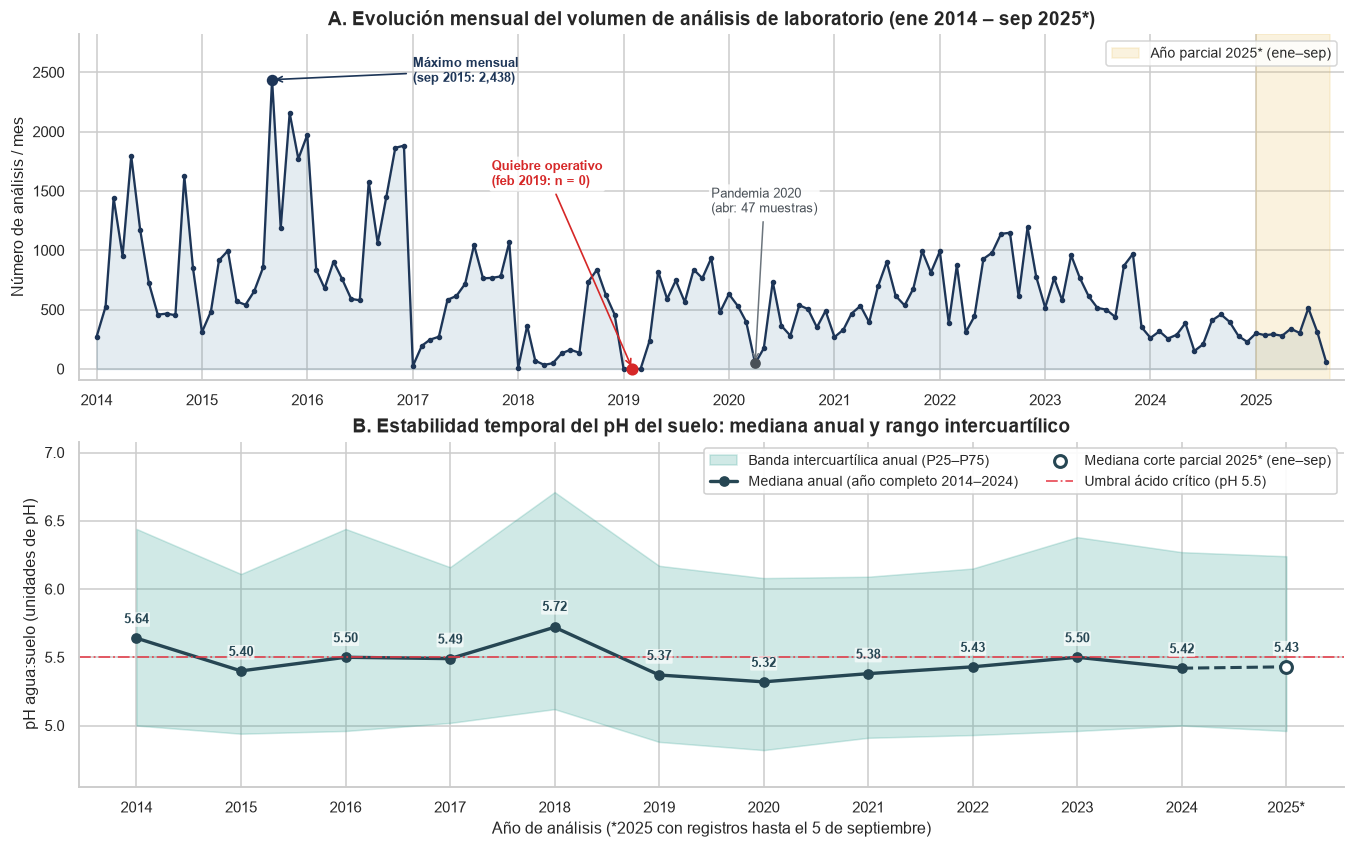

In [31]:
# Figura 4: Evolución temporal mensual del volumen de análisis y anual de pH (Mediana + RIC)
# Serie mensual completa incluyendo meses con 0 registros (ej. feb-2019)
full_months = pd.date_range('2014-01-01', '2025-09-01', freq='MS')
monthly = (
    df_eda.assign(mes_inicio=df_eda['fecha_analisis'].dt.to_period('M').dt.to_timestamp())
    .groupby('mes_inicio')
    .size()
    .reindex(full_months, fill_value=0)
)

annual = df_eda.groupby('anio_analisis').agg(
    n=('ph_agua_suelo', 'size'),
    q25=('ph_agua_suelo', lambda s: s.quantile(0.25)),
    med=('ph_agua_suelo', 'median'),
    q75=('ph_agua_suelo', lambda s: s.quantile(0.75)),
).reset_index()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12.2, 7.6), constrained_layout=True)

# Panel A: Volumen mensual
ax1.plot(monthly.index, monthly.values, color='#1d3557', linewidth=1.5, marker='o', markersize=2.6)
ax1.fill_between(monthly.index, 0, monthly.values, color='#457b9d', alpha=0.14)
ax1.axvspan(pd.Timestamp('2025-01-01'), pd.Timestamp('2025-09-15'), color='#e9c46a', alpha=0.22,
            label='Año parcial 2025* (ene–sep)')

peak_dt = monthly.idxmax()
peak_val = int(monthly.max())
ax1.scatter([peak_dt], [peak_val], color='#1d3557', s=42, zorder=6)
ax1.annotate(f'Máximo mensual\n(sep 2015: {peak_val:,})',
             xy=(peak_dt, peak_val), xytext=(pd.Timestamp('2017-01-01'), 2420),
             arrowprops=dict(arrowstyle='->', color='#1d3557', lw=1.1),
             fontsize=8.8, fontweight='bold', color='#1d3557')

feb19 = pd.Timestamp('2019-02-01')
ax1.scatter([feb19], [0], color='#d62828', s=48, zorder=6)
ax1.annotate('Quiebre operativo\n(feb 2019: n = 0)',
             xy=(feb19, 0), xytext=(pd.Timestamp('2017-10-01'), 1550),
             arrowprops=dict(arrowstyle='->', color='#d62828', lw=1.1),
             fontsize=8.8, fontweight='bold', color='#d62828',
             bbox=dict(boxstyle='round,pad=0.18', facecolor='white', edgecolor='none', alpha=0.82))

abr20_dt = pd.Timestamp('2020-04-01')
abr20_val = int(monthly.loc[abr20_dt])
ax1.scatter([abr20_dt], [abr20_val], color='#495057', s=36, zorder=6)
ax1.annotate(f'Pandemia 2020\n(abr: {abr20_val} muestras)',
             xy=(abr20_dt, abr20_val),
             xytext=(pd.Timestamp('2019-11-01'), 1320),
             arrowprops=dict(arrowstyle='->', color='#6c757d', lw=1.0),
             fontsize=8.5, color='#495057',
             bbox=dict(boxstyle='round,pad=0.18', facecolor='white', edgecolor='none', alpha=0.82))

ax1.xaxis.set_major_locator(mdates.YearLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax1.set_xlim(pd.Timestamp('2013-11-01'), pd.Timestamp('2025-11-01'))
ax1.set_ylim(-90, 2820)
ax1.set_ylabel('Número de análisis / mes')
ax1.set_title('A. Evolución mensual del volumen de análisis de laboratorio (ene 2014 – sep 2025*)')
ax1.legend(loc='upper right', frameon=True)

# Panel B: Mediana anual de pH con banda RIC (P25–P75)
yrs = annual['anio_analisis'].to_numpy()
ax2.fill_between(yrs, annual['q25'], annual['q75'], color='#2a9d8f', alpha=0.22,
                 label='Banda intercuartílica anual (P25–P75)')
# Línea continua hasta 2024 y punteada para el corte parcial 2025*
ax2.plot(yrs[:-1], annual['med'].iloc[:-1], color='#264653', linewidth=2.2,
         marker='o', markersize=6, label='Mediana anual (año completo 2014–2024)')
ax2.plot(yrs[-2:], annual['med'].iloc[-2:], color='#264653', linewidth=2.0, linestyle='--')
ax2.scatter([yrs[-1]], [annual['med'].iloc[-1]], facecolor='white', edgecolor='#264653',
            linewidth=2.0, s=60, zorder=6, label='Mediana corte parcial 2025* (ene–sep)')

ax2.axhline(5.5, color='#e63946', linestyle='-.', linewidth=1.2, alpha=0.85, label='Umbral ácido crítico (pH 5.5)')

for _, row in annual.iterrows():
    offset = 0.09 if row['anio_analisis'] != 2018 else 0.10
    ax2.text(row['anio_analisis'], row['med'] + offset, f"{row['med']:.2f}",
             ha='center', va='bottom', fontsize=8.3, color='#264653', fontweight='bold',
             bbox=dict(boxstyle='round,pad=0.08', facecolor='white', edgecolor='none', alpha=0.65))

ax2.set_xticks(yrs)
ax2.set_xticklabels([f'{int(y)}*' if y == 2025 else str(int(y)) for y in yrs])
ax2.set_ylim(4.55, 7.08)
ax2.set_xlabel('Año de análisis (*2025 con registros hasta el 5 de septiembre)')
ax2.set_ylabel('pH agua:suelo (unidades de pH)')
ax2.set_title('B. Estabilidad temporal del pH del suelo: mediana anual y rango intercuartílico')
ax2.legend(loc='upper right', ncol=2, frameon=True, framealpha=0.92)

fig.savefig('figures/fig4_evolucion_temporal.png', bbox_inches='tight', dpi=150)
plt.show()

**Leyenda (Figura 4):**
La demanda analítica mensual fue máxima entre 2014 y 2016 (pico en septiembre de 2015 con `2,438` muestras), cayó a cero en febrero de 2019 por un quiebre operativo, descendió a `47` análisis en abril de 2020 durante la pandemia y repuntó hacia `2022`. Pese a estas variaciones de volumen, la acidez nacional se mantuvo estable: la mediana anual osciló entre `5.32` (2020) y `5.72` (2018), con `P25` alrededor de `4.8–5.1`. *(71 palabras)*

**Justificación metodológica y qué habría ocultado la alternativa:**
Se utilizaron **series de línea** (mensual continua con ceros explícitos y anual con **banda intercuartílica P25–P75**) para capturar continuidad, discontinuidades operativas y dispersión en el tiempo. Un **gráfico de barras anuales** habría ocultado el cierre temporal de inicios de 2019 (`ene=3`, `feb=0`, `mar=1`), hecho parecer el corte parcial `2025*` como un desplome productivo y omitido la amplitud intercuartílica en torno a cada mediana anual.

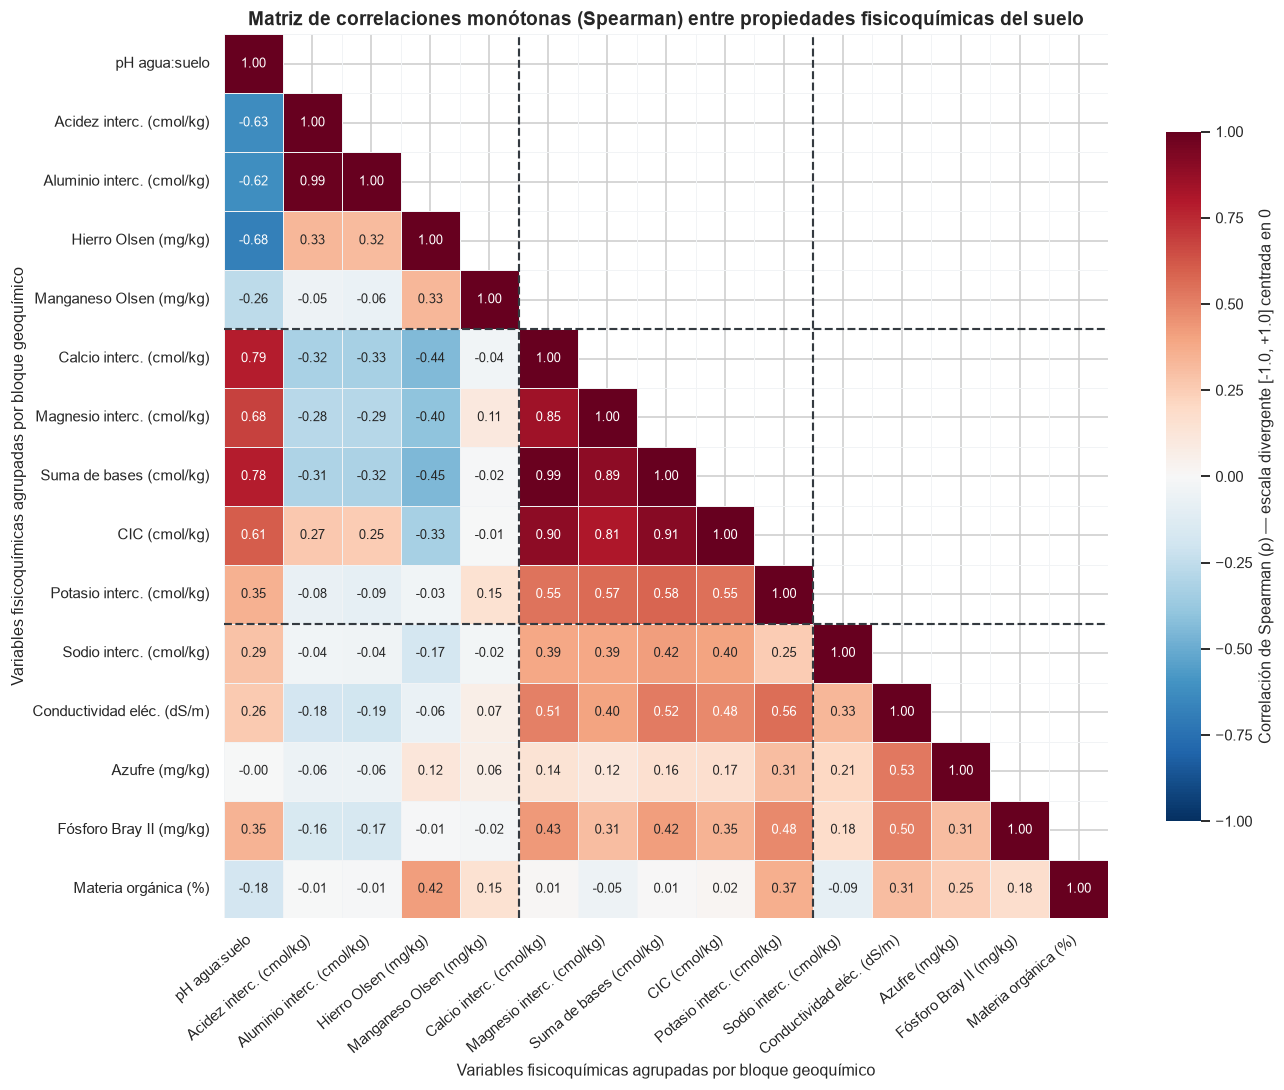

In [32]:
# Figura 5: Heatmap de matriz de correlaciones de Spearman ordenada por bloques geoquímicos
labels_cortas = {
    'ph_agua_suelo': 'pH agua:suelo',
    'acidez_intercambiable_cmol_kg': 'Acidez interc. (cmol/kg)',
    'aluminio_intercambiable_cmol_kg': 'Aluminio interc. (cmol/kg)',
    'hierro_olsen_mg_kg': 'Hierro Olsen (mg/kg)',
    'manganeso_olsen_mg_kg': 'Manganeso Olsen (mg/kg)',
    'calcio_intercambiable_cmol_kg': 'Calcio interc. (cmol/kg)',
    'magnesio_intercambiable_cmol_kg': 'Magnesio interc. (cmol/kg)',
    'suma_bases_cmol_kg': 'Suma de bases (cmol/kg)',
    'cic_cmol_kg': 'CIC (cmol/kg)',
    'potasio_intercambiable_cmol_kg': 'Potasio interc. (cmol/kg)',
    'sodio_intercambiable_cmol_kg': 'Sodio interc. (cmol/kg)',
    'conductividad_electrica_ds_m': 'Conductividad eléc. (dS/m)',
    'azufre_mg_kg': 'Azufre (mg/kg)',
    'fosforo_bray_ii_mg_kg': 'Fósforo Bray II (mg/kg)',
    'materia_organica_pct': 'Materia orgánica (%)',
}

mat_sp = corr_spearman.rename(index=labels_cortas, columns=labels_cortas)
mask_upper = np.triu(np.ones_like(mat_sp, dtype=bool), k=1)

fig, ax = plt.subplots(figsize=(12.2, 9.8), constrained_layout=True)
sns.heatmap(
    mat_sp,
    mask=mask_upper,
    cmap='RdBu_r',
    vmin=-1.0,
    vmax=1.0,
    center=0.0,
    square=True,
    annot=True,
    fmt='.2f',
    annot_kws={'size': 8.2},
    linewidths=0.6,
    linecolor='#f1f3f5',
    cbar_kws={
        'shrink': 0.78,
        'label': 'Correlación de Spearman (ρ) — escala divergente [-1.0, +1.0] centrada en 0',
    },
    ax=ax,
)

# Líneas de separación entre los 3 bloques geoquímicos (indices 5 y 10)
for b in (5, 10):
    ax.axhline(b, color='#343a40', linewidth=1.4, linestyle='--')
    ax.axvline(b, color='#343a40', linewidth=1.4, linestyle='--')

ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha='right')
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
ax.set_xlabel('Variables fisicoquímicas agrupadas por bloque geoquímico')
ax.set_ylabel('Variables fisicoquímicas agrupadas por bloque geoquímico')
ax.set_title('Matriz de correlaciones monótonas (Spearman) entre propiedades fisicoquímicas del suelo')

fig.savefig('figures/fig5_heatmap_correlaciones.png', bbox_inches='tight', dpi=150)
plt.show()

**Leyenda (Figura 5):**
El heatmap revela dos bloques acoplados con signo opuesto alrededor del pH: `Acidez` y `Aluminio` correlacionan casi perfectamente entre sí (`rho = +0.99`) y negativamente con el pH (`-0.62` a `-0.63`), al igual que `Hierro Olsen` (`-0.68`). En contraste, `Calcio`, `Magnesio`, `Suma de bases` y `CIC` forman un bloque positivo compacto (`+0.81` a `+0.99`), mientras `Conductividad eléctrica` se enlaza con `Azufre` (`+0.53`), `Suma de bases` (`+0.52`) y `Fósforo` (`+0.50`). *(69 palabras)*

**Justificación metodológica y qué habría ocultado la alternativa:**
Se empleó un **heatmap de Spearman ordenado en bloques** con **paleta divergente `RdBu_r` centrada en cero (`[-1, +1]`)** para separar visualmente asociaciones positivas, nulas y negativas sin deformación por colas extremas. Un **heatmap basado en Pearson** habría atenuado artificialmente pares clave (`Ca–Mg` de `0.85` a `0.50` y `pH–Fe` de `-0.68` a `-0.42`), y una **paleta secuencial** habría borrado la frontera visual de signo en cero.

---
## 10. Bitácora técnica actualizada (Etapa 2) y evidencia diagnóstica

Siguiendo las instrucciones de la prueba, se ilustra gráficamente el principal reto técnico de visualización enfrentado al trabajar con `90,692` muestras y escalas asimétricas, y se amplía la bitácora de problemas reales resueltos.

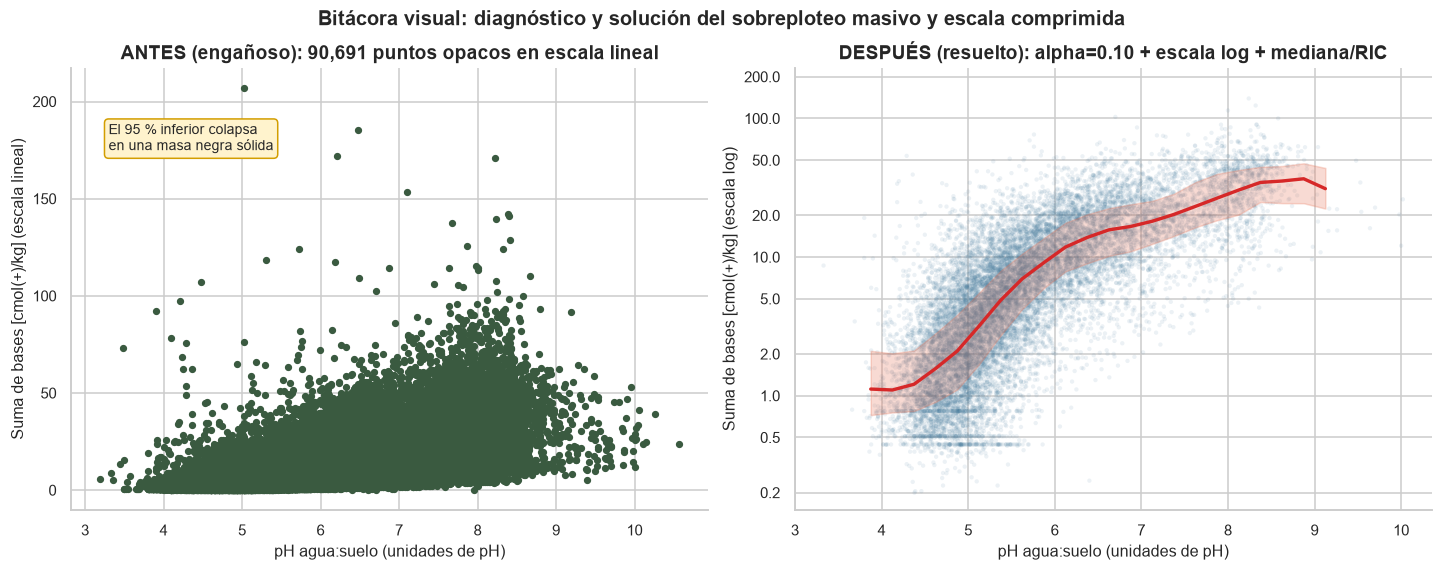

In [33]:
# Evidencia visual de bitácora: Antes (gráfico engañoso con sobreploteo lineal) vs. Después (resuelto)
sub_sb = df_eda[['ph_agua_suelo', 'suma_bases_cmol_kg']].dropna()
sample_sb = sub_sb.sample(n=15000, random_state=42)

bins_ph = np.arange(3.25, 10.25, 0.25)
trend = (
    sub_sb.assign(ph_bin=pd.cut(sub_sb['ph_agua_suelo'], bins=bins_ph))
    .groupby('ph_bin', observed=True)['suma_bases_cmol_kg']
    .agg(n='size', q25=lambda s: s.quantile(0.25), med='median', q75=lambda s: s.quantile(0.75))
    .reset_index()
)
trend = trend[trend['n'] >= 30].copy()
trend['ph_mid'] = trend['ph_bin'].apply(lambda iv: iv.mid).astype(float)

fig, (axL, axR) = plt.subplots(1, 2, figsize=(13.0, 4.8), constrained_layout=True)

# Antes: Todos los puntos opacos en escala lineal
axL.scatter(sub_sb['ph_agua_suelo'], sub_sb['suma_bases_cmol_kg'], s=14, alpha=1.0, color='#3a5a40')
axL.set_xlabel('pH agua:suelo (unidades de pH)')
axL.set_ylabel('Suma de bases [cmol(+)/kg] (escala lineal)')
axL.set_title('ANTES (engañoso): 90,691 puntos opacos en escala lineal')
axL.text(3.3, 175, 'El 95 % inferior colapsa\nen una masa negra sólida', fontsize=9,
         bbox=dict(boxstyle='round', facecolor='#fff3cd', edgecolor='#d39e00'))

# Después: Muestra reproducible + alpha + log10 + mediana/RIC
axR.scatter(sample_sb['ph_agua_suelo'], sample_sb['suma_bases_cmol_kg'],
            s=8, alpha=0.10, color='#457b9d', edgecolors='none', rasterized=True)
axR.fill_between(trend['ph_mid'], trend['q25'], trend['q75'], color='#e76f51', alpha=0.25)
axR.plot(trend['ph_mid'], trend['med'], color='#d62828', linewidth=2.2)
axR.set_yscale('log')
axR.set_yticks([0.2, 0.5, 1, 2, 5, 10, 20, 50, 100, 200])
axR.get_yaxis().set_major_formatter(mticker.ScalarFormatter())
axR.yaxis.set_minor_formatter(mticker.NullFormatter())
axR.set_ylim(0.15, 230)
axR.set_xlabel('pH agua:suelo (unidades de pH)')
axR.set_ylabel('Suma de bases [cmol(+)/kg] (escala log)')
axR.set_title('DESPUÉS (resuelto): alpha=0.10 + escala log + mediana/RIC')

fig.suptitle('Bitácora visual: diagnóstico y solución del sobreploteo masivo y escala comprimida',
             fontsize=13, fontweight='bold', y=1.05)
fig.savefig('figures/fig_bitacora_sobreploteo.png', bbox_inches='tight', dpi=150)
plt.show()

**Leyenda (Figura diagnóstica de bitácora):**
En la gráfica lineal sin transparencia (izquierda), los valores atípicos hasta `206.8 cmol(+)/kg` comprimen el `95 %` de los suelos por debajo de `34 cmol(+)/kg` en una masa opaca indescifrable. Al aplicar muestreo reproducible con `alpha = 0.10`, eje logarítmico y la mediana con banda intercuartílica global (derecha), emergen claramente la curvatura ascendente y la meseta alcalina por encima de `pH 7.8`. *(62 palabras)*

### Bitácora técnica acumulada (Etapa 2 — problemas reales `9` a `14`)
9. **Ausencia de `scipy` en el entorno virtual `.venv`:** Al probar `sns.clustermap()` para la Figura 5 se produjo `RuntimeError: clustermap requires scipy to be available`, y tampoco había soporte nativo de `scipy.stats` para Kruskal-Wallis o $\chi^2$. Se resolvió ordenando manualmente las 15 variables del heatmap en tres bloques geoquímicos interpretables (`sns.heatmap`) e implementando de forma vectorizada en `pandas`/`numpy` la prueba de Kruskal-Wallis (con corrección por empates y $\varepsilon^2$), el estadístico $\chi^2$ de Pearson y $V$ de Cramér.
10. **Sobreploteo masivo (`90,691` puntos) y compresión vertical de escala:** Graficar `ph_agua_suelo` frente a `suma_bases_cmol_kg` en crudo generaba una nube negra ilegible (ilustrada en la figura diagnóstica anterior). Se resolvió combinando submuestreo reproducible (`n = 15,000`, `random_state = 42`), opacidad baja (`alpha = 0.10`), transformación logarítmica en el eje Y y la curva mediana + `P25–P75` calculada sobre los `90,691` datos reales.
11. **Distorsión del coeficiente de Pearson ante colas extremas:** En pares como `Ca–Mg` (`Pearson = 0.504` vs. `Spearman = 0.847`) y `pH–Fe` (`-0.422` vs. `-0.682`), las colas extremas y la no linealidad de solubilidad subestimaban la fuerza real de asociación. Se resolvió reportando ambos coeficientes para transparentar la diferencia y eligiendo Spearman para la matriz de correlaciones.
12. **Censura instrumental silenciosa en `conductividad_electrica_ds_m == 12.88`:** El diagnóstico de atípicos reveló `86` registros idénticos en `12.88 dS/m` concentrados exclusivamente en `2019–2025` (frente a registros sin censura hasta `52.15 dS/m` en `2014–2018`). Se documentó como tope instrumental de dilución para evitar interpretar erróneamente una "caída reciente" de salinidad extrema.
13. **Quiebre operativo en febrero de 2019 y truncamiento de 2025:** Una tabla anual simple ocultaba que 2019 tuvo apenas `3` análisis en enero, `0` en febrero y `1` en marzo, y hacía lucir `2025` (`2,685` análisis hasta el `5 de septiembre`) como una caída abrupta. Se resolvió usando serie mensual continua con ceros explícitos en el Panel A de la Figura 4 y marcando explícitamente el corte parcial `2025*` en el Panel B.
14. **Sesgo de confusión geográfica en `topografia = 'Plano y pendiente'`:** Esta categoría exhibió un pH mediano aparentemente atípico (`7.58`) frente a todas las demás (`5.26–5.65`). Al cruzarla con `departamento` se comprobó que `68.0 %` de sus `817` registros procede de `La Guajira`, `Atlántico` y `Cesar`, por lo que refleja clima/geología regional y no geometría del terreno.

---
# Etapa 3: Preguntas de Investigación, Limitaciones, Bitácora Consolidada y Cierre

En esta tercera y última etapa se sintetiza toda la evidencia generada a lo largo del análisis exploratorio (`92,738` registros crudos depurados a `90,692` registros válidos y `38` variables, junto con las cinco figuras obligatorias en `figures/` y la figura diagnóstica de bitácora) para cerrar el informe conforme a la rúbrica de la prueba:

1. **Sección 11:** Formulación y respuesta rigurosa de **tres preguntas de investigación biológicas/edafológicas** con hallazgos numerados respaldados por código en `pandas`, tablas de síntesis y las figuras `fig1` a `fig5`.
2. **Sección 12:** Evaluación crítica de las **limitaciones del estudio** (muestreo por demanda y representatividad, efecto de los faltantes/censura y la limpieza, distinción entre asociación observacional y causalidad con ejemplos concretos, y datos/diseños adicionales requeridos).
3. **Sección 13:** **Bitácora consolidada** de los problemas técnicos reales enfrentados durante el flujo completo y la evidencia de sus soluciones.
4. **Sección 14:** **Declaración transparente de uso de herramientas de Inteligencia Artificial** y síntesis de cierre.

---
## 11. Preguntas de investigación y respuestas basadas en evidencia

A partir de la estructura fisicoquímica, agronómica, geográfica y temporal del conjunto de datos de AGROSAVIA (`2014–2025`), se formulan exactamente **tres preguntas concretas** que los datos permiten responder con rigor empírico:

* **Pregunta 1 (Control geoquímico del pH):** *¿En qué medida el pH del suelo regula la aparición de toxicidad por aluminio intercambiable, la retención de bases intercambiables y la disponibilidad de hierro y fósforo en los suelos agrícolas colombianos?*
* **Pregunta 2 (Diferenciación entre cultivos y regiones):** *¿Cómo se diferencian la acidez y la materia orgánica entre los principales cultivos y departamentos de Colombia, y pesa más el contexto edafoclimático regional que la especie cultivada?*
* **Pregunta 3 (Dinámica temporal del muestreo y estabilidad química):** *¿Cómo evolucionaron el volumen mensual de análisis de laboratorio, los protocolos analíticos y la acidez edáfica nacional entre enero de 2014 y septiembre de 2025?*

A continuación, se ejecuta un bloque reproducible en `pandas` que consolida las métricas específicas complementarias (**Tablas 11.1, 11.2 y 11.3**) para respaldar cada hallazgo numerado junto con las tablas de las Etapas 1 y 2 y las **Figuras 1 a 5**.


In [34]:
# 11. Síntesis cuantitativa en pandas para respaldar las 3 preguntas de investigación (Tablas 11.1, 11.2 y 11.3)

# --- Tabla 11.1: Control del pH sobre toxicidad de Al, bases, Fe, P y método Doble ácido ---
ph_bandas_11 = pd.cut(
    df_eda['ph_agua_suelo'],
    bins=[-np.inf, 4.5, 5.0, 5.5, 6.0, 7.4, np.inf],
    labels=['< 4.5', '4.5 - 5.0', '5.0 - 5.5', '5.5 - 6.0', '6.0 - 7.4', '>= 7.4'],
    right=False,
)

tabla_11_1 = df_eda.groupby(ph_bandas_11, observed=False).agg(
    n_muestras=('ph_agua_suelo', 'size'),
    pct_nacional=('ph_agua_suelo', lambda s: len(s) / len(df_eda) * 100),
    Al_medidos=('aluminio_intercambiable_cmol_kg', 'count'),
    Al_med_cmol=('aluminio_intercambiable_cmol_kg', 'median'),
    pct_Al_gt2=('aluminio_intercambiable_cmol_kg', lambda s: (s > 2).sum() / s.notna().sum() * 100 if s.notna().sum() > 0 else 0.0),
    pct_Al_gt5=('aluminio_intercambiable_cmol_kg', lambda s: (s > 5).sum() / s.notna().sum() * 100 if s.notna().sum() > 0 else 0.0),
    Suma_bases_med=('suma_bases_cmol_kg', 'median'),
    Fe_Olsen_med=('hierro_olsen_mg_kg', 'median'),
    P_Bray_med=('fosforo_bray_ii_mg_kg', 'median'),
    pct_Doble_acido=('metodo_micronutrientes', lambda s: (s == 'Doble ácido').mean() * 100),
).round(2)

print('Tabla 11.1 — Control del pH sobre toxicidad alumínica, bases, hierro, fósforo y extractante:')
display(tabla_11_1)

mask_opt = (df_eda['ph_agua_suelo'] >= 5.5) & (df_eda['ph_agua_suelo'] <= 6.5)
sub_acid = df_eda[df_eda['ph_agua_suelo'] < 5.5]
al_gt2_acid = (sub_acid['aluminio_intercambiable_cmol_kg'] > 2).sum() / sub_acid['aluminio_intercambiable_cmol_kg'].notna().sum() * 100
print(f'Rango óptimo pH 5.5–6.5: {mask_opt.mean() * 100:.2f} % ({int(mask_opt.sum()):,} muestras)')
print(f'En suelos con pH < 5.5 (n = {len(sub_acid):,}): {al_gt2_acid:.2f} % de los titulados supera Al > 2 cmol(+)/kg.')

# --- Tabla 11.2: Diferenciación cultivo vs. departamento y descomposición geográfica de la bimodalidad ---
kw_comp = pd.DataFrame([
    {'Factor evaluado': 'Cultivo (Top 10)', 'Variable': 'pH agua:suelo', **kruskal_wallis_np(df_eda[df_eda['cultivo'].isin(top10_cult)], 'cultivo', 'ph_agua_suelo')},
    {'Factor evaluado': 'Departamento (Top 10)', 'Variable': 'pH agua:suelo', **kruskal_wallis_np(df_eda[df_eda['departamento'].isin(top10_dep)], 'departamento', 'ph_agua_suelo')},
    {'Factor evaluado': 'Departamento (Todos, 33)', 'Variable': 'pH agua:suelo', **kruskal_wallis_np(df_eda, 'departamento', 'ph_agua_suelo')},
    {'Factor evaluado': 'Cultivo (Top 10)', 'Variable': 'Materia orgánica (%)', **kruskal_wallis_np(df_eda[df_eda['cultivo'].isin(top10_cult)], 'cultivo', 'materia_organica_pct')},
    {'Factor evaluado': 'Departamento (Top 10)', 'Variable': 'Materia orgánica (%)', **kruskal_wallis_np(df_eda[df_eda['departamento'].isin(top10_dep)], 'departamento', 'materia_organica_pct')},
    {'Factor evaluado': 'Año de análisis (2014–2025*)', 'Variable': 'pH agua:suelo', **kruskal_wallis_np(df_eda, 'anio_analisis', 'ph_agua_suelo')},
])
print('\nTabla 11.2a — Comparación del tamaño del efecto (Kruskal-Wallis H y epsilon²) entre factores:')
display(kw_comp)

tabla_11_2b = df_eda[df_eda['cultivo'].isin(top10_cult)].groupby('cultivo', observed=True).agg(
    n=('ph_agua_suelo', 'size'),
    pH_med=('ph_agua_suelo', 'median'),
    pH_RIC=('ph_agua_suelo', lambda s: s.quantile(0.75) - s.quantile(0.25)),
    pct_pH_lt55=('ph_agua_suelo', lambda s: (s < 5.5).mean() * 100),
    pct_pH_ge74=('ph_agua_suelo', lambda s: (s >= 7.4).mean() * 100),
    MO_med_pct=('materia_organica_pct', 'median'),
    Al_med_cmol=('aluminio_intercambiable_cmol_kg', 'median'),
).sort_values('pH_med', ascending=False).round(2)
print('Tabla 11.2b — Perfil de acidez, alcalinidad y materia orgánica en los 10 cultivos principales:')
display(tabla_11_2b)

bimod_rows = []
for cult in ['Maíz', 'Caña Panelera', 'Caucho', 'Pasto Kikuyo']:
    sc = df_eda[df_eda['cultivo'] == cult]
    for reg_lbl, msk in [('Lóbulo ácido (pH < 5.5)', sc['ph_agua_suelo'] < 5.5),
                         ('Lóbulo alcalino (pH >= 7.4)', sc['ph_agua_suelo'] >= 7.4)]:
        sub_l = sc[msk]
        if len(sub_l) == 0:
            top_txt = 'Sin registros (0.0 %)'
        else:
            vc_raw = sub_l['departamento'].value_counts()
            vc = (vc_raw[vc_raw > 0].head(3) / len(sub_l) * 100).round(1)
            top_txt = ', '.join(f'{k} ({v:.1f} %)' for k, v in vc.items())
        bimod_rows.append({
            'Cultivo': cult,
            'Subgrupo pH': reg_lbl,
            'n': int(len(sub_l)),
            '% del cultivo': round(len(sub_l) / len(sc) * 100, 2),
            'Top 3 departamentos predominantes': top_txt,
        })
print('Tabla 11.2c — Composición geográfica de los lóbulos ácido y alcalino en cultivos clave:')
with pd.option_context('display.max_colwidth', None):
    display(pd.DataFrame(bimod_rows))

# --- Tabla 11.3: Dinámica temporal anual (volumen, pH, composición regional Caribe y protocolos) ---
caribe_deps = {'LA GUAJIRA', 'ATLÁNTICO', 'CESAR', 'MAGDALENA', 'BOLÍVAR', 'SUCRE', 'CÓRDOBA'}
dup_by_year = (
    pd.to_datetime(
        df_raw.loc[df_raw.duplicated(subset=[c for c in df_raw.columns if c != 'Secuencial'], keep='first'), 'Fecha de Análisis'],
        format='%d/%m/%Y',
    ).dt.year.value_counts()
)

tabla_11_3 = df_eda.groupby('anio_analisis').agg(
    n_muestras=('ph_agua_suelo', 'size'),
    pH_P25=('ph_agua_suelo', lambda s: s.quantile(0.25)),
    pH_med=('ph_agua_suelo', 'median'),
    pH_P75=('ph_agua_suelo', lambda s: s.quantile(0.75)),
    pct_pH_lt55=('ph_agua_suelo', lambda s: (s < 5.5).mean() * 100),
    pct_Caribe=('departamento', lambda s: s.isin(caribe_deps).mean() * 100),
    pct_Doble_acido=('metodo_micronutrientes', lambda s: (s == 'Doble ácido').mean() * 100),
    n_CE_1288=('conductividad_electrica_ds_m', lambda s: int((s == 12.88).sum())),
).round(2)
tabla_11_3['duplicados_removidos'] = tabla_11_3.index.map(lambda y: int(dup_by_year.get(y, 0)))

print('\nTabla 11.3 — Dinámica anual de muestreo, estabilidad del pH, mezcla Caribe y cambios operativos (2014–2025*):')
display(tabla_11_3)
print(f'Participación acumulada 2014–2016: {int(tabla_11_3.loc[2014:2016, "n_muestras"].sum()):,} muestras '
      f'({tabla_11_3.loc[2014:2016, "n_muestras"].sum() / len(df_eda) * 100:.2f} % del total).')


Tabla 11.1 — Control del pH sobre toxicidad alumínica, bases, hierro, fósforo y extractante:


,n_muestras,pct_nacional,Al_medidos,Al_med_cmol,pct_Al_gt2,pct_Al_gt5,Suma_bases_med,Fe_Olsen_med,P_Bray_med,pct_Doble_acido
ph_agua_suelo,,,,,,,,,,
< 4.5,5725,6.31,5725,2.70,68.61,18.53,1.18,410.22,4.17,11.09
4.5 - 5.0,18959,20.90,18959,1.88,46.27,8.29,1.84,273.54,4.64,10.57
5.0 - 5.5,21711,23.94,21709,0.66,12.19,1.56,3.85,184.80,6.42,6.19
5.5 - 6.0,15716,17.33,147,0.00,0.68,0.00,7.82,111.35,8.41,2.87
6.0 - 7.4,20740,22.87,42,0.00,0.00,0.00,14.73,53.19,14.95,1.35
>= 7.4,7841,8.65,2,0.00,0.00,0.00,28.08,13.11,28.65,0.24


Rango óptimo pH 5.5–6.5: 28.73 % (26,055 muestras)
En suelos con pH < 5.5 (n = 46,395): 33.08 % de los titulados supera Al > 2 cmol(+)/kg.

Tabla 11.2a — Comparación del tamaño del efecto (Kruskal-Wallis H y epsilon²) entre factores:


,Factor evaluado,Variable,N,k_grupos,H_Kruskal_Wallis,epsilon_cuadrado
0,Cultivo (Top 10),pH agua:suelo,49376,10,4760.8,0.0963
1,Departamento (Top 10),pH agua:suelo,64809,10,14532.8,0.2241
2,"Departamento (Todos, 33)",pH agua:suelo,90692,33,28538.3,0.3144
3,Cultivo (Top 10),Materia orgánica (%),49374,10,10892.2,0.2205
4,Departamento (Top 10),Materia orgánica (%),64809,10,10974.4,0.1692
5,Año de análisis (2014–2025*),pH agua:suelo,90692,12,743.3,0.0081


Tabla 11.2b — Perfil de acidez, alcalinidad y materia orgánica en los 10 cultivos principales:


,n,pH_med,pH_RIC,pct_pH_lt55,pct_pH_ge74,MO_med_pct,Al_med_cmol
cultivo,,,,,,,
Arroz,2900,5.86,1.39,38.14,6.38,1.84,1.03
Maíz,2485,5.81,2.00,43.22,20.08,1.85,1.43
Caña Panelera,4401,5.72,1.86,42.24,18.72,3.90,1.34
Plátano,2748,5.57,1.22,45.52,5.42,2.07,1.21
Aguacate,5905,5.55,0.89,46.64,4.44,5.14,0.90
Pastos,11489,5.39,1.21,54.70,9.50,2.86,1.33
Café,5076,5.33,0.86,59.55,0.91,4.21,1.47
Pasto Kikuyo,1575,5.30,0.73,63.56,0.25,9.93,1.00
Cacao,11075,5.15,1.15,64.44,2.03,2.16,1.63


Tabla 11.2c — Composición geográfica de los lóbulos ácido y alcalino en cultivos clave:


,Cultivo,Subgrupo pH,n,% del cultivo,Top 3 departamentos predominantes
0,Maíz,Lóbulo ácido (pH < 5.5),1074,43.22,"META (28.9 %), ANTIOQUIA (25.6 %), CASANARE (9.2 %)"
1,Maíz,Lóbulo alcalino (pH >= 7.4),499,20.08,"LA GUAJIRA (64.5 %), CESAR (8.4 %), CUNDINAMARCA (8.0 %)"
2,Caña Panelera,Lóbulo ácido (pH < 5.5),1859,42.24,"CUNDINAMARCA (31.2 %), BOYACÁ (23.8 %), META (10.6 %)"
3,Caña Panelera,Lóbulo alcalino (pH >= 7.4),824,18.72,"CUNDINAMARCA (75.0 %), VALLE DEL CAUCA (11.2 %), SANTANDER (10.8 %)"
4,Caucho,Lóbulo ácido (pH < 5.5),1648,95.70,"GUAVIARE (31.1 %), CAQUETÁ (17.5 %), META (14.9 %)"
5,Caucho,Lóbulo alcalino (pH >= 7.4),0,0.00,Sin registros (0.0 %)
6,Pasto Kikuyo,Lóbulo ácido (pH < 5.5),1001,63.56,"ANTIOQUIA (77.7 %), CUNDINAMARCA (7.5 %), BOYACÁ (5.0 %)"
7,Pasto Kikuyo,Lóbulo alcalino (pH >= 7.4),4,0.25,"BOYACÁ (75.0 %), CUNDINAMARCA (25.0 %)"



Tabla 11.3 — Dinámica anual de muestreo, estabilidad del pH, mezcla Caribe y cambios operativos (2014–2025*):


,n_muestras,pH_P25,pH_med,pH_P75,pct_pH_lt55,pct_Caribe,pct_Doble_acido,n_CE_1288,duplicados_removidos
anio_analisis,,,,,,,,,
2014,10734,5.00,5.64,6.44,43.65,11.98,12.53,0,152
2015,12884,4.94,5.40,6.11,54.16,12.51,7.35,0,344
2016,14155,4.96,5.50,6.44,49.81,22.26,6.67,0,384
2017,7084,5.02,5.49,6.16,50.10,10.18,4.01,0,571
2018,3616,5.12,5.72,6.71,41.62,27.79,1.44,0,592
2019,5980,4.88,5.37,6.17,55.07,12.22,1.72,8,3
2020,5048,4.82,5.32,6.08,56.60,15.55,1.17,5,0
2021,7229,4.91,5.38,6.09,55.24,8.96,0.58,26,0
2022,9784,4.93,5.43,6.15,53.07,10.34,4.20,24,0


Participación acumulada 2014–2016: 37,773 muestras (41.65 % del total).


### 11.1 Pregunta 1 — Control geoquímico del pH sobre aluminio, bases, hierro y fósforo

> *¿En qué medida el pH del suelo regula la aparición de toxicidad por aluminio intercambiable, la retención de bases intercambiables y la disponibilidad de hierro y fósforo en los suelos agrícolas colombianos?*

* **Hallazgo 1.1 (Predominio nacional de acidez limitante y hombro alcalino secundario):** Más de la mitad de los suelos evaluados (**`51.16 %`**, `46,395` de `90,692` registros) presenta acidez limitante (`pH < 5.5`) y **`6.31 %`** (`5,725`) alcanza acidez extrema (`pH < 4.5`), situando la mediana nacional (`5.47`, `RIC = 1.31`) por debajo de la media (`5.708`, `g1 = +0.92`) y fuera del rango agrícola óptimo (`5.5–6.5`, donde apenas se ubica el **`28.73 %`**, `26,055` muestras). En el extremo superior, el **`8.65 %`** (`7,841`) corresponde a suelos alcalinos (`pH >= 7.4`), conformando un hombro secundario alrededor de `pH 8.0–8.3`. *(Respaldo: Tabla 6.1, Tabla 6.2 — Clase de pH, Tabla 11.1 y **Figura 1** `figures/fig1_distribucion_ph.png`.)*
* **Hallazgo 1.2 (Umbral químico abrupto de toxicidad alumínica bajo `pH 5.5`):** `Acidez` y `Aluminio intercambiable` covarían casi en identidad ($\rho = +0.988$, $r = +0.989$) y muestran una fuerte asociación negativa con el pH ($\rho = -0.627$ y $\rho = -0.619$, respectivamente; frente a Pearson $r = -0.451$ y $-0.447$ por la no linealidad de precipitación). Al cruzar por debajo de `pH 5.5`, la mediana de aluminio salta de **`0.00 cmol(+)/kg`** (`pH >= 5.5`) a **`0.66`** (`5.0–5.5`), **`1.88`** (`4.5–5.0`) y **`2.70 cmol(+)/kg`** (`< 4.5`). Sobre las `46,584` muestras tituladas (`46,393` con `pH < 5.5`), el **`32.95 %`** (`15,348`; **`33.08 %`** dentro de `pH < 5.5`) supera el umbral de toxicidad moderada-alta (`Al > 2 cmol(+)/kg`) y **`6.38 %`** (`2,972`) excede la toxicidad severa (`Al > 5 cmol(+)/kg`); en suelos extremadamente ácidos (`< 4.5`), la proporción con `Al > 2 cmol(+)/kg` escala al **`68.61 %`**. *(Respaldo: Tabla 7.1b, Tablas 8.1a y 8.1c, Tabla 11.1 y **Figura 5** `figures/fig5_heatmap_correlaciones.png`.)*
* **Hallazgo 1.3 (Curva sigmoidal y multiplicación ×23.8 en la suma de bases intercambiables):** El pH presenta las correlaciones monótonas positivas más fuertes del estudio con `calcio` ($\rho = +0.786$, $r = +0.714$), `suma_bases_cmol_kg` ($\rho = r_s = +0.782$, $r = +0.726$), `magnesio` ($\rho = +0.680$, $r = +0.487$) y `CIC` ($\rho = +0.607$, $r = +0.661$). En escala logarítmica, la relación describe una **curva sigmoidal**: la mediana de `suma_bases_cmol_kg` se multiplica **23.8 veces**, desde **`1.18 cmol(+)/kg`** (`pH < 4.5`) y **`1.84`** (`4.5–5.0`) hasta **`3.85`** (`5.0–5.5`), **`7.82`** (`5.5–6.0`), **`14.73`** (`6.0–7.4`) y **`28.08 cmol(+)/kg`** (`pH >= 7.4`), antes de estabilizarse en una meseta alcalina (`~30.5–36.7 cmol(+)/kg`) sobre `pH 8.0`. *(Respaldo: Tablas 8.1a y 8.1c, Tabla 11.1, **Figura 3** `figures/fig3_ph_vs_suma_bases.png` y **Figura 5**.)*
* **Hallazgo 1.4 (Comportamiento inverso de hierro y fósforo, y condicionamiento del protocolo analítico):** El `hierro disponible Olsen` registra la correlación negativa más intensa con el pH ($\rho = -0.682$ vs. $r = -0.422$) y cae **31.3 veces** en mediana desde **`410.22 mg/kg`** (`pH < 4.5`) hasta **`13.11 mg/kg`** (`pH >= 7.4`) por insolubilización en medio alcalino. En contraste, el `fósforo Bray II` se asocia positivamente con el pH ($\rho = +0.350$) y aumenta **6.9 veces** en mediana desde **`4.17 mg/kg`** (`pH < 4.5`, donde Al y Fe fijan fosfatos) hasta **`28.65 mg/kg`** (`pH >= 7.4`). Esta misma frontera química condiciona la selección del extractante de micronutrientes (`clase_ph` vs. `metodo_micronutrientes`: $\chi^2 = 2,372.7$, $gl = 14$, $V = 0.1144$): el **`84.13 %`** (`3,982 / 4,733`) de las extracciones por `Doble ácido` ocurre en `pH < 5.5` (`11.09 %` en `< 4.5` y `8.23 %` en `4.5–5.5`) y desciende a **`0.00 %`** en `pH >= 8.5`. *(Respaldo: Tablas 8.1a–c, Tabla 8.3 — Par 1, Tabla 11.1 y **Figura 5**.)*

---
### 11.2 Pregunta 2 — Diferenciación química entre cultivos y regiones

> *¿Cómo se diferencian la acidez y la materia orgánica entre los principales cultivos y departamentos de Colombia, y pesa más el contexto edafoclimático regional que la especie cultivada?*

* **Hallazgo 2.1 (Gradiente de 1.19 unidades de pH mediano entre los 10 cultivos más muestreados):** Los 10 cultivos principales ($N = 49,376$) presentan diferencias altamente significativas de acidez con un tamaño del efecto moderado (Kruskal-Wallis $H = 4,760.8$, $k = 10$, $\varepsilon^2 = 0.0963$). La mediana de pH cae **1.19 unidades** desde `Arroz` (`5.86`, `38.14 %` bajo `pH 5.5`), `Maíz` (`5.81`) y `Caña Panelera` (`5.72`) hasta `Café` (`5.33`, `59.55 %` ácido), `Pasto Kikuyo` (`5.30`, `63.56 %`), `Cacao` (`5.15`, `64.44 %`) y `Caucho` (`4.67`), este último con la distribución más compacta y ácida (`RIC = 0.52`, **`95.70 %`** bajo `pH 5.5`, **`0.00 %`** alcalino y mayor aluminio mediano `1.96 cmol(+)/kg`). *(Respaldo: Tabla 8.2a, Tablas 11.2a–b y **Figura 2** `figures/fig2_ph_por_cultivo.png`.)*
* **Hallazgo 2.2 (Diferenciación térmico-edáfica marcada en materia orgánica):** La separación entre cultivos en `materia_organica_pct` es más del doble de fuerte que en pH ($H = 10,892.2$, $\varepsilon^2 = 0.2205$). Sistemas altoandinos y de pisos templado-fríos como `Pasto Kikuyo` (`mediana 9.93 %`, `RIC = 7.15 %`; `90.4 %` concentrado en `Antioquia`, `Cauca`, `Cundinamarca` y `Nariño`), `Aguacate` (`5.14 %`) y `Café` (`4.21 %`) multiplican entre **2.3× y 5.4×** las medianas de cultivos cálidos de tierras bajas como `Arroz` (`1.84 %`), `Maíz` (`1.85 %`), `Plátano` (`2.07 %`), `Caucho` (`2.13 %`) y `Cacao` (`2.16 %`), en coherencia con los mayores contenidos orgánicos de departamentos andinos (`Cundinamarca 5.15 %`, `Boyacá 4.70 %`, `Antioquia 3.78 %`). *(Respaldo: Tablas 8.2a–b y Tablas 11.2a–b.)*
* **Hallazgo 2.3 (La geografía explica entre 2.3× y 3.3× más variabilidad de pH que el cultivo):** Al agrupar el pH por los 10 departamentos más muestreados ($N = 64,809$), el efecto de Kruskal-Wallis sube a $H = 14,532.8$, **$\varepsilon^2 = 0.2241$** (**2.33 veces** el efecto de los 10 cultivos), y al incluir las **33 entidades territoriales** ($N = 90,692$) alcanza $H = 28,538.3$, **$\varepsilon^2 = 0.3144$** (**3.26 veces** el efecto del cultivo). El gradiente departamental abarca **3.44 unidades de pH mediano**, desde la Amazonia/Orinoquia altamente meteorizada —`Amazonas` (`4.64`, `n = 64`), `Guaviare` (`4.66`, `97.02 %` ácido), `Caquetá` (`4.83`, `91.90 %`), `Putumayo` (`4.89`, `83.17 %`) y `Meta` (`4.96`, `84.78 %`)—, pasando por valles interandinos fértiles (`Valle del Cauca 6.16`, `Tolima 6.12`), hasta el Caribe seco alcalino (`La Guajira 8.08` con `73.15 %` en `pH >= 7.4`, `Atlántico 6.72` y `Magdalena 6.40`). *(Respaldo: Tabla 8.2b y Tabla 11.2a.)*
* **Hallazgo 2.4 (La bimodalidad de cultivos generalistas y la anomalía topográfica responden a confusión geográfica):** Los dos cultivos con distribuciones más anchas y bimodales en la **Figura 2** son `Maíz` (`RIC = 2.00`, `20.08 %` alcalino) y `Caña Panelera` (`RIC = 1.86`, `18.72 %` alcalino). La **Tabla 11.2c** demuestra que en `Maíz` el lóbulo alcalino (`n = 499`) proviene en **`72.9 %`** de `La Guajira` (`64.5 %`) y `Cesar` (`8.4 %`), mientras el lóbulo ácido (`n = 1,074`) procede de `Meta` (`28.9 %`), `Antioquia` (`25.6 %`) y `Casanare` (`9.2 %`). En `Caña Panelera`, el **`75.0 %`** del lóbulo alcalino (`n = 824`) corresponde a sectores calcáreos de `Cundinamarca` (más `11.2 %` en `Valle del Cauca` y `10.8 %` en `Santander`), mientras `Caucho` concentra el `63.5 %` de su lóbulo ácido (`61.9 %` del total del cultivo) en `Guaviare`, `Caquetá` y `Meta`. Exactamente el mismo fenómeno explica que `topografia = 'Plano y pendiente'` salte a un pH mediano de `7.58` (`n = 817`, Tabla 8.2c): **`68.18 %`** de esos registros proviene de `La Guajira` (`48.23 %`), `Atlántico` (`15.30 %`) y `Cesar` (`4.65 %`). *(Respaldo: Tabla 8.2c, Tablas 11.2b–c y **Figura 2**.)*

---
### 11.3 Pregunta 3 — Dinámica temporal del muestreo, protocolos y estabilidad química (2014–2025)

> *¿Cómo evolucionaron el volumen mensual de análisis de laboratorio, los protocolos analíticos y la acidez edáfica nacional entre enero de 2014 y septiembre de 2025?*

* **Hallazgo 3.1 (Concentración inicial en 2014–2016, quiebre operativo en 2019 y caída pandémica en 2020):** El volumen de muestras exhibió fuertes ciclos operativos. El trienio **2014–2016 concentró el `41.65 %`** de todo el histórico (`37,773` de `90,692` registros), con pico anual en `2016` (`14,155`) y máximo mensual absoluto en **septiembre de 2015 (`2,438` análisis)**. Posteriormente ocurrieron dos quiebres nítidos: una paralización operativa en el primer trimestre de **2019** (`enero = 3`, **`febrero = 0`**, `marzo = 1`) y un desplome durante los confinamientos por COVID-19 en **abril de 2020 (`47` análisis)**, seguidos de una recuperación hasta **`2022` (`9,784` muestras; pico de `1,194` en noviembre)** y un corte parcial en **`2025*` (`2,685` análisis hasta el `5 de septiembre`)** que no representa un cierre anual completo. *(Respaldo: Tabla 11.3 y **Figura 4, Panel A** `figures/fig4_evolucion_temporal.png`.)*
* **Hallazgo 3.2 (Estabilidad estructural de la acidez nacional frente a la volatilidad del muestreo):** A pesar de que la demanda mensual varió desde `0` hasta `2,438` muestras, la mediana anual de pH permaneció confinada en una banda estrecha de **`0.40` unidades** durante 12 años —entre **`5.32`** (`2020`) y **`5.72`** (`2018`)—, rondando `5.32–5.50` en 10 de los 12 años, con `P25` entre `4.82` y `5.12` y `P75` entre `6.08` y `6.71`. El Kruskal-Wallis interanual arroja un tamaño del efecto prácticamente nulo (**$H = 743.3$, $k = 12$, $\varepsilon^2 = 0.0081$**, menos del 1 % de la varianza de rangos y **38.8 veces menor** que el efecto departamental $\varepsilon^2 = 0.3144$). *(Respaldo: Tablas 11.2a y 11.3, y **Figura 4, Panel B**.)*
* **Hallazgo 3.3 (Las variaciones interanuales leves de pH responden a la mezcla geográfica de demanda):** El máximo relativo de mediana en **`2018` (`5.72`, `41.62 %` con `pH < 5.5`)** frente al mínimo de **`2020` (`5.32`, `56.60 %` con `pH < 5.5`)** coincide directamente con un desplazamiento territorial de los envíos: en `2018` la Región Caribe representó el **`27.79 %`** del total nacional (destacando `La Guajira 9.9 %` junto a `Valle del Cauca 13.0 %`), mientras en `2020` su participación cayó casi a la mitad (**`15.55 %`**) y crecieron departamentos ácidos como `Meta` (`9.7 %`) y `Guaviare` (`7.7 %`). Por tanto, las oscilaciones interanuales reflejan composición de proyectos y convocatorias, no acidificación o alcalinización rápida del país. *(Respaldo: Tabla 11.3 y **Figura 4**.)*
* **Hallazgo 3.4 (Transiciones documentadas en protocolos de laboratorio y control de duplicados):** El análisis cronológico evidencia tres cambios operativos de alto impacto metodológico: (i) la proporción de extracciones por **`Doble ácido`** descendió desde **`12.53 %`** (`1,345` muestras) en `2014` hasta **`0.58 %`** (`42`) en `2021`, repuntando parcialmente en `2022` (`4.20 %`) y `2025*` (`8.90 %`); (ii) la **cota instrumental superior `CE == 12.88 dS/m`** (`86` registros) surgió **exclusivamente entre `2019` y `2025`** (`0` casos en `2014–2018`, periodo que registró hasta `52.15 dS/m`); y (iii) las **`2,046` filas duplicadas** eliminadas en la Etapa 1 se concentraron por completo entre **`2014` y `2019`** (`0` duplicados entre `2020` y `2025*`), consistente con una actualización del sistema de ingesta de datos tras la pausa de inicios de `2019`. *(Respaldo: Celda 13, Tabla 7.1b, Celda 40, Tabla 11.3 y **Figura 4**.)*


---
## 12. Limitaciones del análisis, sesgos y alcance causal

Interpretar con rigor los hallazgos de la Sección 11 exige explicitar los límites inherentes a la fuente de datos, al tratamiento de faltantes y censura, y a la imposibilidad de establecer relaciones causa-efecto desde un diseño puramente observacional. El siguiente bloque cuantifica las métricas exactas de sesgo geográfico, completitud de metadatos y artefactos de censura (`Tabla 12.1`).


In [35]:
# 12. Auditoría cuantitativa de limitaciones: concentración geográfica, faltantes y efecto LD/2

dep_counts = df_eda['departamento'].value_counts()
top5_n = int(dep_counts.head(5).sum())
bot5_n = int(dep_counts.tail(5).sum())
bot10_n = int(dep_counts.tail(10).sum())

meta_cols = ['cultivo', 'estado_cultivo', 'tiempo_establecimiento', 'topografia', 'drenaje', 'riego', 'fertilizantes_aplicados']
n_meta_full = int(df_eda[meta_cols].notna().all(axis=1).sum())

# Desglose exacto de faltantes en crudo vs. limpio
n_nan_raw = int(df_raw.isna().sum().sum())
n_nd_raw = sum(int(df_raw[c].dropna().astype(str).str.strip().str.upper().eq('ND').sum()) for c in df_raw.columns)
n_noind_raw = sum(int(df_raw[c].dropna().astype(str).str.strip().str.lower().eq('no indica').sum()) for c in df_raw.columns)

# Artefactos de sustitución LD/2 en bases intercambiables
df_dedup_raw = df_raw.drop_duplicates(subset=[c for c in df_raw.columns if c != 'Secuencial'], keep='first')
base_raw_cols = ['Calcio intercambiable', 'Magnesio intercambiable', 'Potasio intercambiable', 'Sodio intercambiable']
n_base_lt = pd.DataFrame({c: df_dedup_raw[c].astype(str).str.strip().str.startswith('<') for c in base_raw_cols}).sum(axis=1)

tabla_12_1 = pd.DataFrame([
    ('Concentración en Top 5 departamentos', f'{top5_n:,} / {len(df_eda):,}', f'{top5_n / len(df_eda) * 100:.2f} %', 'Cundinamarca, Valle, Meta, Antioquia, Nariño'),
    ('Subrepresentación en 5 departamentos menos muestreados', f'{bot5_n:,} / {len(df_eda):,}', f'{bot5_n / len(df_eda) * 100:.2f} %', 'Vaupés (3), San Andrés (8), Guainía (24), Amazonas (64), Chocó (136)'),
    ('Subrepresentación en 10 departamentos menos muestreados', f'{bot10_n:,} / {len(df_eda):,}', f'{bot10_n / len(df_eda) * 100:.2f} %', 'Amplitud espacial desigual frente al área real del país'),
    ('Faltantes ocultos en crudo (NaN + ND + No indica)', f'{n_nan_raw + n_nd_raw + n_noind_raw:,} celdas', f'{(n_nan_raw + n_nd_raw + n_noind_raw) / df_raw.size * 100:.2f} %', f'3 NaN + {n_nd_raw:,} ND + {n_noind_raw:,} No indica'),
    ('Faltantes transparentados en df_eda (NaN)', f'{int(df_eda.isna().sum().sum()):,} celdas', f'{df_eda.isna().sum().sum() / df_eda.size * 100:.2f} %', 'Conservados sin imputación artificial por protocolo'),
    ('Registros con los 7 metadatos agronómicos completos', f'{n_meta_full:,} / {len(df_eda):,}', f'{n_meta_full / len(df_eda) * 100:.2f} %', 'Fertilizantes NaN = 54.31 % (y 5,524 textos libres)'),
    ('Cobertura método Olsen vs. Doble ácido', '84,873 vs. 4,733', '93.58 % vs. 5.22 %', '0 muestras simultáneas; 1,086 (1.20 %) sin determinar'),
    ('Filas con al menos 1 analito censurado (<LD o >UL)', f'{int((df_eda["n_analitos_censurados"] >= 1).sum()):,} / {len(df_eda):,}', f'{(df_eda["n_analitos_censurados"] >= 1).mean() * 100:.2f} %', f'{int(df_eda["n_analitos_censurados"].sum()):,} celdas censuradas en total'),
    ('Filas con >= 1 base <LD (y con las 4 bases <LD)', f'{int((n_base_lt >= 1).sum()):,} ({int((n_base_lt == 4).sum()):,})', f'{(n_base_lt >= 1).mean() * 100:.2f} % ({(n_base_lt == 4).mean() * 100:.2f} %)', 'Genera bandas horizontales discretas en Fig. 3 (0.445, 0.510, 0.775)'),
    ('Duplicados eliminados en Etapa 1 (2014–2019)', '2,046 filas', '2.21 % del crudo', '0 duplicados desde 2020; sin ID de parcela para reenvíos'),
], columns=['Dimensión de limitación', 'Conteo', 'Porcentaje', 'Detalle / implicación'])

print('Tabla 12.1 — Indicadores cuantitativos de sesgos de representatividad, faltantes y censura:')
with pd.option_context('display.max_colwidth', None):
    display(tabla_12_1)

print('Valores discretos más repetidos en suma_bases_cmol_kg < 1.0 (artefacto directo de LD/2 en las 4 bases):')
display(df_eda.loc[df_eda['suma_bases_cmol_kg'] < 1.0, 'suma_bases_cmol_kg'].round(4).value_counts().head(5).to_frame('registros_identicos'))


Tabla 12.1 — Indicadores cuantitativos de sesgos de representatividad, faltantes y censura:


,Dimensión de limitación,Conteo,Porcentaje,Detalle / implicación
0,Concentración en Top 5 departamentos,"44,973 / 90,692",49.59 %,"Cundinamarca, Valle, Meta, Antioquia, Nariño"
1,Subrepresentación en 5 departamentos menos muestreados,"235 / 90,692",0.26 %,"Vaupés (3), San Andrés (8), Guainía (24), Amazonas (64), Chocó (136)"
2,Subrepresentación en 10 departamentos menos muestreados,"2,330 / 90,692",2.57 %,Amplitud espacial desigual frente al área real del país
3,Faltantes ocultos en crudo (NaN + ND + No indica),"652,157 celdas",21.98 %,"3 NaN + 470,846 ND + 181,308 No indica"
4,Faltantes transparentados en df_eda (NaN),"638,440 celdas",18.53 %,Conservados sin imputación artificial por protocolo
5,Registros con los 7 metadatos agronómicos completos,"18,048 / 90,692",19.90 %,"Fertilizantes NaN = 54.31 % (y 5,524 textos libres)"
6,Cobertura método Olsen vs. Doble ácido,"84,873 vs. 4,733",93.58 % vs. 5.22 %,"0 muestras simultáneas; 1,086 (1.20 %) sin determinar"
7,Filas con al menos 1 analito censurado (<LD o >UL),"63,354 / 90,692",69.86 %,"146,587 celdas censuradas en total"
8,Filas con >= 1 base <LD (y con las 4 bases <LD),"49,448 (2,250)",54.52 % (2.48 %),"Genera bandas horizontales discretas en Fig. 3 (0.445, 0.510, 0.775)"
9,Duplicados eliminados en Etapa 1 (2014–2019),"2,046 filas",2.21 % del crudo,0 duplicados desde 2020; sin ID de parcela para reenvíos


Valores discretos más repetidos en suma_bases_cmol_kg < 1.0 (artefacto directo de LD/2 en las 4 bases):


,registros_identicos
suma_bases_cmol_kg,
0.775,897
0.445,763
0.510,672
0.555,98
0.820,94


### 12.1 Recolección de datos y representatividad (sesgo de muestreo por demanda)

Los resultados de este EDA **no provienen de un muestreo probabilístico estratificado de los suelos de Colombia**, sino de un **registro administrativo y de servicio por demanda**: agricultores, asociaciones gremiales, entidades territoriales y proyectos de investigación que deciden enviar muestras al laboratorio de AGROSAVIA. Esto introduce tres sesgos estructurales de representatividad:

1. **Concentración territorial extrema:** Cinco departamentos (`Cundinamarca 15.12 %`, `Valle del Cauca 10.03 %`, `Meta 9.61 %`, `Antioquia 8.51 %` y `Nariño 6.32 %`) concentran el **`49.59 %`** (`44,973` muestras) del total nacional, mientras los cinco departamentos menos muestreados (`Vaupés` `n = 3`, `San Andrés y Providencia` `n = 8`, `Guainía` `n = 24`, `Amazonas` `n = 64` y `Chocó` `n = 136`) apenas aportan el **`0.26 %`** (`235` muestras) y los diez menos muestreados el **`2.57 %`** (`2,330`), pese a abarcar vastas extensiones selváticas y pluviales del país (**Tabla 12.1**). Por ello, la mediana nacional de pH (`5.47`) representa a los **suelos agrícolas activamente analizados por usuarios de AGROSAVIA**, no el promedio espacial del territorio colombiano.
2. **Sesgo de autoselección agronómica:** Quienes envían muestras de laboratorio tienden a pertenecer a cadenas productivas con asistencia técnica, proyectos públicos de fomento o productores con capacidad de gestión —o, inversamente, a lotes donde ya se sospechan problemas de productividad—, subrepresentando la agricultura campesina no tecnificada y los ecosistemas naturales no intervenidos.
3. **Resolución espacial gruesa y ausencia de metadatos físicos críticos:** La máxima granularidad geográfica disponible es el `municipio`, unidad que en la geografía andina colombiana puede cruzar desde valles cálidos hasta páramos en pocos kilómetros. Faltan por completo **coordenadas geográficas exactas (latitud, longitud y altitud)**, **profundidad de muestreo / horizonte edáfico** (no es posible distinguir muestras superficiales `0–20 cm` de subsuelos `20–40 cm`, cuyo pH y materia orgánica difieren marcadamente) e **identificador de finca o parcela** (impidiendo saber si múltiples registros corresponden a repeticiones del mismo predio).

---
### 12.2 Efecto de los datos faltantes, la censura analítica y la limpieza

* **Faltantes ocultos y pérdida en metadatos de manejo (`652,157` celdas en crudo):** Al reemplazar `'ND'` (`470,846`) y `'No indica'`/`'No Indica'` (`181,308`) junto con los `3` `NaN` explícitos, la tasa global de datos ausentes quedó transparentada en **`18.53 %`** (`638,440` celdas en `df_eda`). Mientras las variables químicas núcleo (`pH`, `MO`, `Ca`, `Mg`, `K`, `Na`, `CIC`) tienen completitud `> 99.9 %`, los campos agronómicos de campo presentan faltantes sustanciales (`fertilizantes_aplicados` `54.31 %`, `riego` `42.34 %`, `tiempo_establecimiento` `32.61 %`, `drenaje` `27.98 %`, `estado_cultivo` `16.91 %`, `topografia` `13.68 %`, `cultivo` `8.24 %`): únicamente **`18,048` filas (`19.90 %`)** cuentan con los 7 metadatos completos (**Tabla 12.1**). Todo análisis condicionado a manejo o drenaje excluye entre el 28 % y el 54 % de la base y podría arrastrar sesgo de respuesta hacia fincas más tecnificadas.
* **Exclusión mutua de métodos de extracción (`Olsen` vs. `Doble ácido`):** Dado que `Olsen` (`93.58 %`, `84,873` filas) y `Doble ácido` (`5.22 %`, `4,733` filas) nunca coexisten en una misma muestra (`0` traslape) y que `Doble ácido` se concentra en suelos ácidos (`84.13 %` con `pH < 5.5`), sus concentraciones **no son directamente intercambiables ni combinables** sin ecuaciones de calibración locales. Conservar ambos como `NaN` estructural evitó contaminar los promedios, pero implica que los resultados de `Fe`, `Mn`, `Cu` y `Zn` en la Etapa 2 representan estrictamente a la subpoblación `Olsen` (`93.58 %`). Igualmente, `Acidez` y `Aluminio` faltan en `48.63 %` de las filas casi exclusivamente por protocolo en `pH > 5.5` (`99.1 %`), por lo que sus estadísticos descriptivos aplican únicamente al subconjunto ácido titulado (`n = 46,584`).
* **Efecto de la sustitución `LD/2` y cotas superiores `>UL`:** El **`69.86 %`** de las filas (`63,354` registros; `146,587` celdas) contiene al menos un analito censurado (`<LD` o `>UL`). Aunque reemplazar `<LD` por `LD/2` en escala de razón es una convención estándar en geoquímica ambiental (Helsel/EPA), **comprime la varianza en la cola inferior y crea acumulaciones puntuales artificiales**: en `sodio_intercambiable_cmol_kg` (`48.41 %` `<LD`) provoca `P25 = P50 = 0.070 cmol(+)/kg`; en `suma_bases_cmol_kg` (`54.52 %` de filas con $\ge 1$ base `<LD` y `2.48 %` con las 4 bases `<LD` simultáneamente) produce las tres **franjas horizontales discretas visibles en la esquina inferior izquierda de la Figura 3** en `0.775` (`897` filas), `0.445` (`763`) y `0.510 cmol(+)/kg` (`672`) (**Tabla 12.1**). De manera simétrica, la cota instrumental superior `CE == 12.88 dS/m` (`86` registros en `2019–2025`) trunca hacia abajo la cola de salinidad extrema en los últimos siete años.
* **Impacto de la eliminación de `2,046` duplicados (`2014–2019`, `-2.21 %`):** Suprimir registros idénticos en fecha, ubicación, cultivo y las 21 determinaciones químicas eliminó una sobreponderación clara de cargas duplicadas en `2014–2019` (`0` casos desde `2020`). Aunque la probabilidad de que dos muestras independientes coincidan al tercer decimal en 21 analitos es despreciable, la falta de un identificador único de muestra impide detectar duplicados "aproximados" (reenvíos del mismo lote con mínima variación analítica), que permanecen contados como observaciones independientes.

---
### 12.3 Asociación observacional frente a causalidad

Debido a que el conjunto de AGROSAVIA es **estrictamente observacional y transversal** (sin asignación aleatoria de tratamientos ni seguimiento repetido de las mismas parcelas), **ninguna correlación o diferencia entre grupos observada en este EDA prueba causalidad directa**. Todas las asociaciones están sujetas a **variables confusoras no medidas** (clima, precipitación, material parental, mineralogía de arcillas, drenaje histórico, historial de encalado y fertilización) y a **causalidad inversa o selección agroecológica**, como demuestran cuatro ejemplos concretos del propio análisis:

1. **`pH` frente a `suma_bases_cmol_kg` ($\rho = r_s = +0.782$, Figura 3):** Aunque existe un mecanismo fisicoquímico real en el complejo de cambio (desplazamiento de $\text{H}^+/\text{Al}^{3+}$ por $\text{Ca}^{2+}/\text{Mg}^{2+}$), en datos observacionales nacionales esta fuerte asociación mezcla tres fuentes distintas que no pueden separarse aquí: (a) **clima y meteorización** (lluvia intensa en Amazonia/Orinoquia lixivia bases y acidifica simultáneamente, frente a zonas áridas del Caribe donde persisten carbonatos), (b) **material parental y mineralogía** (suelos calcáreos o vertisoles ricos en esmectitas frente a oxisoles caoliníticos de baja CIC) y (c) **manejo antrópico no registrado** (aplicaciones previas de cal agrícola o dolomita que elevan pH, Ca y Mg a la vez). Por ello, la curva de la Figura 3 describe el patrón empírico nacional, pero no predice directamente cuánto aumentarán las bases al encalar una finca específica.
2. **`pH` frente a `cultivo` ($H = 4,760.8$, $\varepsilon^2 = 0.0963$, Figura 2):** Que `Caucho` presente una mediana de `4.67` (`95.70 %` ácido) frente a `Arroz` (`5.86`) o `Maíz` (`5.81`) **no demuestra que el caucho acidifique el suelo en `1.19` unidades**. Opera una clara **causalidad inversa / selección espacial**: el caucho se siembra porque tolera Oxisoles/Ultisoles ya ácidos de `Guaviare`, `Caquetá` y `Meta` (`61.9 %` de sus muestras), mientras el `Maíz` es bimodal (`RIC = 2.00`) porque se cultiva tanto en suelos alcalinos de `La Guajira`/`Cesar` (`72.9 %` de su lóbulo alcalino) como en suelos ácidos de `Meta`/`Antioquia` (**Tabla 11.2c**).
3. **`pH` frente a `topografia` (Tabla 8.2c):** Si se interpretara ingenuamente la tabla univariada, se concluiría que el relieve `'Plano y pendiente'` (`pH_med = 7.58`) alcaliniza los suelos en `+2.1` unidades respecto a `'Pendiente'` (`5.46`). La auditoría bivariada probó que se trata de un **confusor geográfico puro**, ya que el `68.18 %` de sus `817` registros procede del Caribe seco (`La Guajira`, `Atlántico` y `Cesar`).
4. **`Conductividad eléctrica` frente a `Azufre` ($\rho = +0.530$) y `Fósforo` ($\rho = +0.503$, Figura 5):** Aunque es compatible con salinización por fertilización intensiva en horticultura o frutales, el `54.31 %` de faltantes en `fertilizantes_aplicados` y sus `5,524` etiquetas de texto libre sin dosis ni fechas impiden separar el aporte de fertilizantes frente a sales naturales del suelo o calidad del agua de riego.

---
### 12.4 Datos adicionales y diseños necesarios para fortalecer las conclusiones

Para pasar de un diagnóstico descriptivo robusto a estimaciones nacionales representativas e inferencia causal rigurosa harían falta cinco mejoras concretas en datos y diseño:

1. **Georreferenciación exacta y variables edafoclimáticas acopladas:** Incorporar coordenadas GPS (latitud, longitud y altitud) para enlazar cada análisis con cartografía de suelos (unidades taxonómicas del IGAC, material parental, mineralogía de arcillas) y series climáticas (precipitación, balance hídrico y temperatura del IDEAM).
2. **Protocolo físico estandarizado en campo:** Registrar obligatoriamente la **profundidad de muestreo** (`0–20 cm` vs. horizontes subsuperficiales), la **textura (`% arena/limo/arcilla`)** y la **densidad aparente**, indispensables para modelar la CIC, el poder tampón y los inventarios de carbono orgánico (`t C/ha`).
3. **Trazabilidad predial e historial estructurado de manejo:** Asignar un identificador anonimizado de finca/lote y reemplazar el campo de texto libre de fertilizantes por variables estructuradas: tipo y dosis de enmiendas calcáreas (`t/ha` de $\text{CaCO}_3$ o dolomita), fertilización acumulada (`kg/ha` de N–P–K), días transcurridos entre aplicación y muestreo, y salinidad del agua de riego.
4. **Metadatos analíticos y modelación específica de censura:** Publicar banderas explícitas de límite de detección/cuantificación (`<LD`, `>UL` y su valor exacto por lote), documentar el cambio de dilución de `CE` en `2019` y realizar un estudio pareado inter-método (`Olsen` vs. `Doble ácido`) sobre submuestras divididas. Estadísticamente, sustituir `LD/2` por **estimadores para datos censurados** (Kaplan-Meier, regresión por estadísticos de orden `ROS` o modelos Tobit).
5. **Diseños probabilísticos y causales:** Para estimar el estado real de los suelos de Colombia sin sesgo de demanda, se requiere un **muestreo probabilístico estratificado por región edafoclimática** (o ponderación post-estratificada usando el Censo Nacional Agropecuario del DANE / frontera agrícola UPRA). Para evaluar relaciones causales (efecto del encalado, fertilización o cambio de cultivo sobre pH, Al y bases), se requieren **estudios longitudinales pareados** (mediciones antes y después en las mismas parcelas con modelos de efectos fijos) o **ensayos experimentales aleatorizados en bloques completos** que controlen suelo basal, clima y manejo.


---
## 13. Bitácora consolidada de problemas técnicos reales y soluciones

Conforme a la rúbrica de la prueba, documentar los tropiezos reales encontrados durante la carga, limpieza, análisis y visualización —junto con la evidencia empírica que los delató y la solución aplicada— es una parte esencial de la trazabilidad científica. A continuación se consolida la **bitácora maestra** de las **12 incidencias técnicas reales** resueltas a lo largo de las Etapas 1, 2 y 3, incluyendo una verificación directa sobre el riesgo de decodificación `Latin-1` vs. `UTF-8` y el espacio oculto `\xa0`.


In [36]:
# 13. Verificación directa de codificación UTF-8 vs. Latin-1 y Tabla maestra de bitácora (Tabla 13.1)

# Evidencia directa sobre el archivo crudo: riesgo de leer un CSV UTF-8 como Latin-1 (común en Windows) + NBSP \xa0
with open(RAW_PATH, 'rb') as f_bin:
    header_bytes = f_bin.readline()

header_utf8 = header_bytes.decode('utf-8').strip().split(',')
header_latin1 = header_bytes.decode('latin-1').strip().split(',')
print('Evidencia de codificación en encabezados críticos (UTF-8 real vs. lectura errónea como Latin-1):')
for idx in (1, 13, 31):
    print(f'  Col {idx:2d} | UTF-8: {header_utf8[idx]!r}  -->  si se leyera como Latin-1: {header_latin1[idx]!r}')
print(f'Ocurrencias de byte UTF-8 NBSP (\\xc2\\xa0) en el encabezado crudo: {header_bytes.count(b"\xc2\xa0")}\n')

bitacora_rows = [
    (1, 'Etapa 1', 'Entorno Python sin librerías científicas',
     'Python 3.15 del sistema carecía de pandas, matplotlib y seaborn.',
     'Creación de entorno virtual aislado .venv (Python 3.14.7) con uv y librerías reproducibles.',
     'Aseguró ejecución reproducible de todo el cuaderno.'),
    (2, 'Etapa 1', 'Codificación UTF-8/Latin-1 y carácter oculto \\xa0 en encabezado',
     'Celdas 2–4 y verificación superior: encabezado "Zinc disponible doble \\xa0acido" con U+00A0; en Latin-1 genera mojibake ("AnÃ¡lisis", "FÃ³sforo", "Â\\xa0").',
     'Lectura UTF-8 validada sin BOM, limpieza Unicode re.sub(r"\\s+", " ", c).strip() y mapeo a snake_case con unidades.',
     'Evitó KeyError silenciosos y corrupción de tildes en departamentos/municipios.'),
    (3, 'Etapa 1', 'Falsa completitud al usar .isna() y 32/32 columnas como texto',
     'Celdas 5 y 10: solo 3 NaN explícitos ocultaban 652,157 faltantes ("ND": 470,846; "No indica": 181,308).',
     'Conversión explícita de "ND" y "No indica"/"No Indica" a NaN, preservando "No tiene" y "No aplica".',
     'Recuperó 26 columnas numéricas y 1 fecha; redujo RAM de 159.14 a 75.64 MB.'),
    (4, 'Etapa 1', 'Separadores mixtos (coma de miles vs. coma decimal) y fechas DMY',
     'Celdas 6–8: Secuencial usa "," para miles (91,739 filas); Zinc (4,732) y Hierro doble ácido (42) usan "," decimal; fechas sin format generan 57,627 NaT.',
     'Lectura sin thousands=",", conversión diferenciada por columna y pd.to_datetime(..., format="%d/%m/%Y").',
     'Evitó multiplicar por 1,000 valores < 10 mg/kg e invertir día/mes en fechas.'),
    (5, 'Etapa 1', 'Typos puntuales y valores fisicoquímicamente imposibles',
     'Celdas 7, 19–20: "4..01" en pH (Sec. 7,283), "b" en Boro (Sec. 4,505), Azufre=-1.01 (Sec. 14,703), Sodio=-0.04 (Sec. 15,764) y dos "-0.00".',
     'Corrección contextual "4..01"->4.01 (respaldada por Acidez=0.787), conversión de "b" y negativos a NaN, y "-0.00"->0.0.',
     'Eliminó errores de digitación y concentraciones negativas imposibles (0 restantes).'),
    (6, 'Etapa 1', 'Duplicados enmascarados por el consecutivo Secuencial',
     'Celdas 13–14: df_raw.duplicated() devolvía 0, pero al excluir Secuencial emergieron 2,046 filas redundantes (2014–2019).',
     'drop_duplicates(subset=cols_dedup, keep="first"): 92,738 -> 90,692 filas (-2.21 %).',
     'Evitó sobreponderar análisis repetidos en medianas, frecuencias y pruebas.'),
    (7, 'Etapa 1', 'Categorías fragmentadas y homonimia municipal Chimá vs. Chima',
     'Celdas 15–18: "Pasto" (5,886) vs. "Pastos" (7,542), tildes/mayúsculas en 8 municipios, pero CHIMA (Santander, n=12) y CHIMÁ (Córdoba, n=9) son distintos.',
     'Estandarización municipal condicionada a pares (departamento, municipio) y mapas ortográficos explícitos.',
     'Unificó variantes sin colapsar municipios homónimos de distintos departamentos.'),
    (8, 'Etapa 1', 'Censura <LD y faltantes estructurales de protocolo (Acidez/Al y Olsen/DA)',
     'Celdas 7, 11–12: 69.86 % de filas con censura; 99.1 % de Acidez/Al ND ocurre en pH > 5.5; Olsen (93.58 %) y Doble ácido (5.22 %) tienen 0 traslape.',
     'Sustitución LD/2 solo en escala de razón, umbral preservado en pH logarítmico, NaN estructural intacto y creación de metodo_micronutrientes.',
     'Evitó imputaciones químicamente inválidas y distorsión logarítmica en pH.'),
    (9, 'Etapa 2', 'Cota instrumental silenciosa en Conductividad Eléctrica (CE == 12.88)',
     'Celdas 39–41 y Tabla 7.1b: 86 registros idénticos en 12.88 dS/m concentrados únicamente en 2019–2025 (vs. 52.15 dS/m en 2014–2018).',
     'Conservación sin recortar ni imputar y documentación explícita como saturación instrumental de dilución.',
     'Evitó interpretar un cambio de laboratorio como descenso real de salinidad.'),
    (10, 'Etapa 2', 'Ausencia de scipy en .venv para clustermap y pruebas estadísticas',
     'Celdas 46, 49, 60 y 64: sns.clustermap() lanzó RuntimeError por falta de scipy y no había scipy.stats.',
     'Heatmap ordenado por 3 bloques geoquímicos (Fig. 5) e implementación vectorizada en pandas/numpy de Kruskal-Wallis (H, ε²), χ² y V de Cramér.',
     'Mantuvo inferencia no paramétrica exacta sin dependencias externas no instaladas.'),
    (11, 'Etapa 2', 'Sobreploteo masivo (90,691 puntos), compresión de escala y distorsión de Pearson',
     'Celdas 43, 56, 63–64 y fig_bitacora_sobreploteo.png: scatter lineal opaco colapsaba el 95 % en una mancha negra; Pearson subestimaba Ca–Mg (0.504 vs. ρ=0.847).',
     'Submuestra reproducible (n=15,000, alpha=0.10), eje Y logarítmico, mediana+RIC sobre los 90,691 datos (Fig. 3) y matriz de Spearman (Fig. 5).',
     'Reveló la curva sigmoidal y meseta alcalina de bases y las asociaciones no lineales.'),
    (12, 'Etapa 2', 'Quiebre operativo feb-2019, corte parcial 2025* y confusor "Plano y pendiente"',
     'Celdas 46–47, 58–59 y 64: 2019 inició con ene=3/feb=0/mar=1; 2025* corta el 5-sep; "Plano y pendiente" (pH 7.58) tiene 68.18 % en Caribe seco.',
     'Serie mensual continua con ceros explícitos y año parcial 2025* anotado (Fig. 4); auditoría cruzada por departamento (Tabla 8.2c).',
     'Evitó leer un cierre operativo o corte parcial como tendencia y desmontó una falsa señal topográfica.'),
]

df_bitacora = pd.DataFrame(
    bitacora_rows,
    columns=['#', 'Etapa', 'Problema técnico real', 'Evidencia empírica en el cuaderno', 'Solución aplicada', 'Impacto evitado']
)
print('Tabla 13.1 — Bitácora maestra consolidada de problemas técnicos reales y soluciones (12 incidencias):')
with pd.option_context('display.max_colwidth', None, 'display.max_columns', None, 'display.width', 180):
    display(df_bitacora.set_index('#'))


Evidencia de codificación en encabezados críticos (UTF-8 real vs. lectura errónea como Latin-1):
  Col  1 | UTF-8: '"Fecha de Análisis"'  -->  si se leyera como Latin-1: '"Fecha de AnÃ¡lisis"'
  Col 13 | UTF-8: '"Fósforo Bray II"'  -->  si se leyera como Latin-1: '"FÃ³sforo Bray II"'
  Col 31 | UTF-8: '"Zinc disponible doble \xa0acido"'  -->  si se leyera como Latin-1: '"Zinc disponible doble Â\xa0acido"'
Ocurrencias de byte UTF-8 NBSP (\xc2\xa0) en el encabezado crudo: 1

Tabla 13.1 — Bitácora maestra consolidada de problemas técnicos reales y soluciones (12 incidencias):


,Etapa,Problema técnico real,Evidencia empírica en el cuaderno,Solución aplicada,Impacto evitado
#,,,,,
1,Etapa 1,Entorno Python sin librerías científicas,"Python 3.15 del sistema carecía de pandas, matplotlib y seaborn.",Creación de entorno virtual aislado .venv (Python 3.14.7) con uv y librerías reproducibles.,Aseguró ejecución reproducible de todo el cuaderno.
2,Etapa 1,Codificación UTF-8/Latin-1 y carácter oculto \xa0 en encabezado,"Celdas 2–4 y verificación superior: encabezado ""Zinc disponible doble \xa0acido"" con U+00A0; en Latin-1 genera mojibake (""AnÃ¡lisis"", ""FÃ³sforo"", ""Â\xa0"").","Lectura UTF-8 validada sin BOM, limpieza Unicode re.sub(r""\s+"", "" "", c).strip() y mapeo a snake_case con unidades.",Evitó KeyError silenciosos y corrupción de tildes en departamentos/municipios.
3,Etapa 1,Falsa completitud al usar .isna() y 32/32 columnas como texto,"Celdas 5 y 10: solo 3 NaN explícitos ocultaban 652,157 faltantes (""ND"": 470,846; ""No indica"": 181,308).","Conversión explícita de ""ND"" y ""No indica""/""No Indica"" a NaN, preservando ""No tiene"" y ""No aplica"".",Recuperó 26 columnas numéricas y 1 fecha; redujo RAM de 159.14 a 75.64 MB.
4,Etapa 1,Separadores mixtos (coma de miles vs. coma decimal) y fechas DMY,"Celdas 6–8: Secuencial usa "","" para miles (91,739 filas); Zinc (4,732) y Hierro doble ácido (42) usan "","" decimal; fechas sin format generan 57,627 NaT.","Lectura sin thousands="","", conversión diferenciada por columna y pd.to_datetime(..., format=""%d/%m/%Y"").","Evitó multiplicar por 1,000 valores < 10 mg/kg e invertir día/mes en fechas."
5,Etapa 1,Typos puntuales y valores fisicoquímicamente imposibles,"Celdas 7, 19–20: ""4..01"" en pH (Sec. 7,283), ""b"" en Boro (Sec. 4,505), Azufre=-1.01 (Sec. 14,703), Sodio=-0.04 (Sec. 15,764) y dos ""-0.00"".","Corrección contextual ""4..01""->4.01 (respaldada por Acidez=0.787), conversión de ""b"" y negativos a NaN, y ""-0.00""->0.0.",Eliminó errores de digitación y concentraciones negativas imposibles (0 restantes).
6,Etapa 1,Duplicados enmascarados por el consecutivo Secuencial,"Celdas 13–14: df_raw.duplicated() devolvía 0, pero al excluir Secuencial emergieron 2,046 filas redundantes (2014–2019).","drop_duplicates(subset=cols_dedup, keep=""first""): 92,738 -> 90,692 filas (-2.21 %).","Evitó sobreponderar análisis repetidos en medianas, frecuencias y pruebas."
7,Etapa 1,Categorías fragmentadas y homonimia municipal Chimá vs. Chima,"Celdas 15–18: ""Pasto"" (5,886) vs. ""Pastos"" (7,542), tildes/mayúsculas en 8 municipios, pero CHIMA (Santander, n=12) y CHIMÁ (Córdoba, n=9) son distintos.","Estandarización municipal condicionada a pares (departamento, municipio) y mapas ortográficos explícitos.",Unificó variantes sin colapsar municipios homónimos de distintos departamentos.
8,Etapa 1,Censura <LD y faltantes estructurales de protocolo (Acidez/Al y Olsen/DA),"Celdas 7, 11–12: 69.86 % de filas con censura; 99.1 % de Acidez/Al ND ocurre en pH > 5.5; Olsen (93.58 %) y Doble ácido (5.22 %) tienen 0 traslape.","Sustitución LD/2 solo en escala de razón, umbral preservado en pH logarítmico, NaN estructural intacto y creación de metodo_micronutrientes.",Evitó imputaciones químicamente inválidas y distorsión logarítmica en pH.
9,Etapa 2,Cota instrumental silenciosa en Conductividad Eléctrica (CE == 12.88),Celdas 39–41 y Tabla 7.1b: 86 registros idénticos en 12.88 dS/m concentrados únicamente en 2019–2025 (vs. 52.15 dS/m en 2014–2018).,Conservación sin recortar ni imputar y documentación explícita como saturación instrumental de dilución.,Evitó interpretar un cambio de laboratorio como descenso real de salinidad.


**Síntesis de lecciones técnicas de la bitácora:**
Las 12 incidencias consolidadas en la **Tabla 13.1** se agrupan en tres grandes familias de riesgo real en ciencia de datos aplicada a registros de laboratorio:

1. **Riesgos silenciosos de ingesta y formato (`#1` a `#7`):** Desde la trampa de decodificación `UTF-8` vs. `Latin-1` y el espacio no rompible `\xa0` en `'Zinc disponible doble \xa0acido'`, hasta el doble papel de la coma `,` (miles en `Secuencial` frente a decimales en `Hierro`/`Zinc doble ácido`), los typos `'4..01'` y `'b'`, los `2,046` duplicados ocultos tras `Secuencial` y la homonimia geográfica `CHIMA` (Santander) vs. `CHIMÁ` (Córdoba). Una carga automatizada sin inspección celda por celda habría corrompido órdenes de magnitud y fusionado territorios distintos.
2. **Trampas de protocolo analítico (`#8` y `#9`):** Los faltantes de `Acidez/Aluminio` (`99.1 %` en `pH > 5.5`), la exclusión mutua `Olsen` vs. `Doble ácido`, la censura `<LD` (`69.86 %` de filas) y la cota instrumental `CE == 12.88 dS/m` (`2019–2025`) demostraron que **en datos de laboratorio los valores ausentes y censurados codifican reglas químicas y cambios de instrumento**, nunca ruido puramente aleatorio.
3. **Trampas estadísticas y visuales (`#10` a `#12`):** La ausencia de `scipy`, el sobreploteo extremo de `90,691` puntos ilustrado en `figures/fig_bitacora_sobreploteo.png`, la subestimación de Pearson ante colas largas, el quiebre de `febrero de 2019` (`n = 0`), el truncamiento de `2025*` y el confusor geográfico en `'Plano y pendiente'` (`68.18 %` del Caribe seco) comprobaron que los gráficos y pruebas robustas (Spearman, Kruskal-Wallis, escalas logarítmicas, series mensuales continuas y cruces estratificados) son indispensables para no extraer conclusiones engañosas.


---
## 14. Declaración transparente de uso de Inteligencia Artificial y cierre

### 14.1 Declaración de herramientas de IA utilizadas
En cumplimiento de las instrucciones de la prueba, se declara de manera transparente que durante el desarrollo de este trabajo individual se utilizó un asistente de inteligencia artificial (**Google Antigravity / modelos Gemini**) como herramienta de aprendizaje y apoyo puntual en cuatro frentes:

* **Consulta conceptual y acompañamiento (tutoría):** Uso como apoyo tipo tutor para resolver dudas sobre sintaxis de Python/`pandas`, manejo de entornos virtuales y GitHub, criterios de visualización y el fundamento de pruebas no paramétricas (Spearman, Kruskal-Wallis y $V$ de Cramér) antes de aplicarlas a los datos.
* **Asistencia y escritura de código:** Apoyo en la redacción y depuración de código en `pandas`, `numpy`, `matplotlib` y `seaborn` (expresiones regulares de limpieza, cálculo vectorizado de Kruskal-Wallis y $\chi^2$ sin `scipy`, y ajustes de formato y legibilidad en las figuras).
* **Organización del cuaderno:** Sugerencias para ordenar la secuencia del análisis en etapas claras y mantener consistencia entre tablas, gráficas y secciones.
* **Apoyo en redacción:** Revisión de estilo, claridad y síntesis en las explicaciones técnicas, la bitácora y la documentación del repositorio.

El presente informe constituye un **trabajo individual**: todas las decisiones metodológicas, criterios edafológicos, comprobaciones sobre los datos y conclusiones asumidas son responsabilidad directa del autor.

### 14.2 Cierre del informe
El flujo completo sobre los análisis de laboratorio de suelos de **AGROSAVIA (2014–2025)** —desde la depuración trazable de `92,738 × 32` registros crudos hacia `90,692 × 38` registros limpios, pasando por el diagnóstico de atípicos reales, el análisis bivariado no paramétrico y cinco figuras obligatorias más una figura diagnóstica de bitácora— demuestra que la **acidez edáfica (`51.16 %` con `pH < 5.5`)** constituye el eje biogeoquímico dominante en los suelos agrícolas analizados en Colombia, que la **diferenciación regional ($\varepsilon^2 = 0.3144$) domina ampliamente sobre la especie cultivada ($\varepsilon^2 = 0.0963$)**, y que la **acidez mediana nacional se mantuvo estable (`5.32–5.72`)** durante doce años pese a profundas oscilaciones operativas y de protocolo en la demanda de laboratorio.
